### 1. Coherent baseline results

In [1]:
# 1 — Fixed settings. Use the existing .venv-scgpt kernel on Nibi.
from pathlib import Path
from datetime import datetime, timezone
import gc, gzip, hashlib, importlib.util, importlib.metadata, json, platform, sys, time
import numpy as np
import pandas as pd
import anndata as ad
from scipy import sparse
from scipy.io import mmread
from threadpoolctl import threadpool_limits
import torch
from IPython.display import display

ROOT = Path.home() / "scgpt-cna"
LAB_ROOT = Path("/home/akash1/projects/rrg-tperkins/dgladish/Projects/MSc/benchmarking_spatial_scale")
META = LAB_ROOT / "metadata/sample_md.tsv"
GDC_ROOT = LAB_ROOT / "GDC-data"
MODEL = ROOT / "models/whole-human"
HELPER = ROOT / "notebooks/scgpt_session/scgpt_session.py"
HISTORICAL = ROOT / "sanity_check/reference_4068d67/scgpt"
DATA = CENSUS_ANNOTATION = ROOT / "sanity_check/data/census_proximal_tubule_256/reference_raw.h5ad"
COHORT_ID = "CENSUS_PROXIMAL_TUBULE_256"
SAMPLE_IDS = ["C3N-00148-01", "C3L-00359-01", "C3L-01287-01",
              "C3L-03405-01", "C3N-01798-01", "C3N-01816-01"]
MODE = "full" 
assert MODE in {"pilot", "full"}
ACTIVE_SAMPLE_IDS = SAMPLE_IDS[:1] if MODE == "pilot" else SAMPLE_IDS
N_REFERENCE = N_EVALUATION = 128
MAX_EVALUATED = 8 if MODE == "pilot" else 128
SPLIT_SEED = 42
MASK_SEEDS = [42] if MODE == "pilot" else [42,43,44,45]
MASK_FRACTION = .25
RUN_SHUFFLED = True
N_THREADS = 4
BOOTSTRAPS = 2000
MATRIX_DIR_OVERRIDES = {}
COPYKAT_OVERRIDES = {}
# Optional explicit old run directories for a specimen. All compatibility checks still apply.
REUSE_OVERRIDES = {}  # {"C3N-00148-01": Path("...timestamp_full/C3N-00148-01")}
REUSE_SAVED = True
METHODS = ["GEP", "MVC", "gene_mean_plus_offset", "gene_mean", "visible_mean",
           "reference_constant", "GEP_shuffled", "MVC_shuffled"]
HEADS = ["GEP", "MVC"]
BASELINE = "gene_mean_plus_offset"
COUNT_GROUPS = ["1 UMI", "2–4 UMIs", "5+ UMIs", "all"]
RESULTS_ROOT = ROOT / "report_benchmark/results"
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ") + "_" + MODE
RUN_DIR = RESULTS_ROOT / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)
for path in [META, DATA, HELPER, HISTORICAL/"preprocess.py", HISTORICAL/"data_collator.py",
             MODEL/"args.json", MODEL/"vocab.json", MODEL/"best_model.pt"]:
    assert path.is_file(), f"Missing required existing file: {path}"
torch.set_num_threads(N_THREADS)
print("Python:", sys.executable, "| torch:", torch.__version__)
print("Mode:", MODE, "| evaluated per unit:", MAX_EVALUATED, "| masks:", MASK_SEEDS)
print("Output:", RUN_DIR)


Python: /home/akash1/scgpt-cna/.venv-scgpt/bin/python | torch: 2.2.2+cpu
Mode: full | evaluated per unit: 128 | masks: [42, 43, 44, 45]
Output: /home/akash1/scgpt-cna/report_benchmark/results/20261117T180940767825Z_full


In [2]:
# 2 — Pin representation and hashes. The model is loaded lazily only if inference is needed.
def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(8*1024**2), b""):
            h.update(block)
    return h.hexdigest()

def import_file(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    assert Path(module.__file__).resolve() == Path(path).resolve()
    return module

config = json.loads((MODEL/"args.json").read_text())
vocab = json.loads((MODEL/"vocab.json").read_text())
assert isinstance(vocab, dict)
assert config["n_bins"] == 51 and config["max_seq_len"] == 1200
assert config["input_style"] == "binned" and config["input_emb_style"] == "continuous"
assert config["USE_GENERATIVE_TRAINING"] and config["MVC"]
historical = import_file("report_historical_preprocess", HISTORICAL/"preprocess.py")
historical_collator = import_file("scgpt._report_historical_collator", HISTORICAL/"data_collator.py")
historical_collator.binning = historical.binning
assert historical._digitize.__defaults__ == ("one",)
pad_id, cls_id = vocab[config.get("pad_token", "<pad>")], vocab["<cls>"]
pad_value = config.get("pad_value", -2)
collator = historical_collator.DataCollator(
    do_padding=True, pad_token_id=pad_id, pad_value=pad_value, do_mlm=True, do_binning=True,
    mlm_probability=MASK_FRACTION, mask_value=config.get("mask_value", -1),
    max_length=1200, sampling=True, keep_first_n_tokens=1, data_style="both")
HASHES = {"checkpoint_sha256": sha256(MODEL/"best_model.pt"), "vocab_sha256": sha256(MODEL/"vocab.json"),
          "helper_sha256": sha256(HELPER), "historical_preprocess_sha256": sha256(HISTORICAL/"preprocess.py"),
          "historical_collator_sha256": sha256(HISTORICAL/"data_collator.py")}
model = None

def ensure_model():
    global model
    if model is None:
        session = import_file("report_verified_session", HELPER)
        model, loaded_vocab, loaded_config = session.load_model(MODEL)
        assert loaded_config == config and loaded_vocab.get_stoi() == vocab
        model = model.cpu().eval()
    return model

run_manifest = {"run_id":RUN_ID, "mode":MODE, "sample_ids":ACTIVE_SAMPLE_IDS+[COHORT_ID],
    "n_reference":128, "n_evaluation_reserved":128, "n_evaluated":MAX_EVALUATED,
    "split_seed":SPLIT_SEED, "mask_seeds":MASK_SEEDS, "mask_fraction":MASK_FRACTION,
    "run_shuffled":True, "config":config, **HASHES,
    "historical_commit":"4068d67caaac1e28d56964da68e0214817e38428",
    "census_data_sha256":sha256(DATA), "census_annotation_path":str(DATA),
    "primary_head":"GEP", "secondary_head":"MVC", "baseline":BASELINE,
    "versions":{p:importlib.metadata.version(p) for p in ["torch","scgpt","anndata","numpy","scipy","pandas"]},
    "python":sys.version, "platform":platform.platform(),
    "eligibility":"At least 4 detected model genes; no new biological QC threshold",
    "status":"Exploratory already-inspected populations; independent validation cohort pending",
    "limitations":["Detected-gene bin reconstruction only; full-profile bins use hidden values",
                   "Within-specimen/cohort reference adaptation; Census donors may overlap splits",
                   "Census healthy-donor status and checkpoint training membership unconfirmed",
                   "Cell bootstrap intervals do not quantify patient-population uncertainty"]}
(RUN_DIR/"run_manifest.json").write_text(json.dumps(run_manifest, indent=2))
print("Historical representation verified; model weights not loaded yet.")


/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/scgpt/model/model.py:21: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")
/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/scgpt/model/multiomic_model.py:19: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")


Historical representation verified; model weights not loaded yet.


In [3]:
# 3 — Verify data identities, record source provenance and preview Census annotations.
metadata = pd.read_csv(META, sep="\t", dtype=str)
assert metadata["sample_id"].is_unique
missing = set(ACTIVE_SAMPLE_IDS) - set(metadata["sample_id"])
assert not missing, f"IDs absent from sample metadata: {sorted(missing)}"
selected_metadata = metadata.set_index("sample_id").loc[ACTIVE_SAMPLE_IDS].reset_index()
assert selected_metadata["case_id"].is_unique, "Choose one specimen per patient initially."

def sidecar(directory, stem):
    candidates = [directory / stem, directory / (stem + ".gz")]
    found = [p for p in candidates if p.is_file()]
    assert len(found) == 1, f"Expected one {stem}(.gz) in {directory}; found {found}"
    return found[0]

def discover_sample(record):
    sid, case = record["sample_id"], record["case_id"]
    sample_dir = GDC_ROOT / case / sid
    assert sample_dir.is_dir(), f"Missing sample directory: {sample_dir}"
    if sid in MATRIX_DIR_OVERRIDES:
        matrix_dir = Path(MATRIX_DIR_OVERRIDES[sid])
    else:
        # Search only this specimen's single_cell subtree; ignore dense CSVs/archives.
        candidates = sorted({p.parent for p in (sample_dir / "single_cell").rglob("matrix.mtx*")
                             if p.name in {"matrix.mtx", "matrix.mtx.gz"}})
        filtered = [p for p in candidates if "filtered" in str(p).lower()
                    and "raw_feature" not in str(p).lower()]
        if filtered:
            candidates = filtered
        assert len(candidates) == 1, (
            f"Ambiguous/missing MEX directory for {sid}: {candidates}. "
            "Set MATRIX_DIR_OVERRIDES explicitly. Do not choose a raw droplet matrix."
        )
        matrix_dir = candidates[0]
    ck = ([Path(COPYKAT_OVERRIDES[sid])] if sid in COPYKAT_OVERRIDES else
          sorted((sample_dir / "single_cell").rglob("*copykat_prediction.txt")))
    assert len(ck) <= 1, f"Multiple CopyKAT files for {sid}; set COPYKAT_OVERRIDES."
    if ck:
        assert ck[0].is_file()
    return {
        **record, "sample_directory": str(sample_dir),
        "matrix_file": str(sidecar(matrix_dir, "matrix.mtx")),
        "features_file": str(sidecar(matrix_dir, "features.tsv")),
        "barcodes_file": str(sidecar(matrix_dir, "barcodes.tsv")),
        "copykat_file": str(ck[0]) if ck else "",
    }

manifest = pd.DataFrame([discover_sample(r) for r in selected_metadata.to_dict("records")])
display(manifest[["case_id", "sample_id", "primary_site",
                  "diagnoses.0.primary_diagnosis", "wgd_status", "matrix_file"]])
manifest.to_csv(RUN_DIR / "sample_manifest.tsv", sep="\t", index=False)
print("All selected specimens have an unambiguous sparse matrix.")

manifest["source"] = "Lab"
manifest["evaluation_unit"] = "specimen"
assert len(manifest) == len(ACTIVE_SAMPLE_IDS)
for sid in ACTIVE_SAMPLE_IDS:
    row = manifest.loc[manifest.sample_id.eq(sid)].iloc[0]
    expected = "Brain" if sid in SAMPLE_IDS[3:] else "Kidney"
    assert row.primary_site == expected, f"Unexpected tissue metadata for {sid}"
preview = ad.read_h5ad(DATA, backed="r")
assert preview.n_obs == 256 and "counts" in preview.layers
required_obs = {"soma_joinid", "donor_id", "cell_type", "dataset_id", "assay", "disease"}
assert required_obs.issubset(preview.obs)
assert preview.obs.soma_joinid.is_unique
assert preview.obs.cell_type.astype(str).str.contains("proximal", case=False).all()
print("Census source annotations (NOT a verified healthy-donor control):")
display(preview.obs.groupby(["dataset_id","cell_type","assay","disease"], observed=True).size().rename("n_cells").reset_index())
display(preview.obs.donor_id.value_counts(dropna=False).rename("n_cells"))
preview.obs.to_csv(RUN_DIR/"census_source_cell_annotations.tsv", sep="\t")
(RUN_DIR/"census_source_manifest.json").write_text(json.dumps(preview.uns.get("source_manifest",{}), indent=2, default=str))
preview.file.close()
del preview
census_record = {"sample_id":COHORT_ID, "case_id":"not_applicable", "primary_site":"Kidney",
    "diagnoses.0.primary_diagnosis":"Census-annotated proximal-tubule cohort", "wgd_status":"not_available",
    "source":"Census", "evaluation_unit":"pooled-donor cohort", "source_h5ad":str(DATA)}
manifest = pd.concat([manifest, pd.DataFrame([census_record])], ignore_index=True)
manifest.to_csv(RUN_DIR/"evaluation_units.tsv", sep="\t", index=False)
print("Data sources verified. This notebook does not infer cell types or malignancy.")


,case_id,sample_id,primary_site,diagnoses.0.primary_diagnosis,wgd_status,matrix_file
0,C3N-00148,C3N-00148-01,Kidney,"Renal cell carcinoma, NOS",WGD+,/home/akash1/projects/rrg-tperkins/dgladish/Pr...
1,C3L-00359,C3L-00359-01,Kidney,"Renal cell carcinoma, NOS",WGD+,/home/akash1/projects/rrg-tperkins/dgladish/Pr...
2,C3L-01287,C3L-01287-01,Kidney,"Renal cell carcinoma, NOS",WGD-,/home/akash1/projects/rrg-tperkins/dgladish/Pr...
3,C3L-03405,C3L-03405-01,Brain,Glioblastoma,WGD+,/home/akash1/projects/rrg-tperkins/dgladish/Pr...
4,C3N-01798,C3N-01798-01,Brain,Glioblastoma,WGD+,/home/akash1/projects/rrg-tperkins/dgladish/Pr...
5,C3N-01816,C3N-01816-01,Brain,Glioblastoma,WGD-,/home/akash1/projects/rrg-tperkins/dgladish/Pr...


All selected specimens have an unambiguous sparse matrix.
Census source annotations (NOT a verified healthy-donor control):


,dataset_id,cell_type,assay,disease,n_cells
0,9ea768a2-87ab-46b6-a73d-c4e915f25af3,epithelial cell of proximal tubule,10x 3' v2,normal,256


donor_id
TTx       118
VHL        26
RCC3       23
Wilms1     19
RCC2       18
TxK4       18
Wilms3     16
TxK1       13
RCC1        3
TxK2        1
Wilms2      1
Name: n_cells, dtype: int64

Data sources verified. This notebook does not infer cell types or malignancy.


In [4]:
# 5 — Independent reference cells, native-bin baselines and verified model inputs.
COUNT_GROUPS = ["1 UMI", "2–4 UMIs", "5+ UMIs", "all"]

def umi_groups(values):
    return np.select([values == 1, values <= 4], COUNT_GROUPS[:2], default=COUNT_GROUPS[2])

def reserve_cells(obs):
    minimum_genes = max(2, int(np.ceil(1 / MASK_FRACTION)))
    eligible = np.flatnonzero(obs["model_detected_genes"].to_numpy() >= minimum_genes)
    assert len(eligible) >= N_REFERENCE + N_EVALUATION, (
        f"Only {len(eligible)} eligible cells; need {N_REFERENCE + N_EVALUATION}. "
        "If reducing the budget, use the same setting for all specimens."
    )
    order = np.random.default_rng(SPLIT_SEED).permutation(eligible)
    reference = order[:N_REFERENCE]
    evaluation = order[N_REFERENCE:N_REFERENCE + N_EVALUATION]
    assert not set(reference) & set(evaluation)
    return reference, evaluation

def fit_baseline(matrix, reference):
    # Per-gene mean of native bins CONDITIONAL on detection in a reference cell.
    sums = np.zeros(matrix.shape[1], dtype=np.float64)
    support = np.zeros(matrix.shape[1], dtype=np.int64)
    for i in reference:
        row = matrix.getrow(int(i))
        bins = np.asarray(historical.binning(row.data.copy(), n_bins=51), dtype=float)
        sums[row.indices] += bins
        support[row.indices] += 1
    constant = float(sums.sum() / support.sum())  # Positive cell-gene pairs, not cell means.
    means = np.full(matrix.shape[1], constant)
    np.divide(sums, support, out=means, where=support > 0)
    assert np.isfinite(means).all()
    return means, support, constant

def make_example(matrix, gene_ids, i):
    row = matrix.getrow(int(i))
    return {
        "genes": torch.tensor(np.concatenate(([cls_id], gene_ids[row.indices])), dtype=torch.long),
        "expressions": torch.tensor(np.concatenate(([pad_value], row.data)), dtype=torch.float32),
    }

def make_batch(matrix, gene_ids, evaluation, seed):
    # Always collate ALL reserved cells, even for an eight-cell pilot. The collator
    # chooses lengths using the batch. Fresh examples avoid in-place double binning.
    old_np = np.random.get_state()
    try:
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(seed)
            np.random.seed(seed)
            return collator([make_example(matrix, gene_ids, i) for i in evaluation])
    finally:
        np.random.set_state(old_np)

def verified_input(matrix, gene_ids, batch, j, i):
    vm = batch["pcpt_gene"][j].ne(pad_id)
    qm = batch["gen_gene"][j].ne(pad_id)
    known_ids = batch["pcpt_gene"][j, vm]
    known_values = batch["pcpt_expr"][j, vm]
    query_ids = batch["gen_gene"][j, qm]
    target = batch["gen_expr_target"][j, qm].cpu().numpy().astype(float)
    assert int(known_ids[0]) == cls_id and float(known_values[0]) == pad_value
    assert len(query_ids) and len(known_ids) > 1
    assert cls_id not in query_ids.tolist()
    assert len(known_ids) + len(query_ids) <= config["max_seq_len"]
    row = matrix.getrow(int(i))
    tokens = gene_ids[row.indices]
    positions = {int(t): k for k, t in enumerate(tokens)}
    vi = np.array([positions[t] for t in known_ids[1:].tolist()], dtype=int)
    qi = np.array([positions[t] for t in query_ids.tolist()], dtype=int)
    assert len(set(vi)) == len(vi) and len(set(qi)) == len(qi)
    assert not np.intersect1d(vi, qi).size
    native = np.asarray(historical.binning(row.data.copy(), n_bins=51))
    np.testing.assert_array_equal(native[vi], known_values[1:].cpu().numpy())
    np.testing.assert_array_equal(native[qi], target)
    # Independent quantile/search check, in addition to the historical implementation.
    edges = np.quantile(row.data, np.linspace(0, 1, 50))
    np.testing.assert_array_equal(native, np.searchsorted(edges, row.data, side="right"))
    return known_ids, known_values, query_ids, target, row, vi, qi

@torch.inference_mode()
def predict(known_ids, known_values, query_ids):
    result = ensure_model()(known_ids.unsqueeze(0), known_values.unsqueeze(0), query_ids.unsqueeze(0))
    return {head: result[head].cpu().numpy().reshape(-1) for head in ["GEP", "MVC"]}

def score_predictions(predictions, target, original_umi, reference_support, metadata):
    groups = umi_groups(original_umi)
    rows = []
    for method, prediction in predictions.items():
        prediction = np.asarray(prediction, dtype=float)
        assert prediction.shape == target.shape and np.isfinite(prediction).all()
        for group in COUNT_GROUPS:
            keep = np.ones(len(target), dtype=bool) if group == "all" else groups == group
            if not keep.any():
                continue
            error = prediction[keep] - target[keep]
            rows.append({
                **metadata, "method": method, "count_group": group,
                "n_queries": int(keep.sum()), "MAE": float(np.abs(error).mean()),
                "MSE": float(np.square(error).mean()), "mean_residual": float(error.mean()),
                "target_mean": float(target[keep].mean()), "target_std": float(target[keep].std()),
                "prediction_mean": float(prediction[keep].mean()),
                "prediction_std": float(prediction[keep].std()),
                "gene_baseline_support_fraction": float((reference_support[keep] > 0).mean()),
            })
    return rows

def summarize_scores(scores):
    # Average masks WITHIN each cell first. A cell has one weight in each group.
    keys = ["sample_id", "case_id", "cell_id", "cell_index", "method", "count_group"]
    per_cell = scores.groupby(keys, as_index=False).agg(
        MSE=("MSE", "mean"), MAE=("MAE", "mean"),
        mean_residual=("mean_residual", "mean"), target_std=("target_std", "mean"),
        prediction_std=("prediction_std", "mean"),
        n_masks=("mask_seed", "nunique"), query_events=("n_queries", "sum"),
    )
    baseline = per_cell.loc[per_cell["method"].eq("gene_mean_plus_offset"),
                           ["cell_id", "count_group", "MSE"]].rename(columns={"MSE": "baseline_MSE"})
    per_cell = per_cell.merge(baseline, on=["cell_id", "count_group"], validate="many_to_one")
    per_cell["MSE_gain"] = per_cell["baseline_MSE"] - per_cell["MSE"]
    summary = per_cell.groupby(["sample_id", "case_id", "count_group", "method"], as_index=False).agg(
        n_cells=("cell_id", "nunique"), mean_MSE=("MSE", "mean"),
        median_MSE=("MSE", "median"), mean_MAE=("MAE", "mean"),
        mean_MSE_gain=("MSE_gain", "mean"), cells_beating_baseline=("MSE_gain", lambda s: int(s.gt(0).sum())),
    )
    # This is a ratio of mean losses, not an average of per-cell percentages.
    summary["mean_baseline_MSE"] = summary["mean_MSE"] + summary["mean_MSE_gain"]
    summary["percent_MSE_reduction"] = 100 * summary["mean_MSE_gain"] / summary["mean_baseline_MSE"]
    return per_cell, summary


In [5]:
# 4 — Sparse data loaders and unchanged identity harmonization.
# Census counts are never read here. Feature IDs connect alternative gene symbols.
census_annotation = ad.read_h5ad(CENSUS_ANNOTATION, backed="r")
census_var = census_annotation.var[["feature_id", "feature_name"]].copy()
census_annotation.file.close()
del census_annotation

def base_ids(values):
    # Strip only terminal Ensembl version numbers. Keep PAR_Y identities separate.
    return pd.Series(values, dtype="string").str.replace(r"\.\d+$", "", regex=True)

census_var["ensembl_base"] = base_ids(census_var["feature_id"].to_numpy()).to_numpy()
symbol_counts = census_var.groupby("ensembl_base")["feature_name"].nunique()
unambiguous_ids = symbol_counts.index[symbol_counts.eq(1)]
id_to_symbol = (
    census_var.loc[census_var["ensembl_base"].isin(unambiguous_ids)]
    .drop_duplicates("ensembl_base").set_index("ensembl_base")["feature_name"]
)
print("Unambiguous annotation IDs:", len(id_to_symbol))
print("Ambiguous IDs excluded:", int(symbol_counts.gt(1).sum()))

def load_lab_sample(record):
    started = time.perf_counter()
    features = pd.read_csv(record["features_file"], sep="\t", header=None, dtype=str)
    barcodes = pd.read_csv(record["barcodes_file"], sep="\t", header=None, dtype=str)[0]
    assert features.shape[1] >= 3 and barcodes.is_unique
    with threadpool_limits(limits=N_THREADS):
        matrix_path = Path(record["matrix_file"])
        if matrix_path.suffix == ".gz":
            with gzip.open(matrix_path, "rb") as stream:
                raw = mmread(stream).T.tocsr()
        else:
            raw = mmread(matrix_path).T.tocsr()
    raw.sum_duplicates(); raw.eliminate_zeros(); raw.sort_indices()
    assert raw.shape == (len(barcodes), len(features))
    assert np.isfinite(raw.data).all() and (raw.data >= 0).all()
    assert np.equal(raw.data, np.rint(raw.data)).all(), "Expected integer UMI counts."
    gex = features[2].eq("Gene Expression").to_numpy()
    assert gex.any()
    raw = raw[:, gex].tocsr()
    var = features.loc[gex, [0, 1, 2]].reset_index(drop=True)
    var.columns = ["gene_id", "gene_symbol", "feature_type"]
    assert var["gene_id"].is_unique, "Duplicate feature IDs require an explicit resolution."
    var["ensembl_base"] = base_ids(var["gene_id"]).to_numpy()
    var["census_symbol"] = var["ensembl_base"].map(id_to_symbol)
    # Prefer a recognized ID-matched Census symbol; otherwise retain a recognized lab symbol.
    mapped_ok = var["census_symbol"].isin(vocab)
    var["model_symbol"] = var["census_symbol"].where(mapped_ok, var["gene_symbol"])
    original_keep = var["gene_symbol"].isin(vocab) & ~var["gene_symbol"].duplicated()
    recognized = var["model_symbol"].isin(vocab)
    keep = recognized & ~var["model_symbol"].duplicated(keep="first")
    columns = np.flatnonzero(keep.to_numpy())
    gene_info = var.iloc[columns].reset_index(drop=True)
    gene_ids = np.array([vocab[s] for s in gene_info["model_symbol"]], dtype=np.int64)
    assert len(gene_ids) == len(np.unique(gene_ids))
    matrix = raw[:, columns].tocsr().astype(np.float32)
    matrix.eliminate_zeros(); matrix.sort_indices()

    obs = pd.DataFrame(index=pd.Index(barcodes.to_numpy(), name="barcode"))
    obs["cell_index"] = np.arange(len(obs))
    obs["case_id"], obs["sample_id"] = record["case_id"], record["sample_id"]
    obs["cell_id"] = record["sample_id"] + ":" + obs.index.astype(str)
    obs["tissue"] = record["primary_site"]
    obs["diagnosis"] = record["diagnoses.0.primary_diagnosis"]
    obs["sample_wgd_status"] = record["wgd_status"]
    obs["cell_type"] = "unassigned"
    obs["malignant_status"] = "unresolved"
    obs["total_counts"] = np.asarray(raw.sum(axis=1)).ravel()
    obs["detected_genes"] = raw.getnnz(axis=1)
    obs["model_detected_genes"] = matrix.getnnz(axis=1)
    obs["model_total_counts"] = np.asarray(matrix.sum(axis=1)).ravel()
    obs["model_count_fraction"] = obs["model_total_counts"] / obs["total_counts"].replace(0, np.nan)
    mt_columns = var["gene_symbol"].str.startswith("MT-").to_numpy()
    obs["pct_counts_mt"] = (100 * np.asarray(raw[:, mt_columns].sum(axis=1)).ravel()
                            / obs["total_counts"].replace(0, np.nan))
    ones = raw.copy()
    ones.data = (ones.data == 1).astype(np.int8)
    obs["fraction_count_one"] = (np.asarray(ones.sum(axis=1)).ravel()
                                  / obs["detected_genes"].replace(0, np.nan))
    del ones

    # Full-profile, deterministic model-bin summaries for each cell.
    model_singletons, occupied, dominant, singleton_bin = [], [], [], []
    for i in range(matrix.shape[0]):
        counts = matrix.data[matrix.indptr[i]:matrix.indptr[i + 1]]
        if not len(counts):
            model_singletons.append(np.nan); occupied.append(0)
            dominant.append(np.nan); singleton_bin.append(np.nan)
            continue
        labels = np.asarray(historical.binning(counts.copy(), n_bins=51))
        _, frequencies = np.unique(labels, return_counts=True)
        one = counts == 1
        model_singletons.append(float(one.mean()))
        occupied.append(len(frequencies))
        dominant.append(float(frequencies.max() / len(labels)))
        singleton_bin.append(float(labels[one][0]) if one.any() else np.nan)
    obs["model_fraction_count_one"] = model_singletons
    obs["occupied_bins"] = occupied
    obs["dominant_bin_fraction"] = dominant
    obs["count_one_bin"] = singleton_bin

    obs["copykat_group"] = "missing_from_output"
    unmatched_copykat_barcodes = 0
    if record["copykat_file"]:
        ck = pd.read_csv(record["copykat_file"], sep="\t", dtype=str)
        assert {"cell.names", "copykat.pred"}.issubset(ck.columns)
        assert ck["cell.names"].is_unique
        unmatched_copykat_barcodes = int((~ck["cell.names"].isin(obs.index)).sum())
        obs["copykat_group"] = (ck.set_index("cell.names")["copykat.pred"]
                                 .reindex(obs.index).fillna("missing_from_output"))
    # Clusters, when already downloaded, are retained as cluster IDs, not cell types.
    obs["seurat_cluster"] = "not_available"
    seurat_path = ROOT / "measurement_analysis" / record["sample_id"] / "gdc_secondary_analysis/seurat.analysis.tsv"
    if seurat_path.is_file():
        seurat = pd.read_csv(seurat_path, sep="\t", dtype=str)
        assert {"cell_barcode", "seurat_cluster"}.issubset(seurat.columns)
        assert seurat["cell_barcode"].is_unique
        obs["seurat_cluster"] = (seurat.set_index("cell_barcode")["seurat_cluster"]
                                   .reindex(obs.index).fillna("not_available"))

    total = float(raw.sum())
    report = {
        "sample_id": record["sample_id"], "case_id": record["case_id"],
        "tissue": record["primary_site"], "diagnosis": record["diagnoses.0.primary_diagnosis"],
        "n_cells": matrix.shape[0], "n_raw_features": raw.shape[1],
        "n_model_features": matrix.shape[1],
        "original_symbol_percent_counts": 100 * float(raw[:, original_keep.to_numpy()].sum()) / total,
        "harmonized_percent_counts": 100 * float(matrix.sum()) / total,
        "counts_discarded_duplicate_model_symbols": float(raw[:, (recognized & ~keep).to_numpy()].sum()),
        "copykat_barcodes_absent_from_expression": unmatched_copykat_barcodes,
        "load_and_profile_seconds": time.perf_counter() - started,
    }
    del raw
    gc.collect()
    return matrix, gene_ids, gene_info, obs, report


Unambiguous annotation IDs: 60664
Ambiguous IDs excluded: 0


In [6]:
# 6 — Inventory old compatible runs. No scores influence which run is selected.
def compatible_manifest(m):
    for key, expected in HASHES.items():
        if m.get(key) != expected:
            return False, key
    for key, expected in {"split_seed":42,"n_reference":128,"n_evaluation_reserved":128,"mask_fraction":.25}.items():
        if m.get(key) != expected:
            return False, key
    if not m.get("run_shuffled") or not set(MASK_SEEDS).issubset(m.get("mask_seeds",[])):
        return False, "masks/shuffle"
    if m.get("n_evaluated",0) < MAX_EVALUATED:
        return False, "evaluation budget"
    if m.get("config") != config:
        return False, "checkpoint configuration"
    return True, "hashes/protocol match; query validation still required"

candidate_rows=[]
for record in manifest.to_dict("records"):
    sid=record["sample_id"]
    base=ROOT/("census_expression/results" if record["source"] == "Census" else "multicase_expression/results")
    directories=([Path(REUSE_OVERRIDES[sid])] if sid in REUSE_OVERRIDES else
                 sorted(base.glob("*/"+sid), reverse=True) if base.is_dir() else [])
    for directory in directories:
        mf=directory.parent/"run_manifest.json"
        if not mf.is_file():
            continue
        m=json.loads(mf.read_text())
        ok,reason=compatible_manifest(m)
        if record["source"] == "Census" and m.get("data_sha256") != run_manifest["census_data_sha256"]:
            ok,reason=False,"Census source hash"
        files=[directory/f"query_predictions_mask{seed}.csv.gz" for seed in MASK_SEEDS]
        if not all(f.is_file() for f in files):
            ok,reason=False,"missing query files"
        candidate_rows.append(dict(sample_id=sid, directory=str(directory), protocol_compatible=ok, reason=reason))
candidates=pd.DataFrame(candidate_rows, columns=["sample_id","directory","protocol_compatible","reason"])
candidates.to_csv(RUN_DIR/"saved_run_candidates.csv", index=False)
with pd.option_context("display.max_colwidth",95):
    display(candidates)
print("Cell 7 validates exact regenerated tasks before reuse; otherwise it runs the frozen checkpoint.")


,sample_id,directory,protocol_compatible,reason
0,C3N-00148-01,/home/akash1/scgpt-cna/multicase_expression/results/20261107T201746942721Z_full/C3N-00148-01,True,hashes/protocol match; query validation still required
1,C3N-00148-01,/home/akash1/scgpt-cna/multicase_expression/results/20261106T165201832450Z_full/C3N-00148-01,True,hashes/protocol match; query validation still required
2,C3N-00148-01,/home/akash1/scgpt-cna/multicase_expression/results/20261105T212842316783Z_full/C3N-00148-01,True,hashes/protocol match; query validation still required
3,C3N-00148-01,/home/akash1/scgpt-cna/multicase_expression/results/20261105T170138623982Z_full/C3N-00148-01,True,hashes/protocol match; query validation still required
4,C3N-00148-01,/home/akash1/scgpt-cna/multicase_expression/results/20261105T165511541582Z_pilot/C3N-00148-01,False,missing query files
5,C3L-00359-01,/home/akash1/scgpt-cna/multicase_expression/results/20261107T201746942721Z_full/C3L-00359-01,True,hashes/protocol match; query validation still required
6,C3L-00359-01,/home/akash1/scgpt-cna/multicase_expression/results/20261106T165201832450Z_full/C3L-00359-01,True,hashes/protocol match; query validation still required
7,C3L-00359-01,/home/akash1/scgpt-cna/multicase_expression/results/20261105T212842316783Z_full/C3L-00359-01,True,hashes/protocol match; query validation still required
8,C3L-00359-01,/home/akash1/scgpt-cna/multicase_expression/results/20261105T170138623982Z_full/C3L-00359-01,True,hashes/protocol match; query validation still required
9,C3L-01287-01,/home/akash1/scgpt-cna/multicase_expression/results/20261107T201746942721Z_full/C3L-01287-01,True,hashes/protocol match; query validation still required


Cell 7 validates exact regenerated tasks before reuse; otherwise it runs the frozen checkpoint.


In [7]:
# 7 — Rebuild fixed tasks, reuse validated predictions or run missing units, save complete evidence.
def prepare_unit(record):
    loader = load_census_cohort if record["source"] == "Census" else load_lab_sample
    matrix,gene_ids,gene_info,obs,audit=loader(record)
    reference,reserved=reserve_cells(obs)
    evaluation=reserved[:MAX_EVALUATED]
    means,support,constant=fit_baseline(matrix,reference)
    sid=record["sample_id"]
    obs["split"]="unused"
    obs.iloc[reference,obs.columns.get_loc("split")]="reference"
    obs.iloc[reserved,obs.columns.get_loc("split")]="evaluation_reserved"
    obs["evaluated_this_run"]=obs.cell_index.isin(evaluation)
    obs["source"]=record["source"]
    obs["evaluation_unit"]=record["evaluation_unit"]
    obs["eligible"]=obs.model_detected_genes.ge(4)
    task_frames,coverage,prepared=[],[],[]
    for seed in MASK_SEEDS:
        batch=make_batch(matrix,gene_ids,reserved,seed)
        for j,i in enumerate(evaluation):
            ki,kv,query_ids,target,row,vi,qi=verified_input(matrix,gene_ids,batch,j,int(i))
            identity={"sample_id":sid,"case_id":record["case_id"],"cell_id":obs.iloc[i].cell_id,
                      "cell_index":int(i),"mask_seed":seed}
            offset=float((kv[1:].cpu().numpy()-means[row.indices[vi]]).mean())
            base={"gene_mean":means[row.indices[qi]], "gene_mean_plus_offset":means[row.indices[qi]]+offset,
                  "visible_mean":np.full(len(target),float(kv[1:].mean())),
                  "reference_constant":np.full(len(target),constant)}
            task_frames.append(pd.DataFrame({**identity,"gene_token":query_ids.cpu().numpy(),
                "original_umi":row.data[qi].astype(int),"target_bin":target,
                "reference_support":support[row.indices[qi]],**base}))
            total=float(row.sum())
            coverage.append({**identity,"n_visible_genes":len(vi),"n_query_genes":len(qi),
                "visible_gene_fraction":len(vi)/row.nnz,"included_gene_fraction":(len(vi)+len(qi))/row.nnz,
                "visible_count_fraction":float(row.data[vi].sum()/total),
                "included_count_fraction":float(row.data[np.r_[vi,qi]].sum()/total),"visible_offset":offset})
            prepared.append((identity,ki.clone(),kv.clone(),query_ids.clone(),target.copy(),row.data[qi].copy(),support[row.indices[qi]].copy()))
        del batch
    tasks=pd.concat(task_frames,ignore_index=True)
    provenance=[]
    if record["source"] == "Census":
        paths=[DATA]
    else:
        paths=[Path(record[k]) for k in ["matrix_file","features_file","barcodes_file"]]
    for path in paths:
        provenance.append({"path":str(path),"sha256":sha256(path),"size_bytes":path.stat().st_size})
    return tasks,pd.DataFrame(coverage),prepared,obs,gene_info,gene_ids,means,support,audit,provenance

QUERY_KEY=["cell_id","mask_seed","gene_token"]

def validate_saved(directory,tasks):
    frames=[]
    for seed in MASK_SEEDS:
        path=Path(directory)/f"query_predictions_mask{seed}.csv.gz"
        frame=pd.read_csv(path)
        assert set([*tasks.columns,*METHODS]).issubset(frame), "missing query columns"
        assert frame.sample_id.eq(tasks.sample_id.iloc[0]).all()
        assert frame.mask_seed.eq(seed).all(), "mask/file mismatch"
        frame=frame.loc[frame.cell_id.isin(tasks.cell_id.unique())]
        frames.append(frame)
    saved=pd.concat(frames,ignore_index=True)
    assert not saved.duplicated(QUERY_KEY).any(), "duplicate query keys"
    saved=saved.set_index(QUERY_KEY).sort_index()
    expected=tasks.set_index(QUERY_KEY).sort_index()
    assert saved.index.equals(expected.index), "query identity/count mismatch"
    for col in ["case_id","cell_index","sample_id","original_umi","target_bin","reference_support"]:
        np.testing.assert_array_equal(saved[col].to_numpy(),expected[col].to_numpy(),err_msg=col)
    for col in ["gene_mean","gene_mean_plus_offset","visible_mean","reference_constant"]:
        np.testing.assert_allclose(saved[col],expected[col],rtol=1e-6,atol=1e-5,err_msg=col)
    assert np.isfinite(saved[METHODS].to_numpy(dtype=float)).all()
    # Return in original task order; preserve raw continuous head predictions without clipping.
    return saved.reindex(pd.MultiIndex.from_frame(tasks[QUERY_KEY]))[HEADS+[h+"_shuffled" for h in HEADS]].reset_index(drop=True)

results=[]
reuse_log=[]
for record in manifest.to_dict("records"):
    sid=record["sample_id"]
    destination=RUN_DIR/sid
    destination.mkdir()
    print("Preparing",sid,flush=True)
    tasks,coverage,prepared,obs,gene_info,gene_ids,means,support,audit,provenance=prepare_unit(record)
    predictions=None
    source_directory=None
    possible=candidates.loc[candidates.sample_id.eq(sid)&candidates.protocol_compatible] if REUSE_SAVED else candidates.iloc[:0]
    for directory in possible.directory:
        try:
            predictions=validate_saved(directory,tasks)
            source_directory=str(directory)
            reuse_log.append(dict(sample_id=sid,directory=str(directory),status="reused",reason="Exact task and baseline validation passed"))
            break
        except (AssertionError,ValueError,KeyError,OSError) as exc:
            reuse_log.append(dict(sample_id=sid,directory=str(directory),status="rejected",reason=str(exc)[:500]))
    if predictions is None:
        prediction_frames=[]
        for j,(identity,ki,kv,query_ids,target,umi,supp) in enumerate(prepared):
            pred=predict(ki,kv,query_ids)
            rng=np.random.default_rng(np.random.SeedSequence([2026,identity["mask_seed"],identity["cell_index"]]))
            shuffled=kv.clone()
            shuffled[1:]=torch.as_tensor(rng.permutation(kv[1:].cpu().numpy()),dtype=kv.dtype)
            pred.update({head+"_shuffled":p for head,p in predict(ki,shuffled,query_ids).items()})
            prediction_frames.append(pd.DataFrame(pred))
            if (j+1)%32==0 or j+1==len(prepared):
                print(sid,f"inference {j+1}/{len(prepared)} cell/mask tasks",flush=True)
        predictions=pd.concat(prediction_frames,ignore_index=True)
        reuse_log.append(dict(sample_id=sid,directory="",status="computed",reason="No validated compatible saved predictions"))
    else:
        print("Reused validated head predictions:",source_directory,flush=True)
    q=pd.concat([tasks.reset_index(drop=True),predictions],axis=1)
    assert np.isfinite(q[METHODS].to_numpy(dtype=float)).all()
    scores=[]
    for (cell_id,seed),part in q.groupby(["cell_id","mask_seed"],sort=False):
        first=part.iloc[0]
        identity={k:first[k] for k in ["sample_id","case_id","cell_id","cell_index","mask_seed"]}
        rows=score_predictions({m:part[m].to_numpy() for m in METHODS},part.target_bin.to_numpy(),
                               part.original_umi.to_numpy(),part.reference_support.to_numpy(),identity)
        for row in rows:
            row["squared_bias"]=row["mean_residual"]**2
            row["centered_MSE"]=max(0.,row["MSE"]-row["squared_bias"])
            row["target_variance"]=row["target_std"]**2
        scores.extend(rows)
    scores=pd.DataFrame(scores)
    per_cell,summary=summarize_scores(scores)
    extra=scores.groupby(["cell_id","method","count_group"],as_index=False)[
        ["squared_bias","centered_MSE","target_variance","gene_baseline_support_fraction"]].mean()
    per_cell=per_cell.merge(extra,on=["cell_id","method","count_group"],validate="one_to_one")
    details=obs.reset_index().drop(columns=["cell_index","sample_id","case_id"],errors="ignore")
    per_cell=per_cell.merge(details,on="cell_id",validate="many_to_one")
    cov=coverage.groupby("cell_id",as_index=False)[["n_visible_genes","n_query_genes","visible_gene_fraction",
        "included_gene_fraction","visible_count_fraction","included_count_fraction"]].mean()
    per_cell=per_cell.merge(cov,on="cell_id",validate="many_to_one")
    for seed,frame in q.groupby("mask_seed"):
        frame.to_csv(destination/f"query_predictions_mask{seed}.csv.gz",index=False)
    obs.to_csv(destination/"cell_metadata_and_splits.tsv",sep="\t")
    coverage.to_csv(destination/"input_coverage_by_cell_mask.csv",index=False)
    scores.to_csv(destination/"scores_by_cell_mask_group.csv",index=False)
    per_cell.to_csv(destination/"scores_by_cell.csv",index=False)
    summary.to_csv(destination/"summary_by_count_group.csv",index=False)
    gene_info.assign(gene_token=gene_ids,reference_support=support,reference_mean=means).to_csv(
        destination/"gene_mapping_and_baseline.tsv.gz",sep="\t",index=False)
    audit.update({"prediction_source":source_directory or "computed in this run", "source_files":provenance,
                  "n_reference":128,"n_evaluated":MAX_EVALUATED,"n_reserved_evaluation":128})
    (destination/"sample_audit.json").write_text(json.dumps(audit,indent=2))
    if source_directory:
        (destination/"reused_query_provenance.json").write_text(json.dumps([
            {"path":str(Path(source_directory)/f"query_predictions_mask{s}.csv.gz"),
             "sha256":sha256(Path(source_directory)/f"query_predictions_mask{s}.csv.gz")} for s in MASK_SEEDS],indent=2))
    results.append({"obs":obs,"per_cell":per_cell,"summary":summary,"scores":scores,"coverage":coverage,"audit":audit})
    pd.DataFrame(reuse_log).to_csv(RUN_DIR/"reuse_validation_log.csv",index=False)
    del prepared,tasks,q,predictions
    gc.collect()
print("Finished all active units:",RUN_DIR)


Preparing C3N-00148-01
Reused validated head predictions: /home/akash1/scgpt-cna/multicase_expression/results/20261107T201746942721Z_full/C3N-00148-01
Preparing C3L-00359-01
Reused validated head predictions: /home/akash1/scgpt-cna/multicase_expression/results/20261107T201746942721Z_full/C3L-00359-01
Preparing C3L-01287-01
Reused validated head predictions: /home/akash1/scgpt-cna/multicase_expression/results/20261107T201746942721Z_full/C3L-01287-01
Preparing C3L-03405-01
Reused validated head predictions: /home/akash1/scgpt-cna/multicase_expression/results/20261107T202830268340Z_full/C3L-03405-01
Preparing C3N-01798-01
Reused validated head predictions: /home/akash1/scgpt-cna/multicase_expression/results/20261107T202830268340Z_full/C3N-01798-01
Preparing C3N-01816-01
Reused validated head predictions: /home/akash1/scgpt-cna/multicase_expression/results/20261107T202830268340Z_full/C3N-01816-01
Preparing CENSUS_PROXIMAL_TUBULE_256


NameError: name 'load_census_cohort' is not defined

In [ ]:
# 8 — Final tables, conditional paired cell intervals, coverage and source-level profiles.
all_summary=pd.concat([r["summary"] for r in results],ignore_index=True)
all_per_cell=pd.concat([r["per_cell"] for r in results],ignore_index=True)
all_obs=pd.concat([r["obs"].reset_index() for r in results],ignore_index=True)
all_coverage=pd.concat([r["coverage"] for r in results],ignore_index=True)
unit_info=manifest[["sample_id","case_id","primary_site","diagnoses.0.primary_diagnosis","source","evaluation_unit"]].rename(
    columns={"primary_site":"tissue","diagnoses.0.primary_diagnosis":"diagnosis"})
all_summary=all_summary.merge(unit_info.drop(columns="case_id"),on="sample_id",validate="many_to_one")
paired_rows=[]
for (sid,group),part in all_per_cell.groupby(["sample_id","count_group"]):
    table=part.pivot(index="cell_id",columns="method",values="MSE")
    for head in HEADS:
        baseline=table[BASELINE].to_numpy()
        loss=table[head].to_numpy()
        shuffled=table[head+"_shuffled"].to_numpy()
        gain=baseline-loss
        rng=np.random.default_rng(np.random.SeedSequence([314159,int(hashlib.sha256(f"{sid}|{group}|{head}".encode()).hexdigest()[:8],16)]))
        indices=rng.integers(0,len(table),size=(BOOTSTRAPS,len(table)))
        boot_gain=gain[indices].mean(axis=1)
        boot_pct=100*boot_gain/baseline[indices].mean(axis=1)
        paired_rows.append({"sample_id":sid,"count_group":group,"head":head,"n_cells":len(table),
            "mean_gain":gain.mean(),"median_gain":np.median(gain),"percent_cells_win":100*np.mean(gain>0),
            "gain_low":np.quantile(boot_gain,.025),"gain_high":np.quantile(boot_gain,.975),
            "percent_MSE_reduction":100*gain.mean()/baseline.mean(),
            "percent_low":np.quantile(boot_pct,.025),"percent_high":np.quantile(boot_pct,.975),
            "context_gain":np.mean(shuffled-loss),"percent_correct_context_wins":100*np.mean(shuffled>loss)})
paired=pd.DataFrame(paired_rows).merge(unit_info,on="sample_id",validate="many_to_one")
# Evaluated cells only, plus separate all-loaded population profiles.
profile_metrics=["total_counts","detected_genes","model_detected_genes","model_count_fraction",
    "fraction_count_one","model_fraction_count_one","occupied_bins","dominant_bin_fraction","pct_counts_mt"]
profile_rows=[]
for population,obs_part in [("all_loaded",all_obs),("evaluated",all_obs.loc[all_obs.evaluated_this_run])]:
    for sid,part in obs_part.groupby("sample_id"):
        for metric in profile_metrics:
            values=pd.to_numeric(part[metric],errors="coerce").dropna()
            profile_rows.append({"sample_id":sid,"population":population,"metric":metric,"n_cells":len(part),
                                "n_finite":len(values),"q25":values.quantile(.25),"median":values.median(),"q75":values.quantile(.75)})
profiles=pd.DataFrame(profile_rows).merge(unit_info,on="sample_id",validate="many_to_one")
coverage_cells=all_coverage.groupby(["sample_id","cell_id"],as_index=False)[
    ["visible_gene_fraction","included_gene_fraction","visible_count_fraction","included_count_fraction"]].mean()
coverage_summary=coverage_cells.groupby("sample_id",as_index=False).agg(
    median_visible_gene_fraction=("visible_gene_fraction","median"),median_included_gene_fraction=("included_gene_fraction","median"),
    median_visible_count_fraction=("visible_count_fraction","median"),median_included_count_fraction=("included_count_fraction","median"))
decomposition=all_per_cell.groupby(["sample_id","count_group","method"],as_index=False)[
    ["MSE","mean_residual","squared_bias","centered_MSE","target_variance","gene_baseline_support_fraction"]].mean()
np.testing.assert_allclose(decomposition.MSE,decomposition.squared_bias+decomposition.centered_MSE,atol=1e-7)
query_coverage=[]
for record in manifest.to_dict("records"):
    sid=record["sample_id"]
    q=pd.concat([pd.read_csv(RUN_DIR/sid/f"query_predictions_mask{s}.csv.gz",
                usecols=["cell_id","gene_token","mask_seed","original_umi","reference_support"]) for s in MASK_SEEDS],ignore_index=True)
    for group in COUNT_GROUPS:
        selection=np.ones(len(q),dtype=bool) if group=="all" else umi_groups(q.original_umi.to_numpy())==group
        part=q.loc[selection]
        query_coverage.append({"sample_id":sid,"count_group":group,"n_cells":part.cell_id.nunique(),
            "n_query_events":len(part),"unique_cell_gene_pairs":len(part[["cell_id","gene_token"]].drop_duplicates()),
            "query_fraction_reference_supported":float(part.reference_support.gt(0).mean()) if len(part) else np.nan})
query_coverage=pd.DataFrame(query_coverage)
for name,frame in [("all_specimens_summary",all_summary),("all_specimens_cell_scores",all_per_cell),
    ("all_cell_metadata",all_obs),("measurement_profiles",profiles),("paired_comparisons",paired),
    ("input_coverage",all_coverage),("coverage_summary",coverage_summary),("error_decomposition",decomposition),
    ("query_coverage",query_coverage),("evaluation_unit_metadata",unit_info)]:
    frame.to_csv(RUN_DIR/f"{name}.csv",index=False)
print("Primary GEP result; intervals are conditional within-unit cell-bootstrap summaries:")
display(paired.query("head == 'GEP' and count_group == 'all'").round(3))
display(all_summary.loc[all_summary.method.isin(HEADS),[
    "sample_id","count_group","method","n_cells","mean_MSE","mean_MAE","percent_MSE_reduction"]].round(3))
(RUN_DIR/"figure_captions.md").write_text("""# Fixed benchmark figure notes
All runs use a frozen whole-human checkpoint and an independently fitted within-unit reference baseline.
Lab units are specimens; Census is a selected multi-donor cohort. Healthy-donor status and training membership
are unconfirmed. Figures describe already-explored populations; no cancer effect is identified.
1. Evaluated-cell distributions: medians/IQRs, not independent patient intervals.
2. Paired relative loss: masks averaged within cells; conditional cell-bootstrap intervals,
not tissue-level or patient-generalization inference. UMI strata are defined by hidden observed counts.
3. Residual decomposition: MSE = mean squared within-cell/mask/group bias + mean centered error.
Averaging precedes plotting; squared pooled mean residual is not this bias component.
4. Context benefit: shuffled minus correct loss; shuffling is a sensitivity control, not a biological noise model.
Appendix heat maps count query events, including repeated cell–gene pairs across masks. Rows normalized
within true bin; unsupported rows grey. Predictions rounded/clipped only for these displays; losses use
unclipped continuous outputs. Bins are profile-specific ranks, not common UMI intervals.
""")
(RESULTS_ROOT/f"latest_{MODE}_run.json").write_text(json.dumps({"run_dir":str(RUN_DIR),"mode":MODE},indent=2))
print("Saved all tables and completed-run pointer:",RUN_DIR)


Primary GEP result; intervals are conditional within-unit cell-bootstrap summaries:


,sample_id,count_group,head,n_cells,mean_gain,median_gain,percent_cells_win,gain_low,gain_high,percent_MSE_reduction,percent_low,percent_high,context_gain,percent_correct_context_wins,case_id,tissue,diagnosis,source,evaluation_unit
6,C3L-00359-01,all,GEP,128,3.101,2.799,73.438,2.446,3.739,17.127,13.131,21.559,1.430,97.656,C3L-00359,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
14,C3L-01287-01,all,GEP,128,3.297,3.584,80.469,2.728,3.868,16.267,13.574,19.027,2.031,98.438,C3L-01287,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
22,C3L-03405-01,all,GEP,128,5.342,5.047,100.000,4.927,5.799,33.163,29.695,37.249,1.353,99.219,C3L-03405,Brain,Glioblastoma,Lab,specimen
30,C3N-00148-01,all,GEP,128,1.869,1.466,74.219,1.459,2.296,11.450,9.024,13.876,0.880,95.312,C3N-00148,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
38,C3N-01798-01,all,GEP,128,5.144,4.082,94.531,4.448,5.843,15.548,13.495,17.650,6.783,100.000,C3N-01798,Brain,Glioblastoma,Lab,specimen
46,C3N-01816-01,all,GEP,128,3.635,3.443,78.125,2.989,4.357,13.973,11.217,17.155,4.300,100.000,C3N-01816,Brain,Glioblastoma,Lab,specimen
54,CENSUS_PROXIMAL_TUBULE_256,all,GEP,128,8.372,6.236,100.000,7.333,9.478,44.077,39.659,48.272,4.880,93.750,not_applicable,Kidney,Census-annotated proximal-tubule cohort,Census,pooled-donor cohort


,sample_id,count_group,method,n_cells,mean_MSE,mean_MAE,percent_MSE_reduction
0,C3N-00148-01,1 UMI,GEP,128,7.266,2.063,23.863
2,C3N-00148-01,1 UMI,MVC,128,6.819,1.958,28.544
8,C3N-00148-01,2–4 UMIs,GEP,128,32.658,5.285,1.299
10,C3N-00148-01,2–4 UMIs,MVC,128,34.078,5.433,-2.992
16,C3N-00148-01,5+ UMIs,GEP,127,43.295,5.646,-14.840
18,C3N-00148-01,5+ UMIs,MVC,127,47.093,6.035,-24.915
24,C3N-00148-01,all,GEP,128,14.450,2.908,11.450
26,C3N-00148-01,all,MVC,128,14.577,2.872,10.673
32,C3L-00359-01,1 UMI,GEP,128,8.307,2.131,36.508
34,C3L-00359-01,1 UMI,MVC,128,8.003,2.056,38.835


Saved all tables and completed-run pointer: /home/akash1/scgpt-cna/report_benchmark/results/20261114T213609648407Z_full


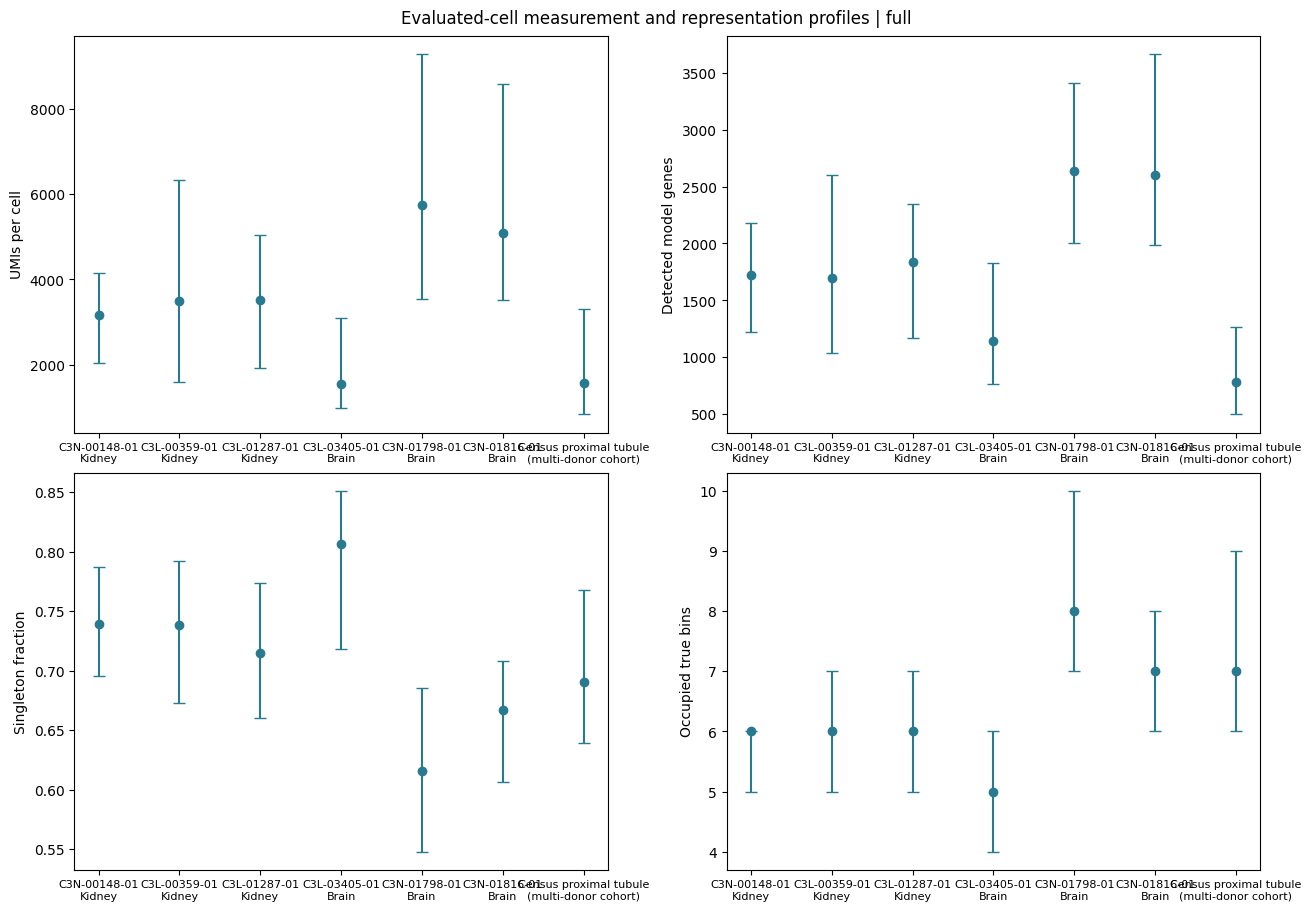

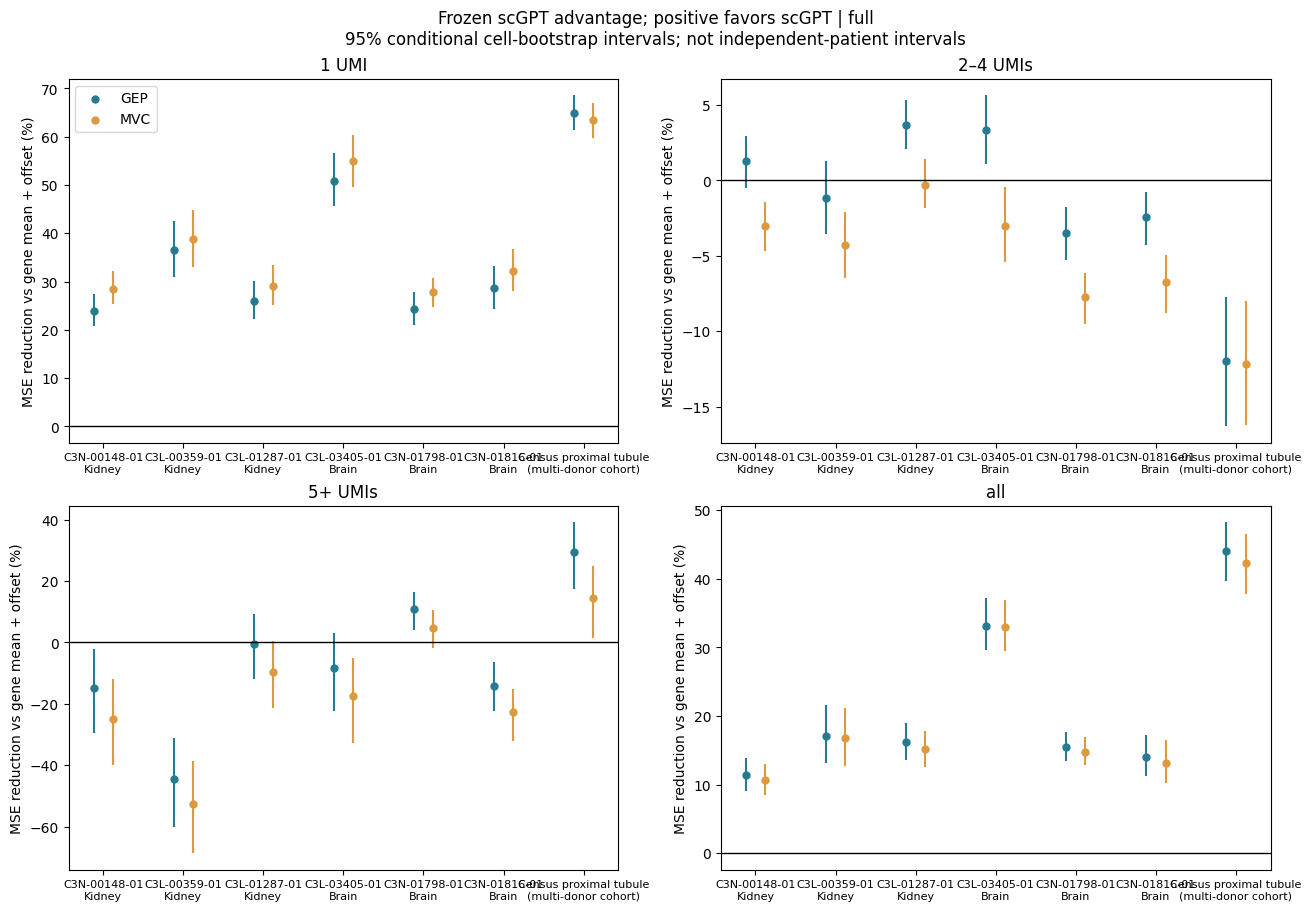

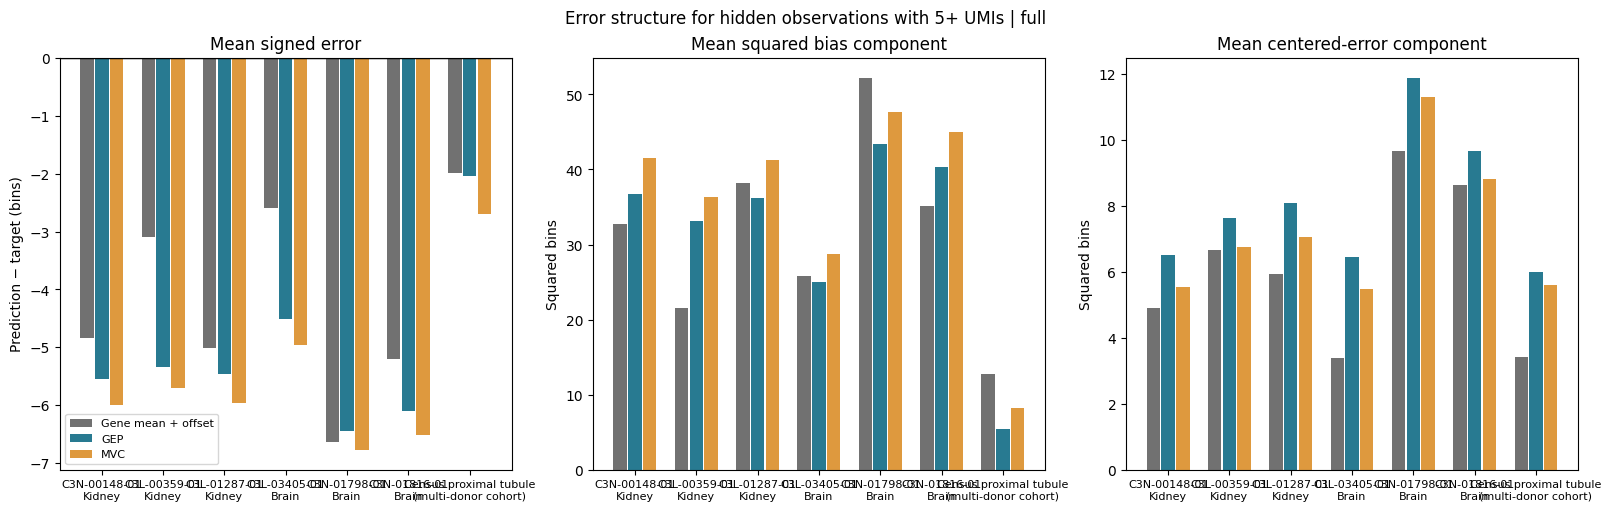

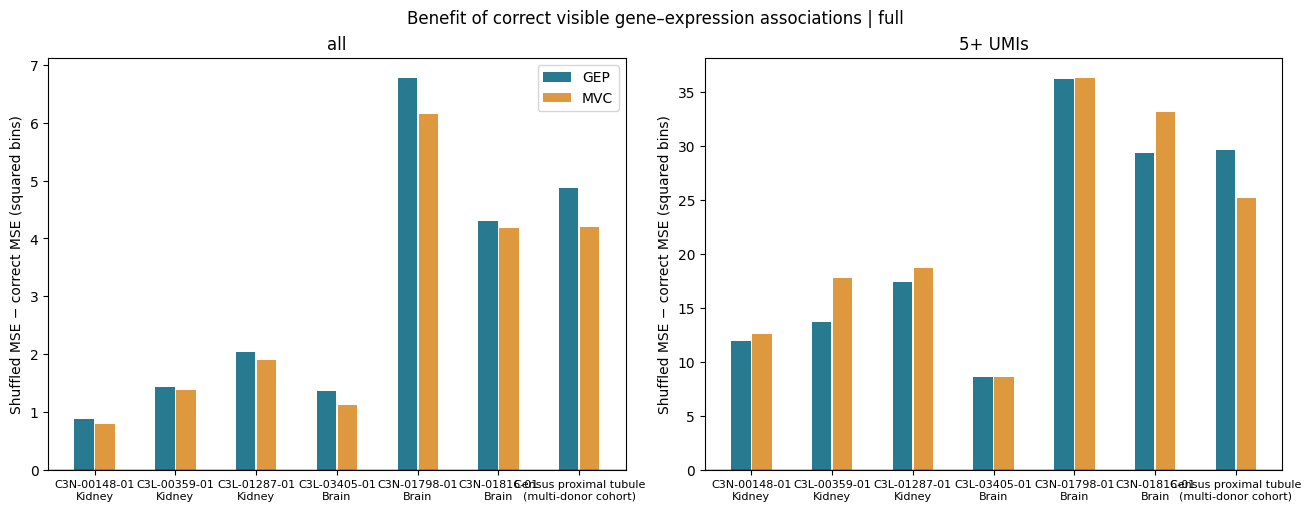

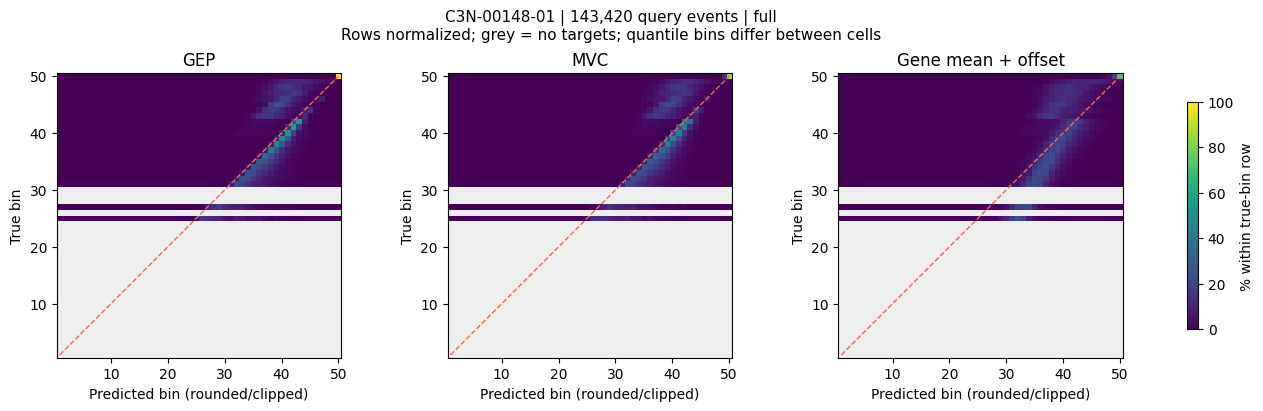

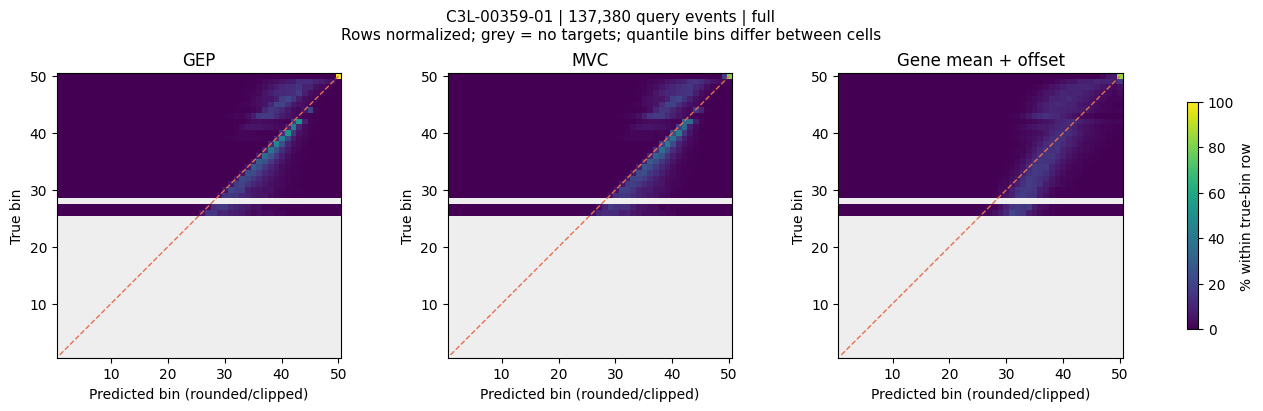

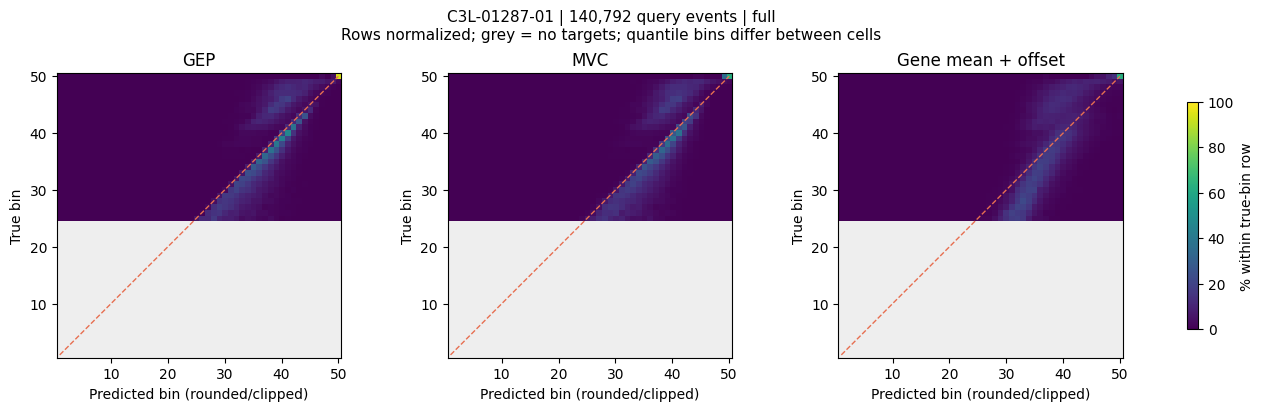

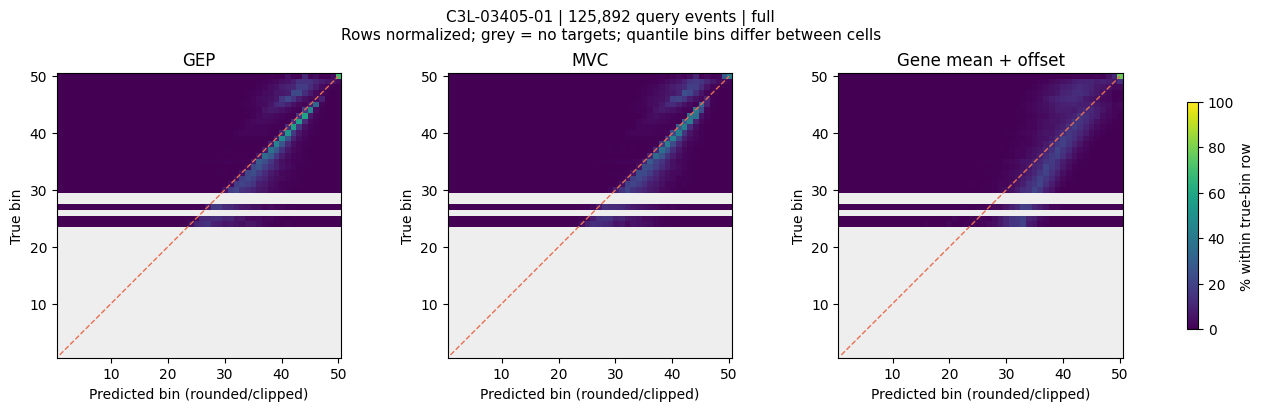

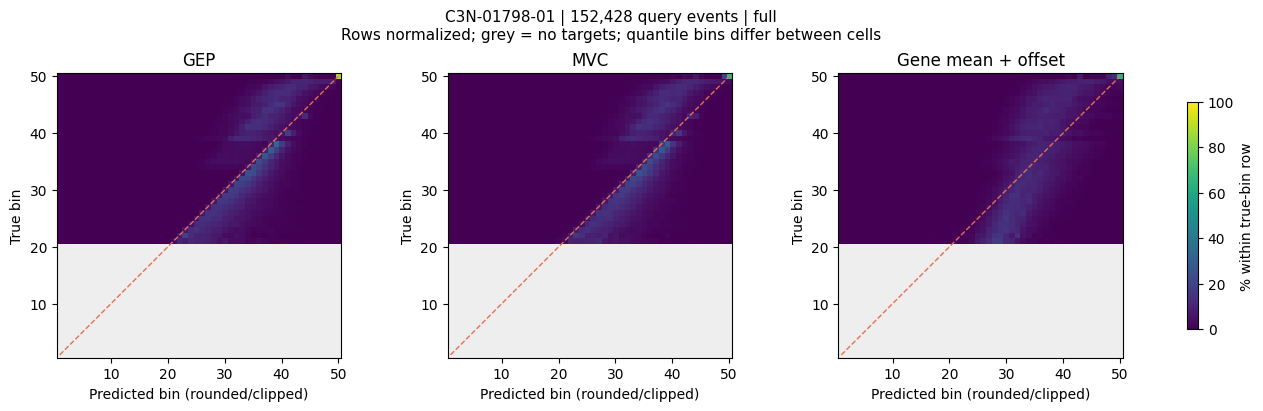

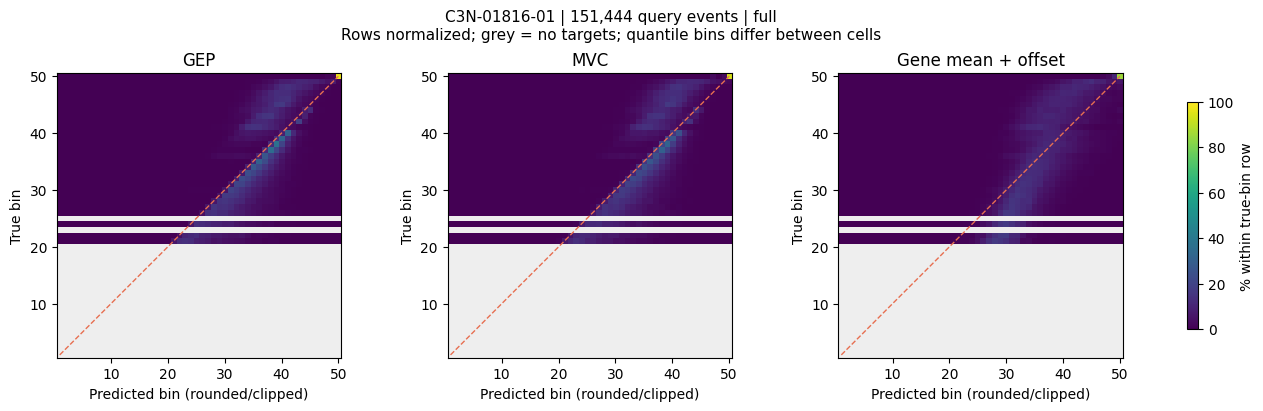

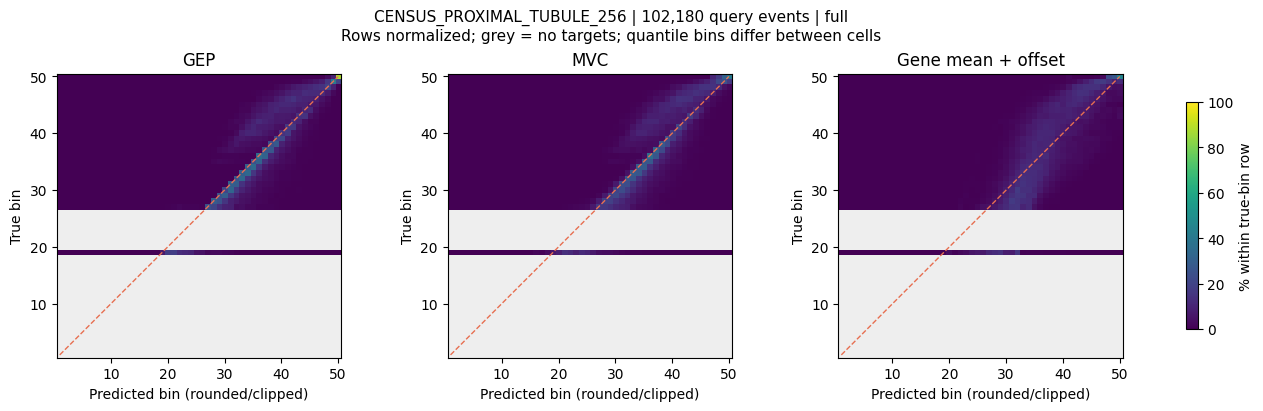

Figures: /home/akash1/scgpt-cna/report_benchmark/results/20261114T213609648407Z_full/figures


In [ ]:
# 9 — Report figures. No inference; can also run directly after reload cell 10.
import matplotlib.pyplot as plt
from textwrap import fill
FIGURES=RUN_DIR/"figures"
FIGURES.mkdir(exist_ok=True)
order=unit_info.sample_id.tolist()
short={sid:("Census proximal tubule\n(multi-donor cohort)" if sid.startswith("CENSUS") else sid+"\n"+unit_info.set_index("sample_id").loc[sid,"tissue"]) for sid in order}
colors={"GEP":"#287A91","MVC":"#DE993E",BASELINE:"#717171"}
labels={"GEP":"GEP","MVC":"MVC",BASELINE:"Gene mean + offset"}

def save_report_figure(fig,name):
    fig.savefig(FIGURES/f"{name}.png",dpi=220,bbox_inches="tight")
    fig.savefig(FIGURES/f"{name}.pdf",bbox_inches="tight")
    plt.show()
    plt.close(fig)

# Figure 1: evaluated-cell profiles, medians and IQRs (not confidence intervals).
metrics_to_plot=[("total_counts","UMIs per cell"),("model_detected_genes","Detected model genes"),
                 ("model_fraction_count_one","Singleton fraction"),("occupied_bins","Occupied true bins")]
fig,axes=plt.subplots(2,2,figsize=(13,9),constrained_layout=True)
for ax,(metric,label) in zip(axes.flat,metrics_to_plot):
    part=profiles.loc[(profiles.population=="evaluated")&(profiles.metric==metric)].set_index("sample_id").reindex(order)
    x=np.arange(len(order))
    ax.errorbar(x,part["median"],yerr=np.vstack([part["median"]-part.q25,part.q75-part["median"]]),fmt="o",capsize=4,color="#287A91")
    ax.set(xticks=x,xticklabels=[short[s] for s in order],ylabel=label)
    ax.tick_params(axis="x",labelsize=8)
fig.suptitle(f"Evaluated-cell measurement and representation profiles | {MODE}")
save_report_figure(fig,"01_data_profiles")

# Figure 2: paired advantage over the strong baseline, conditional cell intervals.
fig,axes=plt.subplots(2,2,figsize=(13,9),constrained_layout=True)
for ax,group in zip(axes.flat,COUNT_GROUPS):
    for head,offset in [("GEP",-.12),("MVC",.12)]:
        part=paired.loc[(paired.count_group==group)&(paired['head']==head)].set_index("sample_id").reindex(order)
        x=np.arange(len(order))+offset
        ax.vlines(x,part.percent_low,part.percent_high,color=colors[head],lw=1.5)
        ax.scatter(x,part.percent_MSE_reduction,color=colors[head],label=head,s=25)
    ax.axhline(0,color="black",lw=1)
    ax.set(title=group,ylabel="MSE reduction vs gene mean + offset (%)",xticks=np.arange(len(order)),xticklabels=[short[s] for s in order])
    ax.tick_params(axis="x",labelsize=8)
axes[0,0].legend()
fig.suptitle(f"Frozen scGPT advantage; positive favors scGPT | {MODE}\n95% conditional cell-bootstrap intervals; not independent-patient intervals",fontsize=12)
save_report_figure(fig,"02_paired_relative_performance")

# Figure 3: signed residuals and decomposition in the 5+ observed-UMI group.
fig,axes=plt.subplots(1,3,figsize=(16,5),constrained_layout=True)
for j,method in enumerate([BASELINE,*HEADS]):
    part=decomposition.loc[(decomposition.count_group=="5+ UMIs")&(decomposition.method==method)].set_index("sample_id").reindex(order)
    x=np.arange(len(order))+(j-1)*.24
    axes[0].bar(x,part.mean_residual,width=.22,color=colors[method],label=labels[method])
    axes[1].bar(x,part.squared_bias,width=.22,color=colors[method])
    axes[2].bar(x,part.centered_MSE,width=.22,color=colors[method])
for ax,title,ylabel in zip(axes,["Mean signed error","Mean squared bias component","Mean centered-error component"],["Prediction − target (bins)","Squared bins","Squared bins"]):
    ax.set(title=title,ylabel=ylabel,xticks=np.arange(len(order)),xticklabels=[short[s] for s in order])
    ax.tick_params(axis="x",labelsize=8)
axes[0].axhline(0,color="black",lw=1)
axes[0].legend(fontsize=8)
fig.suptitle(f"Error structure for hidden observations with 5+ UMIs | {MODE}")
save_report_figure(fig,"03_higher_count_error_components")

# Figure 4: correct-vs-shuffled context, same queries. Not an estimate of biological signal fraction.
fig,axes=plt.subplots(1,2,figsize=(13,5),constrained_layout=True)
for ax,group in zip(axes,["all","5+ UMIs"]):
    for head,offset in [("GEP",-.13),("MVC",.13)]:
        part=paired.loc[(paired.count_group==group)&(paired['head']==head)].set_index("sample_id").reindex(order)
        ax.bar(np.arange(len(order))+offset,part.context_gain,width=.24,color=colors[head],label=head)
    ax.axhline(0,color="black",lw=1)
    ax.set(title=group,ylabel="Shuffled MSE − correct MSE (squared bins)",xticks=np.arange(len(order)),xticklabels=[short[s] for s in order])
    ax.tick_params(axis="x",labelsize=8)
axes[0].legend()
fig.suptitle(f"Benefit of correct visible gene–expression associations | {MODE}")
save_report_figure(fig,"04_context_control")

# Appendix: row-normalized all-query regression-error maps, one unit at a time.
# Full numerical count matrices are saved too; each event is counted once per mask.
cmap=plt.get_cmap("viridis").copy();cmap.set_bad("#eeeeee")
for sid in order:
    q=pd.concat([pd.read_csv(RUN_DIR/sid/f"query_predictions_mask{s}.csv.gz",
          usecols=["target_bin",*HEADS,BASELINE]) for s in MASK_SEEDS],ignore_index=True)
    y=q.target_bin.to_numpy(dtype=int)
    fig,axes=plt.subplots(1,3,figsize=(13,4),constrained_layout=True)
    for ax,method in zip(axes,[*HEADS,BASELINE]):
        rounded=np.clip(np.floor(q[method].to_numpy()+.5),1,50).astype(int)
        cm=np.bincount((y-1)*50+rounded-1,minlength=2500).reshape(50,50)
        support=cm.sum(axis=1)
        pct=np.full((50,50),np.nan)
        np.divide(100*cm,support[:,None],out=pct,where=support[:,None]>0)
        image=ax.imshow(np.ma.masked_invalid(pct),origin="lower",extent=[.5,50.5,.5,50.5],vmin=0,vmax=100,cmap=cmap,interpolation="nearest")
        ax.plot([1,50],[1,50],"--",color="#e76f51",lw=1)
        ax.set(title=labels[method],xlabel="Predicted bin (rounded/clipped)",ylabel="True bin")
        pd.DataFrame(cm,index=np.arange(1,51),columns=np.arange(1,51)).to_csv(FIGURES/f"heatmap_counts_{sid}_{method}.csv",index_label="true_bin")
    fig.colorbar(image,ax=axes,label="% within true-bin row",shrink=.8)
    fig.suptitle(f"{sid} | {len(q):,} query events | {MODE}\nRows normalized; grey = no targets; quantile bins differ between cells",fontsize=11)
    save_report_figure(fig,f"appendix_heatmaps_{sid}")
print("Figures:",FIGURES)


In [ ]:
# 10 — Standalone reload. Run this cell alone, then cell 9; no model or raw data needed.
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display
ROOT=Path.home()/"scgpt-cna"
MODE_TO_LOAD="full"  # Use "pilot" for the initial check.
RUN_TO_LOAD=None      # Or an explicit timestamped directory.
RESULTS_ROOT=ROOT/"report_benchmark/results"
RUN_DIR=Path(RUN_TO_LOAD) if RUN_TO_LOAD is not None else Path(json.loads((RESULTS_ROOT/f"latest_{MODE_TO_LOAD}_run.json").read_text())["run_dir"])
m=json.loads((RUN_DIR/"run_manifest.json").read_text())
MODE=m["mode"];MASK_SEEDS=m["mask_seeds"]
BASELINE="gene_mean_plus_offset";HEADS=["GEP","MVC"]
COUNT_GROUPS=["1 UMI","2–4 UMIs","5+ UMIs","all"]
all_summary=pd.read_csv(RUN_DIR/"all_specimens_summary.csv")
all_per_cell=pd.read_csv(RUN_DIR/"all_specimens_cell_scores.csv")
profiles=pd.read_csv(RUN_DIR/"measurement_profiles.csv")
paired=pd.read_csv(RUN_DIR/"paired_comparisons.csv")
decomposition=pd.read_csv(RUN_DIR/"error_decomposition.csv")
unit_info=pd.read_csv(RUN_DIR/"evaluation_unit_metadata.csv")
query_coverage=pd.read_csv(RUN_DIR/"query_coverage.csv")
coverage_summary=pd.read_csv(RUN_DIR/"coverage_summary.csv")
print("Loaded saved evidence:",RUN_DIR)
display(all_summary.query("count_group == 'all'").round(3))
print("Cell 9 can regenerate every figure; no inference is performed.")


Loaded saved evidence: /home/akash1/scgpt-cna/report_benchmark/results/20261114T213609648407Z_full


/tmp/ipykernel_2031616/2986700178.py:17: DtypeWarning: Columns (50,51,52,53,54,55,56,59) have mixed types. Specify dtype option on import or set low_memory=False.
  all_per_cell=pd.read_csv(RUN_DIR/"all_specimens_cell_scores.csv")


,sample_id,case_id,count_group,method,n_cells,mean_MSE,median_MSE,mean_MAE,mean_MSE_gain,cells_beating_baseline,mean_baseline_MSE,percent_MSE_reduction,tissue,diagnosis,source,evaluation_unit
24,C3N-00148-01,C3N-00148,all,GEP,128,14.450,14.094,2.908,1.869,95,16.318,11.450,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
25,C3N-00148-01,C3N-00148,all,GEP_shuffled,128,15.330,14.896,3.282,0.989,81,16.318,6.059,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
26,C3N-00148-01,C3N-00148,all,MVC,128,14.577,14.297,2.872,1.742,94,16.318,10.673,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
27,C3N-00148-01,C3N-00148,all,MVC_shuffled,128,15.362,14.967,3.207,0.956,81,16.318,5.860,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
28,C3N-00148-01,C3N-00148,all,gene_mean,128,21.272,18.399,3.780,-4.954,8,16.318,-30.356,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
29,C3N-00148-01,C3N-00148,all,gene_mean_plus_offset,128,16.318,15.300,3.187,0.000,0,16.318,0.000,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
30,C3N-00148-01,C3N-00148,all,reference_constant,128,23.349,19.484,4.004,-7.030,1,16.318,-43.081,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
31,C3N-00148-01,C3N-00148,all,visible_mean,128,17.931,17.163,3.479,-1.612,32,16.318,-9.880,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
56,C3L-00359-01,C3L-00359,all,GEP,128,15.007,13.520,2.917,3.101,94,18.108,17.127,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
57,C3L-00359-01,C3L-00359,all,GEP_shuffled,128,16.437,14.862,3.401,1.672,76,18.108,9.231,Kidney,"Renal cell carcinoma, NOS",Lab,specimen


Cell 9 can regenerate every figure; no inference is performed.


### 2. Explaining errors 

Do the cells where scGPT loses have anything in common?

In [ ]:
# 1 — Reload the completed benchmark and construct one paired row per cell/head/group.
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.home() / "scgpt-cna"
MODE_TO_LOAD = "full"  # Use "pilot" only for a preliminary check.
RUN_TO_LOAD = None     # Or Path("/absolute/path/to/report_benchmark/results/timestamp_full")
if RUN_TO_LOAD is None:
    pointer = ROOT / "report_benchmark/results" / f"latest_{MODE_TO_LOAD}_run.json"
    assert pointer.is_file(), "No completed benchmark pointer. Set RUN_TO_LOAD or complete benchmark cell 8."
    P1_RUN = Path(json.loads(pointer.read_text())["run_dir"])
else:
    P1_RUN = Path(RUN_TO_LOAD)
P1_MANIFEST = json.loads((P1_RUN/"run_manifest.json").read_text())
P1_MODE = P1_MANIFEST["mode"]
if P1_MODE != "full":
    print("PILOT DATA: descriptive execution check, not final report evidence.")
P1_META = pd.read_csv(P1_RUN/"evaluation_unit_metadata.csv")
P1_SCORES = pd.read_csv(P1_RUN/"all_specimens_cell_scores.csv")
P1_MASKS = list(map(int,P1_MANIFEST["mask_seeds"]))
P1_GROUPS = ["all", "1 UMI", "2–4 UMIs", "5+ UMIs"]
P1_HEADS = ["GEP", "MVC"]
P1_BASELINE = "gene_mean_plus_offset"
P1_KEYS = ["sample_id", "cell_id", "count_group"]
assert not P1_SCORES.duplicated(P1_KEYS+["method"]).any()
assert P1_META.sample_id.is_unique
required = [*P1_KEYS,"method","MSE","MAE","n_masks","model_detected_genes",
    "total_counts","model_fraction_count_one","visible_gene_fraction","target_std",
    "gene_baseline_support_fraction"]
assert set(required).issubset(P1_SCORES), "Use the new report benchmark exports, not the older multicase summaries."
baseline = P1_SCORES.loc[P1_SCORES.method.eq(P1_BASELINE),
    P1_KEYS+["MSE","MAE","n_masks"]].rename(columns={"MSE":"baseline_MSE","MAE":"baseline_MAE","n_masks":"baseline_n_masks"})
P1 = P1_SCORES.loc[P1_SCORES.method.isin(P1_HEADS)].copy()
# baseline_MSE already exists in the original score file: validate and replace explicitly.
P1 = P1.rename(columns={"baseline_MSE":"previous_baseline_MSE"})
P1 = P1.merge(baseline,on=P1_KEYS,validate="many_to_one",how="left")
assert P1.baseline_MSE.notna().all()
assert P1.n_masks.eq(P1.baseline_n_masks).all()
if "previous_baseline_MSE" in P1:
    np.testing.assert_allclose(P1.previous_baseline_MSE,P1.baseline_MSE)
P1["gain"] = P1.baseline_MSE-P1.MSE
if "MSE_gain" in P1:
    np.testing.assert_allclose(P1.gain,P1.MSE_gain,atol=1e-7)
assert np.isfinite(P1[["MSE","baseline_MSE","gain"]].to_numpy()).all()
assert P1.loc[P1.count_group.eq("all"),"n_masks"].eq(len(P1_MASKS)).all()
# Do not merge labels from mutable notebook globals or assume all cells in a tumor are malignant.
P1 = P1.drop(columns=[c for c in ["tissue","diagnosis","source","evaluation_unit"] if c in P1])
P1 = P1.merge(P1_META[["sample_id","tissue","diagnosis","source","evaluation_unit"]],on="sample_id",validate="many_to_one")
P1_ORDER = P1_META.sample_id.tolist()
P1_OUT = P1_RUN / "priority1" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
P1_OUT.mkdir(parents=True,exist_ok=False)
P1.to_csv(P1_OUT/"paired_cell_diagnostics.csv",index=False)
(P1_OUT/"source_manifest.json").write_text(json.dumps({"benchmark_run":str(P1_RUN),"mode":P1_MODE,
    "benchmark_manifest_sha256":hashlib.sha256((P1_RUN/"run_manifest.json").read_bytes()).hexdigest(),
    "scores_sha256":hashlib.sha256((P1_RUN/"all_specimens_cell_scores.csv").read_bytes()).hexdigest(),
    "weighting":"Each row is one cell/head/group, masks averaged first; no cross-specimen pooling"},indent=2))
print("Loaded:",P1_RUN)
print("Saving diagnostics:",P1_OUT)
display(P1.groupby(["sample_id","count_group","method"],as_index=False).agg(
    n_cells=("cell_id","nunique"),mean_model_MSE=("MSE","mean"),mean_baseline_MSE=("baseline_MSE","mean"),mean_gain=("gain","mean")).round(3))


/tmp/ipykernel_881490/2972682596.py:24: DtypeWarning: Columns (50,51,52,53,54,55,56,59) have mixed types. Specify dtype option on import or set low_memory=False.
  P1_SCORES = pd.read_csv(P1_RUN/"all_specimens_cell_scores.csv")


Loaded: /home/akash1/scgpt-cna/report_benchmark/results/20261114T213609648407Z_full
Saving diagnostics: /home/akash1/scgpt-cna/report_benchmark/results/20261114T213609648407Z_full/priority1/20261116T190952283403Z


,sample_id,count_group,method,n_cells,mean_model_MSE,mean_baseline_MSE,mean_gain
0,C3L-00359-01,1 UMI,GEP,128,8.307,13.084,4.777
1,C3L-00359-01,1 UMI,MVC,128,8.003,13.084,5.081
2,C3L-00359-01,2–4 UMIs,GEP,128,30.540,30.192,-0.348
3,C3L-00359-01,2–4 UMIs,MVC,128,31.489,30.192,-1.297
4,C3L-00359-01,5+ UMIs,GEP,128,40.734,28.189,-12.545
5,C3L-00359-01,5+ UMIs,MVC,128,43.080,28.189,-14.891
6,C3L-00359-01,all,GEP,128,15.007,18.108,3.101
7,C3L-00359-01,all,MVC,128,15.077,18.108,3.031
8,C3L-01287-01,1 UMI,GEP,128,10.018,13.536,3.518
9,C3L-01287-01,1 UMI,MVC,128,9.594,13.536,3.942


In [ ]:
# 2 — Adjustable diagnostic figure. Rerun this cell for another head/group/property.
P1_HEAD = "GEP"
P1_GROUP = "all"  # "1 UMI", "2–4 UMIs", "5+ UMIs"
P1_FEATURE = "model_detected_genes"
# Other choices: visible_gene_fraction, model_fraction_count_one, total_counts,
#               target_std, gene_baseline_support_fraction
P1_SAMPLES = None  # None = all; or ["C3N-00148-01", "CENSUS_PROXIMAL_TUBULE_256"]

P1_FEATURE_LABELS = {
 "model_detected_genes":"Detected model genes",
 "visible_gene_fraction":"Fraction of detected model genes visible",
 "model_fraction_count_one":"Fraction of detected model genes with 1 UMI",
 "total_counts":"Observed total UMIs",
 "target_std":"Mean within-mask target SD (bins)",
 "gene_baseline_support_fraction":"Mean fraction of queries detected in reference cells",
}
assert P1_HEAD in P1_HEADS and P1_GROUP in P1_GROUPS and P1_FEATURE in P1_FEATURE_LABELS
chosen = P1_ORDER if P1_SAMPLES is None else P1_SAMPLES
assert set(chosen).issubset(P1_ORDER)
fig,axes = plt.subplots(len(chosen),3,figsize=(14,max(3,2.5*len(chosen))),squeeze=False,constrained_layout=True)
p1_trends=[]
for row,sid in enumerate(chosen):
    part=P1.loc[P1.sample_id.eq(sid)&P1.method.eq(P1_HEAD)&P1.count_group.eq(P1_GROUP)].copy()
    part=part.loc[np.isfinite(pd.to_numeric(part[P1_FEATURE],errors="coerce"))]
    meta=P1_META.set_index("sample_id").loc[sid]
    for col,(outcome,label,color) in enumerate([
        ("MSE",f"{P1_HEAD} MSE","#287A91"),
        ("baseline_MSE","Gene mean + offset MSE","#717171"),
        ("gain","Baseline MSE − model MSE","#287A91")]):
        ax=axes[row,col]
        ax.scatter(part[P1_FEATURE],part[outcome],s=14,alpha=.45,color=color,edgecolors="none")
        if len(part)>=8 and part[P1_FEATURE].nunique()>=4:
            buckets=pd.qcut(part[P1_FEATURE],q=4,duplicates="drop")
            trend=part.groupby(buckets,observed=True).agg(x=(P1_FEATURE,"mean"),y=(outcome,"mean"),n_cells=("cell_id","size"))
            ax.plot(trend.x,trend.y,"D-",color="#D97732",ms=5,lw=1.2)
            p1_trends.append(trend.reset_index(drop=True).assign(sample_id=sid,outcome=outcome,feature=P1_FEATURE,head=P1_HEAD,count_group=P1_GROUP))
        if outcome=="gain":ax.axhline(0,color="black",lw=1)
        ax.set(xlabel=P1_FEATURE_LABELS[P1_FEATURE],ylabel=label)
        ax.set_title(f"{sid} | {meta['tissue']} | n={len(part)}",fontsize=9)
        if not len(part):ax.text(.5,.5,"No contributing cells",ha="center",transform=ax.transAxes)
for row_axes in axes:
    limits=[ax.get_ylim() for ax in row_axes[:2]]
    common=(min(p[0] for p in limits),max(p[1] for p in limits))
    for ax in row_axes[:2]:ax.set_ylim(common)
fig.suptitle(f"Within-unit diagnostics | {P1_HEAD} | {P1_GROUP} | {P1_MODE}\nEach dot = one cell; diamonds = x-group means; positive gain favors scGPT",fontsize=12)
slug={"all":"all","1 UMI":"1UMI","2–4 UMIs":"2to4","5+ UMIs":"5plus"}[P1_GROUP]
tag=f"{P1_HEAD}_{slug}_{P1_FEATURE}"
fig.savefig(P1_OUT/f"diagnostic_{tag}.png",dpi=200,bbox_inches="tight")
fig.savefig(P1_OUT/f"diagnostic_{tag}.pdf",bbox_inches="tight")
plt.show();plt.close(fig)
if p1_trends:pd.concat(p1_trends,ignore_index=True).to_csv(P1_OUT/f"descriptive_trends_{tag}.csv",index=False)
print("Read all three columns together: does model error change, baseline error change, or both?")
print("These are observational comparisons across cells; they do not isolate a context effect.")


NameError: name 'P1_HEADS' is not defined

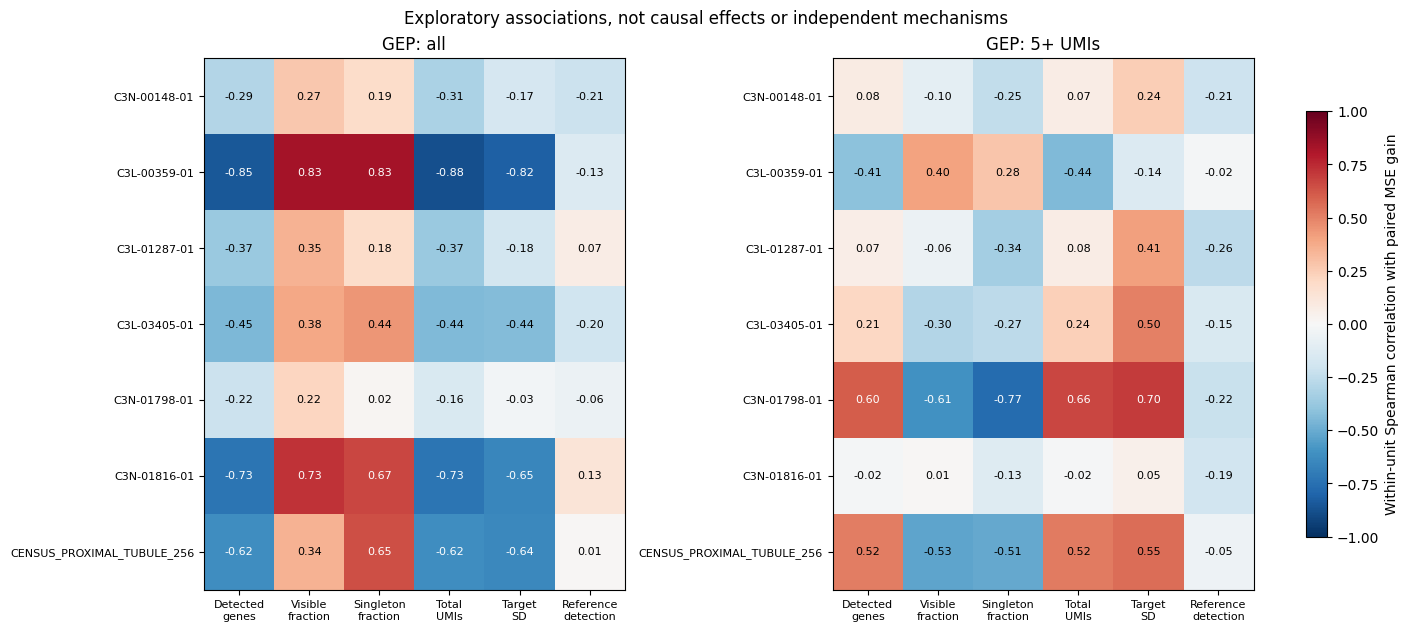

,sample_id,head,count_group,feature,outcome,n_cells,n_unique_x,spearman_rho,status
56,C3L-00359-01,GEP,all,model_detected_genes,gain,128,126,-0.847,descriptive
59,C3L-00359-01,GEP,all,visible_gene_fraction,gain,128,117,0.834,descriptive
62,C3L-00359-01,GEP,all,model_fraction_count_one,gain,128,127,0.833,descriptive
65,C3L-00359-01,GEP,all,total_counts,gain,128,127,-0.877,descriptive
68,C3L-00359-01,GEP,all,target_std,gain,128,128,-0.819,descriptive
71,C3L-00359-01,GEP,all,gene_baseline_support_fraction,gain,128,60,-0.134,descriptive
200,C3L-01287-01,GEP,all,model_detected_genes,gain,128,125,-0.374,descriptive
203,C3L-01287-01,GEP,all,visible_gene_fraction,gain,128,114,0.349,descriptive
206,C3L-01287-01,GEP,all,model_fraction_count_one,gain,128,128,0.183,descriptive
209,C3L-01287-01,GEP,all,total_counts,gain,128,127,-0.370,descriptive


Detected genes and visible fraction largely describe the same fixed-budget constraint.
Target SD vs MSE can be mechanical. Grey = constant/insufficient, not zero association.


In [ ]:
# 3 — Compact associations across all properties/groups; one correlation per unit, never pooled.
p1_associations=[]
for (sid,head,group),part in P1.groupby(["sample_id","method","count_group"]):
    for feature in P1_FEATURE_LABELS:
        for outcome in ["MSE","baseline_MSE","gain"]:
            finite=part[[feature,outcome]].replace([np.inf,-np.inf],np.nan).dropna()
            valid=len(finite)>=8 and finite[feature].nunique()>1 and finite[outcome].nunique()>1
            rho=finite[feature].rank().corr(finite[outcome].rank()) if valid else np.nan
            p1_associations.append({"sample_id":sid,"head":head,"count_group":group,"feature":feature,
                "outcome":outcome,"n_cells":len(finite),"n_unique_x":finite[feature].nunique(),
                "spearman_rho":rho,"status":"descriptive" if valid else "constant_or_insufficient"})
P1_ASSOCIATIONS=pd.DataFrame(p1_associations)
P1_ASSOCIATIONS.to_csv(P1_OUT/"within_unit_spearman.csv",index=False)
features=list(P1_FEATURE_LABELS)
fig,axes=plt.subplots(1,2,figsize=(14,max(4,len(P1_ORDER)*.6+2)),constrained_layout=True)
cmap=plt.get_cmap("RdBu_r").copy();cmap.set_bad("#eeeeee")
for ax,group in zip(axes,["all","5+ UMIs"]):
    part=P1_ASSOCIATIONS.loc[P1_ASSOCIATIONS['head'].eq(P1_HEAD)&P1_ASSOCIATIONS.count_group.eq(group)&P1_ASSOCIATIONS.outcome.eq("gain")]
    table=part.pivot(index="sample_id",columns="feature",values="spearman_rho").reindex(index=P1_ORDER,columns=features)
    im=ax.imshow(np.ma.masked_invalid(table.to_numpy()),vmin=-1,vmax=1,cmap=cmap,aspect="auto")
    ax.set(xticks=range(len(features)),xticklabels=["Detected\ngenes","Visible\nfraction","Singleton\nfraction","Total\nUMIs","Target\nSD","Reference\ndetection"],
           yticks=range(len(P1_ORDER)),yticklabels=P1_ORDER,title=f"{P1_HEAD}: {group}")
    ax.tick_params(labelsize=8)
    for i in range(len(table)):
        for j in range(len(features)):
            value=table.iloc[i,j]
            if np.isfinite(value):ax.text(j,i,f"{value:.2f}",ha="center",va="center",fontsize=8,color="white" if abs(value)>.6 else "black")
fig.colorbar(im,ax=axes,label="Within-unit Spearman correlation with paired MSE gain",shrink=.8)
fig.suptitle("Exploratory associations, not causal effects or independent mechanisms",fontsize=12)
fig.savefig(P1_OUT/f"gain_associations_{P1_HEAD}.png",dpi=220,bbox_inches="tight")
fig.savefig(P1_OUT/f"gain_associations_{P1_HEAD}.pdf",bbox_inches="tight")
plt.show();plt.close(fig)
display(P1_ASSOCIATIONS.loc[P1_ASSOCIATIONS['head'].eq(P1_HEAD)&P1_ASSOCIATIONS.count_group.eq("all")&P1_ASSOCIATIONS.outcome.eq("gain")].round(3))
print("Detected genes and visible fraction largely describe the same fixed-budget constraint.")
print("Target SD vs MSE can be mechanical. Grey = constant/insufficient, not zero association.")


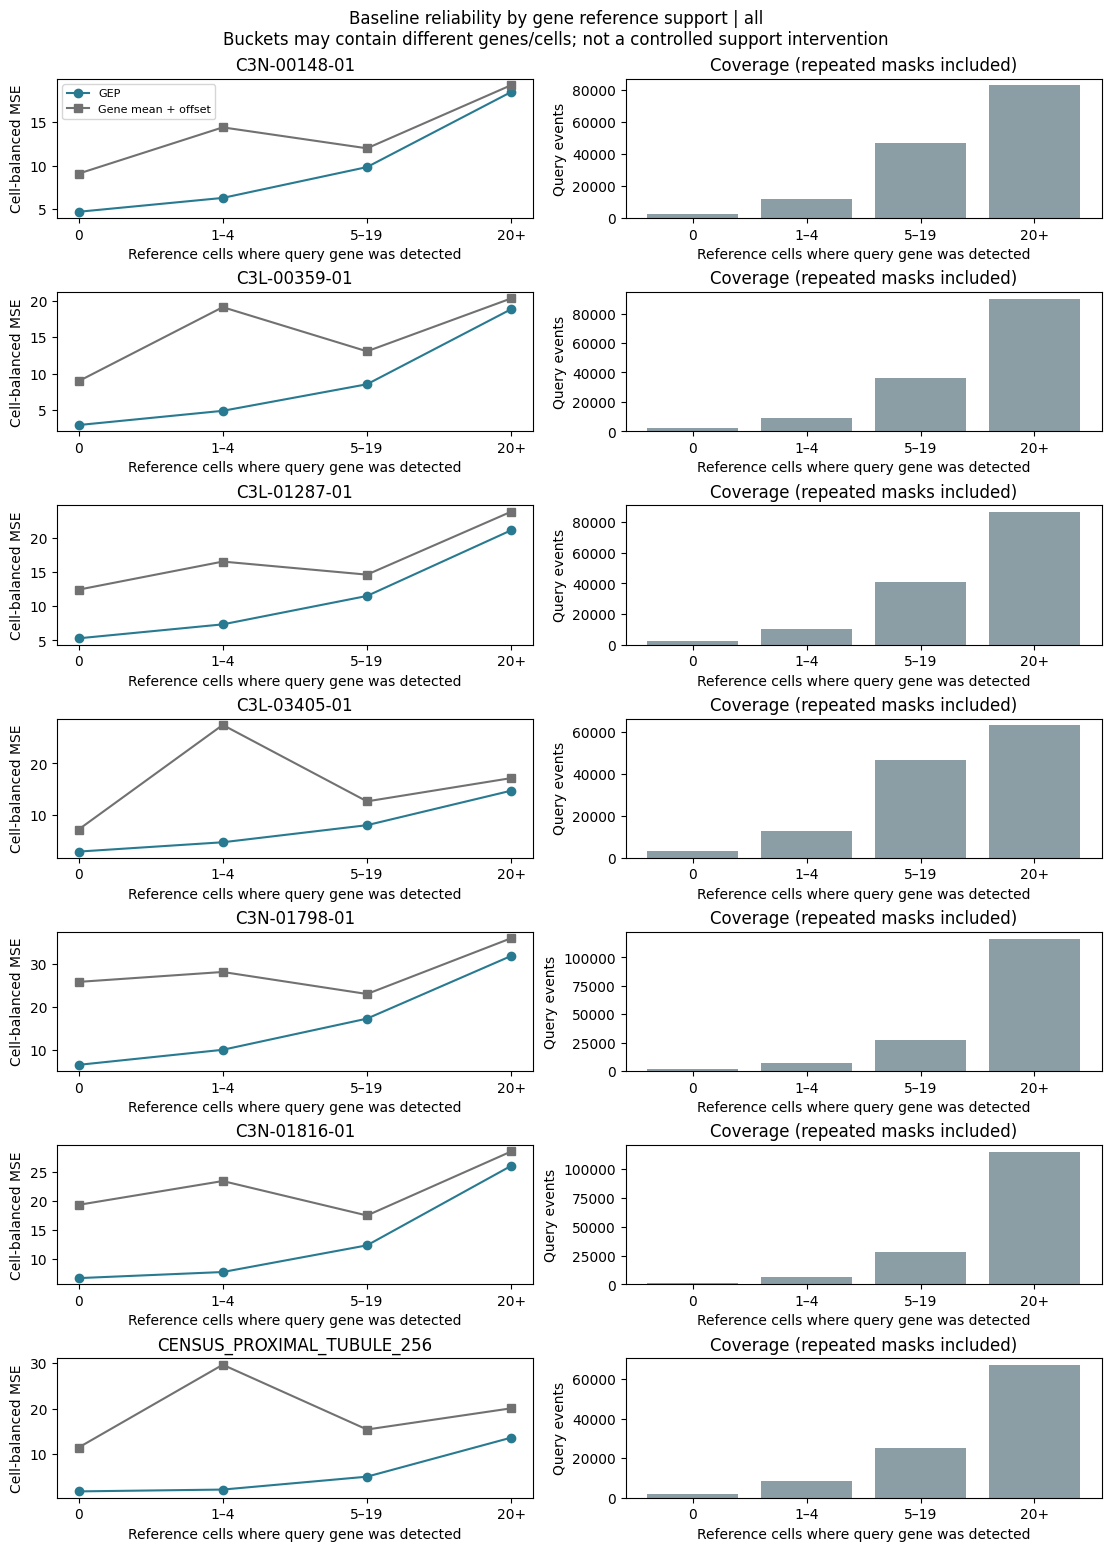

,sample_id,head,count_group,support_bucket,n_cells,n_query_events,unique_cell_gene_pairs,mean_masks_per_contributing_cell,cell_balanced_model_MSE,cell_balanced_baseline_MSE,cell_balanced_gain
0,C3N-00148-01,GEP,all,0,128,2659,2052,3.945,4.698,9.082,4.383
1,C3N-00148-01,GEP,all,1–4,128,11603,8946,4.000,6.293,14.404,8.111
2,C3N-00148-01,GEP,all,5–19,128,46554,35790,4.000,9.837,11.996,2.159
3,C3N-00148-01,GEP,all,20+,128,82604,63149,4.000,18.472,19.258,0.786
4,C3L-00359-01,GEP,all,0,128,2041,1593,3.914,2.961,8.965,6.005
5,C3L-00359-01,GEP,all,1–4,128,8893,6905,4.000,4.910,19.106,14.196
6,C3L-00359-01,GEP,all,5–19,128,36331,28444,4.000,8.547,13.059,4.511
7,C3L-00359-01,GEP,all,20+,128,90115,70174,4.000,18.830,20.304,1.475
8,C3L-01287-01,GEP,all,0,128,2570,2031,3.898,5.294,12.396,7.102
9,C3L-01287-01,GEP,all,1–4,128,10268,8034,4.000,7.331,16.497,9.166


0 = no detected reference observations; the gene mean falls back to the reference constant.
If a bucket is sparse, do not interpret its mean as a stable performance estimate.
All outputs: /home/akash1/scgpt-cna/report_benchmark/results/20261114T213609648407Z_full/priority1/20261116T190952283403Z


In [ ]:
# 4 — Does the gene baseline fail where a gene has little reference support?
# Uses saved query files; no raw-count loading or new predictions.
P1_SUPPORT_GROUP = "all"  # Rerun for "5+ UMIs" to examine that subgroup.
assert P1_SUPPORT_GROUP in P1_GROUPS
support_labels=["0","1–4","5–19","20+"]
p1_support_rows=[]
p1_support_provenance=[]
for sid in P1_ORDER:
    files=[P1_RUN/sid/f"query_predictions_mask{s}.csv.gz" for s in P1_MASKS]
    use=["cell_id","mask_seed","gene_token","original_umi","reference_support","target_bin",P1_HEAD,P1_BASELINE]
    frames=[]
    for seed,path in zip(P1_MASKS,files):
        frame=pd.read_csv(path,usecols=use)
        assert frame.mask_seed.eq(seed).all()
        frames.append(frame)
        p1_support_provenance.append({"path":str(path),"sha256":hashlib.sha256(path.read_bytes()).hexdigest()})
    q=pd.concat(frames,ignore_index=True)
    assert not q.duplicated(["cell_id","mask_seed","gene_token"]).any()
    if P1_SUPPORT_GROUP=="1 UMI":q=q.loc[q.original_umi.eq(1)]
    elif P1_SUPPORT_GROUP=="2–4 UMIs":q=q.loc[q.original_umi.between(2,4)]
    elif P1_SUPPORT_GROUP=="5+ UMIs":q=q.loc[q.original_umi.ge(5)]
    assert q.reference_support.between(0,P1_MANIFEST["n_reference"]).all()
    q=q.copy()
    q["support_bucket"]=pd.cut(q.reference_support,[-.5,.5,4.5,19.5,np.inf],labels=support_labels)
    q["model_sq_error"]=(q[P1_HEAD]-q.target_bin)**2
    q["baseline_sq_error"]=(q[P1_BASELINE]-q.target_bin)**2
    losses=q.groupby(["cell_id","mask_seed","support_bucket"],observed=True)[["model_sq_error","baseline_sq_error"]].mean()
    by_cell=losses.groupby(["cell_id","support_bucket"],observed=True).mean().reset_index()
    for bucket in support_labels:
        part=by_cell.loc[by_cell.support_bucket.eq(bucket)]
        events=q.loc[q.support_bucket.eq(bucket)]
        p1_support_rows.append({"sample_id":sid,"head":P1_HEAD,"count_group":P1_SUPPORT_GROUP,
            "support_bucket":bucket,"n_cells":len(part),"n_query_events":len(events),
            "unique_cell_gene_pairs":len(events[["cell_id","gene_token"]].drop_duplicates()),
            "mean_masks_per_contributing_cell":events.groupby("cell_id").mask_seed.nunique().mean(),
            "cell_balanced_model_MSE":part.model_sq_error.mean(),"cell_balanced_baseline_MSE":part.baseline_sq_error.mean(),
            "cell_balanced_gain":(part.baseline_sq_error-part.model_sq_error).mean()})
P1_SUPPORT=pd.DataFrame(p1_support_rows)
support_slug={"all":"all","1 UMI":"1UMI","2–4 UMIs":"2to4","5+ UMIs":"5plus"}[P1_SUPPORT_GROUP]
P1_SUPPORT.to_csv(P1_OUT/f"reference_support_{P1_HEAD}_{support_slug}.csv",index=False)
(P1_OUT/f"query_sources_{P1_HEAD}_{support_slug}.json").write_text(json.dumps(p1_support_provenance,indent=2))
fig,axes=plt.subplots(len(P1_ORDER),2,figsize=(11,max(3,len(P1_ORDER)*2.2)),squeeze=False,constrained_layout=True)
for i,sid in enumerate(P1_ORDER):
    part=P1_SUPPORT.loc[P1_SUPPORT.sample_id.eq(sid)].set_index("support_bucket").reindex(support_labels)
    x=np.arange(4)
    axes[i,0].plot(x,part.cell_balanced_model_MSE,"o-",label=P1_HEAD,color="#287A91")
    axes[i,0].plot(x,part.cell_balanced_baseline_MSE,"s-",label="Gene mean + offset",color="#717171")
    axes[i,0].set(ylabel="Cell-balanced MSE",title=sid)
    axes[i,1].bar(x,part.n_query_events,color="#8b9da5")
    axes[i,1].set(ylabel="Query events",title="Coverage (repeated masks included)")
    for ax in axes[i]:ax.set(xticks=x,xticklabels=support_labels,xlabel="Reference cells where query gene was detected")
axes[0,0].legend(fontsize=8)
fig.suptitle(f"Baseline reliability by gene reference support | {P1_SUPPORT_GROUP}\nBuckets may contain different genes/cells; not a controlled support intervention",fontsize=12)
fig.savefig(P1_OUT/f"reference_support_{P1_HEAD}_{support_slug}.png",dpi=200,bbox_inches="tight")
fig.savefig(P1_OUT/f"reference_support_{P1_HEAD}_{support_slug}.pdf",bbox_inches="tight")
plt.show();plt.close(fig)
display(P1_SUPPORT.round(3))
print("0 = no detected reference observations; the gene mean falls back to the reference constant.")
print("If a bucket is sparse, do not interpret its mean as a stable performance estimate.")
print("All outputs:",P1_OUT)


### 3. Context Variation and Thinning Experiment


In [ ]:
# 1 — Configuration and the completed parent benchmark.
from pathlib import Path
from datetime import datetime, timezone
import gc,gzip,hashlib,importlib.util,importlib.metadata,json,platform,sys,time
import numpy as np
import pandas as pd
import anndata as ad
from scipy import sparse
from scipy.io import mmread
from threadpoolctl import threadpool_limits
import torch
from IPython.display import display
ROOT=Path.home()/"scgpt-cna"
LAB_ROOT=Path("/home/akash1/projects/rrg-tperkins/dgladish/Projects/MSc/benchmarking_spatial_scale")
META=LAB_ROOT/"metadata/sample_md.tsv"
GDC_ROOT=LAB_ROOT/"GDC-data"
MODEL=ROOT/"models/whole-human"
HELPER=ROOT/"notebooks/scgpt_session/scgpt_session.py"
HISTORICAL=ROOT/"sanity_check/reference_4068d67/scgpt"
DATA=CENSUS_ANNOTATION=ROOT/"sanity_check/data/census_proximal_tubule_256/reference_raw.h5ad"
COHORT_ID="CENSUS_PROXIMAL_TUBULE_256"
PARENT_RUN=None  # Or Path(".../report_benchmark/results/timestamp_full")
if PARENT_RUN is None:
    pointer=ROOT/"report_benchmark/results/latest_full_run.json"
    assert pointer.is_file(),"Complete the full report benchmark first or specify PARENT_RUN."
    PARENT_RUN=Path(json.loads(pointer.read_text())["run_dir"])
PARENT_RUN=Path(PARENT_RUN)
PARENT_MANIFEST=json.loads((PARENT_RUN/"run_manifest.json").read_text())
assert PARENT_MANIFEST["mode"]=="full"
MODE="pilot"  # Change to full after checking both experiments.
assert MODE in {"pilot","full"}
SAMPLE_IDS=["C3N-00148-01","C3N-01798-01",COHORT_ID]
ACTIVE_SAMPLE_IDS=[SAMPLE_IDS[0],COHORT_ID] if MODE=="pilot" else SAMPLE_IDS
N_REFERENCE=N_EVALUATION=128
MAX_EVALUATED=8 if MODE=="pilot" else 128
MASK_SEEDS=[42] if MODE=="pilot" else [42,43,44,45]
CONTEXT_LEVELS=[64,128,256,512,900]
THIN_CONTEXT=900
RETENTIONS=[1.,.75,.5,.25]
THIN_SEEDS=[101] if MODE=="pilot" else [101,102,103]
ORDER_SEED=20261116
N_THREADS=4
MASK_FRACTION=.25
SPLIT_SEED=42
RUN_SHUFFLED=False
BASELINE="gene_mean_plus_offset"
HEADS=["GEP","MVC"]
METHODS=[*HEADS,BASELINE,"gene_mean","visible_mean","reference_constant"]
COUNT_GROUPS=["1 UMI","2–4 UMIs","5+ UMIs","all"]
assert CONTEXT_LEVELS==sorted(set(CONTEXT_LEVELS)) and CONTEXT_LEVELS[-1]==THIN_CONTEXT==900
assert RETENTIONS==sorted(set(RETENTIONS),reverse=True) and RETENTIONS[0]==1 and min(RETENTIONS)>0
assert set(MASK_SEEDS).issubset(PARENT_MANIFEST["mask_seeds"])
RESULTS_ROOT=ROOT/"controlled_expression/results"
RUN_ID=datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")+"_"+MODE
RUN_DIR=RESULTS_ROOT/RUN_ID
RUN_DIR.mkdir(parents=True,exist_ok=False)
torch.set_num_threads(N_THREADS)
for path in [META,DATA,HELPER,HISTORICAL/"preprocess.py",HISTORICAL/"data_collator.py",MODEL/"args.json",MODEL/"vocab.json",MODEL/"best_model.pt"]:
    assert path.is_file(),f"Missing file: {path}"
print("Parent:",PARENT_RUN,"| mode:",MODE,"| evaluation cells/unit:",MAX_EVALUATED)
print("Units:",ACTIVE_SAMPLE_IDS,"| output:",RUN_DIR)


Parent: /home/akash1/scgpt-cna/report_benchmark/results/20261114T213609648407Z_full | mode: pilot | evaluation cells/unit: 8
Units: ['C3N-00148-01', 'CENSUS_PROXIMAL_TUBULE_256'] | output: /home/akash1/scgpt-cna/controlled_expression/results/20261116T201418021732Z_pilot


In [ ]:
# 2 — Pin representation and hashes. The model is loaded lazily only if inference is needed.
def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(8*1024**2), b""):
            h.update(block)
    return h.hexdigest()

def import_file(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    assert Path(module.__file__).resolve() == Path(path).resolve()
    return module

config = json.loads((MODEL/"args.json").read_text())
vocab = json.loads((MODEL/"vocab.json").read_text())
assert isinstance(vocab, dict)
assert config["n_bins"] == 51 and config["max_seq_len"] == 1200
assert config["input_style"] == "binned" and config["input_emb_style"] == "continuous"
assert config["USE_GENERATIVE_TRAINING"] and config["MVC"]
historical = import_file("report_historical_preprocess", HISTORICAL/"preprocess.py")
historical_collator = import_file("scgpt._report_historical_collator", HISTORICAL/"data_collator.py")
historical_collator.binning = historical.binning
assert historical._digitize.__defaults__ == ("one",)
pad_id, cls_id = vocab[config.get("pad_token", "<pad>")], vocab["<cls>"]
pad_value = config.get("pad_value", -2)
collator = historical_collator.DataCollator(
    do_padding=True, pad_token_id=pad_id, pad_value=pad_value, do_mlm=True, do_binning=True,
    mlm_probability=MASK_FRACTION, mask_value=config.get("mask_value", -1),
    max_length=1200, sampling=True, keep_first_n_tokens=1, data_style="both")
HASHES = {"checkpoint_sha256": sha256(MODEL/"best_model.pt"), "vocab_sha256": sha256(MODEL/"vocab.json"),
          "helper_sha256": sha256(HELPER), "historical_preprocess_sha256": sha256(HISTORICAL/"preprocess.py"),
          "historical_collator_sha256": sha256(HISTORICAL/"data_collator.py")}
model = None

def ensure_model():
    global model
    if model is None:
        session = import_file("report_verified_session", HELPER)
        model, loaded_vocab, loaded_config = session.load_model(MODEL)
        assert loaded_config == config and loaded_vocab.get_stoi() == vocab
        model = model.cpu().eval()
    return model


for key,value in HASHES.items():
    assert PARENT_MANIFEST.get(key)==value,f"Parent {key} differs; use the benchmark's exact checkpoint and software."
assert PARENT_MANIFEST["config"]==config
assert PARENT_MANIFEST["census_data_sha256"]==sha256(DATA)
run_manifest={"run_id":RUN_ID,"mode":MODE,"parent_run":str(PARENT_RUN),"parent_manifest_sha256":sha256(PARENT_RUN/"run_manifest.json"),
    "sample_ids":ACTIVE_SAMPLE_IDS,"n_reference":128,"n_evaluated":MAX_EVALUATED,"mask_seeds":MASK_SEEDS,
    "context_levels":CONTEXT_LEVELS,"thin_context":THIN_CONTEXT,"retentions":RETENTIONS,"thin_seeds":THIN_SEEDS,
    "order_seed":ORDER_SEED,"config":config,**HASHES,"device":"cpu",
    "context_target":"Original benchmark query identities and bin labels, fixed across visible levels",
    "thinning_target":"Condition-native positive bins; groups defined by original UMIs",
    "thinning_views":["all_retained","common_survivors"],
    "limitations":["Native thinning targets change; common survivors are a selected subset",
                   "Full-profile binning uses hidden expression; no inference about true latent RNA or irreducible noise",
                   "Already explored specimens; Census healthy-donor status and training overlap unconfirmed"]}
(RUN_DIR/"run_manifest.json").write_text(json.dumps(run_manifest,indent=2))
print("Checkpoint and representation match parent; model loads only at first inference.")


/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/scgpt/model/model.py:21: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")
/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/scgpt/model/multiomic_model.py:19: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")


Checkpoint and representation match parent; model loads only at first inference.


In [ ]:
# 3 — Preserve parent identities and provenance, rather than drawing new cells.
manifest=pd.read_csv(PARENT_RUN/"evaluation_units.tsv",sep="\t",keep_default_na=False)
assert manifest.sample_id.is_unique and set(ACTIVE_SAMPLE_IDS).issubset(manifest.sample_id)
manifest=manifest.set_index("sample_id").loc[ACTIVE_SAMPLE_IDS].reset_index()
for record in manifest.to_dict("records"):
    sid=record["sample_id"]
    audit=json.loads((PARENT_RUN/sid/"sample_audit.json").read_text())
    for entry in audit["source_files"]:
        assert Path(entry["path"]).is_file()
        assert sha256(Path(entry["path"]))==entry["sha256"],f"Source changed for {sid}"
    assert (PARENT_RUN/sid/"cell_metadata_and_splits.tsv").is_file()
    for seed in MASK_SEEDS:assert (PARENT_RUN/sid/f"query_predictions_mask{seed}.csv.gz").is_file()
manifest.to_csv(RUN_DIR/"evaluation_units.tsv",sep="\t",index=False)
display(manifest[["sample_id","case_id","primary_site","diagnoses.0.primary_diagnosis","source","evaluation_unit"]])
print("Source identities/hashes match the completed benchmark. Reference/evaluation identities will be preserved.")


,sample_id,case_id,primary_site,diagnoses.0.primary_diagnosis,source,evaluation_unit
0,C3N-00148-01,C3N-00148,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
1,CENSUS_PROXIMAL_TUBULE_256,not_applicable,Kidney,Census-annotated proximal-tubule cohort,Census,pooled-donor cohort


Source identities/hashes match the completed benchmark. Reference/evaluation identities will be preserved.


In [ ]:
# 4 — Sparse data loaders and unchanged identity harmonization.
# Census counts are never read here. Feature IDs connect alternative gene symbols.
census_annotation = ad.read_h5ad(CENSUS_ANNOTATION, backed="r")
census_var = census_annotation.var[["feature_id", "feature_name"]].copy()
census_annotation.file.close()
del census_annotation

def base_ids(values):
    # Strip only terminal Ensembl version numbers. Keep PAR_Y identities separate.
    return pd.Series(values, dtype="string").str.replace(r"\.\d+$", "", regex=True)

census_var["ensembl_base"] = base_ids(census_var["feature_id"].to_numpy()).to_numpy()
symbol_counts = census_var.groupby("ensembl_base")["feature_name"].nunique()
unambiguous_ids = symbol_counts.index[symbol_counts.eq(1)]
id_to_symbol = (
    census_var.loc[census_var["ensembl_base"].isin(unambiguous_ids)]
    .drop_duplicates("ensembl_base").set_index("ensembl_base")["feature_name"]
)
print("Unambiguous annotation IDs:", len(id_to_symbol))
print("Ambiguous IDs excluded:", int(symbol_counts.gt(1).sum()))

def load_lab_sample(record):
    started = time.perf_counter()
    features = pd.read_csv(record["features_file"], sep="\t", header=None, dtype=str)
    barcodes = pd.read_csv(record["barcodes_file"], sep="\t", header=None, dtype=str)[0]
    assert features.shape[1] >= 3 and barcodes.is_unique
    with threadpool_limits(limits=N_THREADS):
        matrix_path = Path(record["matrix_file"])
        if matrix_path.suffix == ".gz":
            with gzip.open(matrix_path, "rb") as stream:
                raw = mmread(stream).T.tocsr()
        else:
            raw = mmread(matrix_path).T.tocsr()
    raw.sum_duplicates(); raw.eliminate_zeros(); raw.sort_indices()
    assert raw.shape == (len(barcodes), len(features))
    assert np.isfinite(raw.data).all() and (raw.data >= 0).all()
    assert np.equal(raw.data, np.rint(raw.data)).all(), "Expected integer UMI counts."
    gex = features[2].eq("Gene Expression").to_numpy()
    assert gex.any()
    raw = raw[:, gex].tocsr()
    var = features.loc[gex, [0, 1, 2]].reset_index(drop=True)
    var.columns = ["gene_id", "gene_symbol", "feature_type"]
    assert var["gene_id"].is_unique, "Duplicate feature IDs require an explicit resolution."
    var["ensembl_base"] = base_ids(var["gene_id"]).to_numpy()
    var["census_symbol"] = var["ensembl_base"].map(id_to_symbol)
    # Prefer a recognized ID-matched Census symbol; otherwise retain a recognized lab symbol.
    mapped_ok = var["census_symbol"].isin(vocab)
    var["model_symbol"] = var["census_symbol"].where(mapped_ok, var["gene_symbol"])
    original_keep = var["gene_symbol"].isin(vocab) & ~var["gene_symbol"].duplicated()
    recognized = var["model_symbol"].isin(vocab)
    keep = recognized & ~var["model_symbol"].duplicated(keep="first")
    columns = np.flatnonzero(keep.to_numpy())
    gene_info = var.iloc[columns].reset_index(drop=True)
    gene_ids = np.array([vocab[s] for s in gene_info["model_symbol"]], dtype=np.int64)
    assert len(gene_ids) == len(np.unique(gene_ids))
    matrix = raw[:, columns].tocsr().astype(np.float32)
    matrix.eliminate_zeros(); matrix.sort_indices()

    obs = pd.DataFrame(index=pd.Index(barcodes.to_numpy(), name="barcode"))
    obs["cell_index"] = np.arange(len(obs))
    obs["case_id"], obs["sample_id"] = record["case_id"], record["sample_id"]
    obs["cell_id"] = record["sample_id"] + ":" + obs.index.astype(str)
    obs["tissue"] = record["primary_site"]
    obs["diagnosis"] = record["diagnoses.0.primary_diagnosis"]
    obs["sample_wgd_status"] = record["wgd_status"]
    obs["cell_type"] = "unassigned"
    obs["malignant_status"] = "unresolved"
    obs["total_counts"] = np.asarray(raw.sum(axis=1)).ravel()
    obs["detected_genes"] = raw.getnnz(axis=1)
    obs["model_detected_genes"] = matrix.getnnz(axis=1)
    obs["model_total_counts"] = np.asarray(matrix.sum(axis=1)).ravel()
    obs["model_count_fraction"] = obs["model_total_counts"] / obs["total_counts"].replace(0, np.nan)
    mt_columns = var["gene_symbol"].str.startswith("MT-").to_numpy()
    obs["pct_counts_mt"] = (100 * np.asarray(raw[:, mt_columns].sum(axis=1)).ravel()
                            / obs["total_counts"].replace(0, np.nan))
    ones = raw.copy()
    ones.data = (ones.data == 1).astype(np.int8)
    obs["fraction_count_one"] = (np.asarray(ones.sum(axis=1)).ravel()
                                  / obs["detected_genes"].replace(0, np.nan))
    del ones

    # Full-profile, deterministic model-bin summaries for each cell.
    model_singletons, occupied, dominant, singleton_bin = [], [], [], []
    for i in range(matrix.shape[0]):
        counts = matrix.data[matrix.indptr[i]:matrix.indptr[i + 1]]
        if not len(counts):
            model_singletons.append(np.nan); occupied.append(0)
            dominant.append(np.nan); singleton_bin.append(np.nan)
            continue
        labels = np.asarray(historical.binning(counts.copy(), n_bins=51))
        _, frequencies = np.unique(labels, return_counts=True)
        one = counts == 1
        model_singletons.append(float(one.mean()))
        occupied.append(len(frequencies))
        dominant.append(float(frequencies.max() / len(labels)))
        singleton_bin.append(float(labels[one][0]) if one.any() else np.nan)
    obs["model_fraction_count_one"] = model_singletons
    obs["occupied_bins"] = occupied
    obs["dominant_bin_fraction"] = dominant
    obs["count_one_bin"] = singleton_bin

    obs["copykat_group"] = "missing_from_output"
    unmatched_copykat_barcodes = 0
    if record["copykat_file"]:
        ck = pd.read_csv(record["copykat_file"], sep="\t", dtype=str)
        assert {"cell.names", "copykat.pred"}.issubset(ck.columns)
        assert ck["cell.names"].is_unique
        unmatched_copykat_barcodes = int((~ck["cell.names"].isin(obs.index)).sum())
        obs["copykat_group"] = (ck.set_index("cell.names")["copykat.pred"]
                                 .reindex(obs.index).fillna("missing_from_output"))
    # Clusters, when already downloaded, are retained as cluster IDs, not cell types.
    obs["seurat_cluster"] = "not_available"
    seurat_path = ROOT / "measurement_analysis" / record["sample_id"] / "gdc_secondary_analysis/seurat.analysis.tsv"
    if seurat_path.is_file():
        seurat = pd.read_csv(seurat_path, sep="\t", dtype=str)
        assert {"cell_barcode", "seurat_cluster"}.issubset(seurat.columns)
        assert seurat["cell_barcode"].is_unique
        obs["seurat_cluster"] = (seurat.set_index("cell_barcode")["seurat_cluster"]
                                   .reindex(obs.index).fillna("not_available"))

    total = float(raw.sum())
    report = {
        "sample_id": record["sample_id"], "case_id": record["case_id"],
        "tissue": record["primary_site"], "diagnosis": record["diagnoses.0.primary_diagnosis"],
        "n_cells": matrix.shape[0], "n_raw_features": raw.shape[1],
        "n_model_features": matrix.shape[1],
        "original_symbol_percent_counts": 100 * float(raw[:, original_keep.to_numpy()].sum()) / total,
        "harmonized_percent_counts": 100 * float(matrix.sum()) / total,
        "counts_discarded_duplicate_model_symbols": float(raw[:, (recognized & ~keep).to_numpy()].sum()),
        "copykat_barcodes_absent_from_expression": unmatched_copykat_barcodes,
        "load_and_profile_seconds": time.perf_counter() - started,
    }
    del raw
    gc.collect()
    return matrix, gene_ids, gene_info, obs, report


# 4 — Sparse Census loader with the same downstream matrix/metadata interface.
def load_census_cohort(record):
    started = time.perf_counter()
    dataset = ad.read_h5ad(DATA)
    assert "counts" in dataset.layers
    raw = sparse.csr_matrix(dataset.layers["counts"])
    raw.sum_duplicates(); raw.eliminate_zeros(); raw.sort_indices()
    assert raw.shape == dataset.shape
    assert np.isfinite(raw.data).all() and (raw.data >= 0).all()
    assert np.equal(raw.data, np.rint(raw.data)).all(), "Expected raw integer UMI counts."
    var = pd.DataFrame({
        "gene_id": dataset.var["feature_id"].astype(str).to_numpy(),
        "gene_symbol": dataset.var["feature_name"].astype(str).to_numpy(),
    })
    assert var["gene_id"].is_unique
    var["model_symbol"] = var["gene_symbol"]
    recognized = var["model_symbol"].isin(vocab)
    keep = recognized & ~var["model_symbol"].duplicated(keep="first")
    gene_info = var.loc[keep].reset_index(drop=True)
    gene_ids = np.array([vocab[s] for s in gene_info["model_symbol"]], dtype=np.int64)
    assert len(gene_ids) == len(np.unique(gene_ids))
    matrix = raw[:, keep.to_numpy()].tocsr().astype(np.float32)
    matrix.eliminate_zeros(); matrix.sort_indices()

    obs = dataset.obs.copy()
    obs["source_obs_name"] = dataset.obs_names.astype(str)
    obs.index = pd.Index(obs["soma_joinid"].astype(str).to_numpy(), name="barcode")
    # 'barcode' is a schema alias for the Census SOMA identifier, not a recovered 10x barcode.
    assert obs.index.is_unique
    obs["cell_index"] = np.arange(len(obs))
    obs["sample_id"] = COHORT_ID
    obs["case_id"] = "not_applicable"
    obs["cell_id"] = COHORT_ID + ":" + obs.index.astype(str)
    obs["tissue"] = "Kidney"
    obs["diagnosis"] = record["diagnoses.0.primary_diagnosis"]
    obs["cell_type_source"] = "Census annotation"
    obs["malignant_status"] = "not_assigned"
    obs["sample_wgd_status"] = "not_available"
    obs["copykat_group"] = "not_available"
    obs["seurat_cluster"] = "not_available"
    obs["total_counts"] = np.asarray(raw.sum(axis=1)).ravel()
    obs["detected_genes"] = raw.getnnz(axis=1)
    obs["model_detected_genes"] = matrix.getnnz(axis=1)
    obs["model_total_counts"] = np.asarray(matrix.sum(axis=1)).ravel()
    obs["model_count_fraction"] = obs["model_total_counts"] / obs["total_counts"].replace(0, np.nan)
    mitochondrial = var["gene_symbol"].str.startswith("MT-").to_numpy()
    obs["pct_counts_mt"] = 100 * np.asarray(raw[:, mitochondrial].sum(axis=1)).ravel() / obs["total_counts"].replace(0, np.nan)
    ones = raw.copy()
    ones.data = (ones.data == 1).astype(np.int8)
    obs["fraction_count_one"] = np.asarray(ones.sum(axis=1)).ravel() / obs["detected_genes"].replace(0, np.nan)
    del ones

    singleton_fraction, occupied, dominant, singleton_bin = [], [], [], []
    for i in range(matrix.shape[0]):
        counts = matrix.data[matrix.indptr[i]:matrix.indptr[i+1]]
        assert len(counts), "A cell has no detected vocabulary-matched genes."
        bins = np.asarray(historical.binning(counts.copy(), n_bins=51))
        _, frequencies = np.unique(bins, return_counts=True)
        one = counts == 1
        singleton_fraction.append(float(one.mean()))
        occupied.append(len(frequencies))
        dominant.append(float(frequencies.max() / len(bins)))
        singleton_bin.append(float(bins[one][0]) if one.any() else np.nan)
    obs["model_fraction_count_one"] = singleton_fraction
    obs["occupied_bins"] = occupied
    obs["dominant_bin_fraction"] = dominant
    obs["count_one_bin"] = singleton_bin
    total_counts = float(raw.sum())
    report = {
        "sample_id": COHORT_ID, "case_id": "not_applicable", "tissue": "Kidney",
        "diagnosis": record["diagnoses.0.primary_diagnosis"],
        "n_cells": matrix.shape[0], "n_raw_features": raw.shape[1],
        "n_model_features": matrix.shape[1],
        "original_symbol_percent_counts": 100 * float(matrix.sum()) / total_counts,
        "harmonized_percent_counts": 100 * float(matrix.sum()) / total_counts,
        "counts_discarded_duplicate_model_symbols": float(raw[:, (recognized & ~keep).to_numpy()].sum()),
        "copykat_barcodes_absent_from_expression": 0,
        "annotation_strategy": "Direct Census feature_name matching; retain first duplicate model symbol",
        "n_donors": int(obs["donor_id"].nunique(dropna=True)),
        "load_and_profile_seconds": time.perf_counter() - started,
    }
    print("Full-cohort count profile:")
    display(obs[["total_counts", "detected_genes", "model_detected_genes", "model_count_fraction",
                 "fraction_count_one", "occupied_bins"]].describe().round(3))
    del raw, dataset
    gc.collect()
    return matrix, gene_ids, gene_info, obs, report


def umi_groups(values):
    return np.select([values == 1, values <= 4], COUNT_GROUPS[:2], default=COUNT_GROUPS[2])

def fit_baseline(matrix, reference):
    # Per-gene mean of native bins CONDITIONAL on detection in a reference cell.
    sums = np.zeros(matrix.shape[1], dtype=np.float64)
    support = np.zeros(matrix.shape[1], dtype=np.int64)
    for i in reference:
        row = matrix.getrow(int(i))
        if not row.nnz:
            continue  # An entirely lost reference cell contributes no detected observations.
        bins = np.asarray(historical.binning(row.data.copy(), n_bins=51), dtype=float)
        sums[row.indices] += bins
        support[row.indices] += 1
    constant = float(sums.sum() / support.sum())  # Positive cell-gene pairs, not cell means.
    means = np.full(matrix.shape[1], constant)
    np.divide(sums, support, out=means, where=support > 0)
    assert np.isfinite(means).all()
    return means, support, constant

@torch.inference_mode()
def predict(known_ids, known_values, query_ids):
    result = ensure_model()(known_ids.unsqueeze(0), known_values.unsqueeze(0), query_ids.unsqueeze(0))
    return {head: result[head].cpu().numpy().reshape(-1) for head in ["GEP", "MVC"]}

def score_predictions(predictions, target, original_umi, reference_support, metadata):
    groups = umi_groups(original_umi)
    rows = []
    for method, prediction in predictions.items():
        prediction = np.asarray(prediction, dtype=float)
        assert prediction.shape == target.shape and np.isfinite(prediction).all()
        for group in COUNT_GROUPS:
            keep = np.ones(len(target), dtype=bool) if group == "all" else groups == group
            if not keep.any():
                continue
            error = prediction[keep] - target[keep]
            rows.append({
                **metadata, "method": method, "count_group": group,
                "n_queries": int(keep.sum()), "MAE": float(np.abs(error).mean()),
                "MSE": float(np.square(error).mean()), "mean_residual": float(error.mean()),
                "target_mean": float(target[keep].mean()), "target_std": float(target[keep].std()),
                "prediction_mean": float(prediction[keep].mean()),
                "prediction_std": float(prediction[keep].std()),
                "gene_baseline_support_fraction": float((reference_support[keep] > 0).mean()),
            })
    return rows

def stable_seed(*parts):
    digest=hashlib.sha256("|".join(map(str,parts)).encode()).hexdigest()
    return int(digest[:16],16)

def native_bins(row):
    return np.asarray(historical.binning(row.data.copy(),n_bins=51),dtype=float) if row.nnz else np.array([],dtype=float)

def evaluate_input(row,genes,visible_pos,query_pos,means,support,constant):
    assert len(visible_pos)>0 and len(query_pos)>0
    assert not np.intersect1d(visible_pos,query_pos).size
    bins=native_bins(row)
    ki=torch.tensor(np.r_[cls_id,genes[row.indices[visible_pos]]],dtype=torch.long)
    kv=torch.tensor(np.r_[pad_value,bins[visible_pos]],dtype=torch.float32)
    qi=torch.tensor(genes[row.indices[query_pos]],dtype=torch.long)
    assert len(ki)+len(qi)<=1200
    predicted=predict(ki,kv,qi)
    offset=float(np.mean(bins[visible_pos]-means[row.indices[visible_pos]]))
    predicted.update({"gene_mean":means[row.indices[query_pos]],BASELINE:means[row.indices[query_pos]]+offset,
        "visible_mean":np.full(len(qi),bins[visible_pos].mean()),"reference_constant":np.full(len(qi),constant)})
    assert all(np.isfinite(p).all() for p in predicted.values())
    return bins[query_pos],predicted,offset

def load_cache(sid):
    d=RUN_DIR/sid
    matrix=sparse.load_npz(d/"original_model_counts.npz")
    obs=pd.read_csv(d/"frozen_cell_roles.tsv",sep="\t")
    genes=np.load(d/"gene_tokens.npy")
    baseline=np.load(d/"original_baseline.npz")
    return matrix,obs,genes,baseline

def task_identity(sid,obsrow,seed,repeat,experiment,visible,retention):
    return {"sample_id":sid,"case_id":str(obsrow.case_id),"cell_id":str(obsrow.cell_id),
        "cell_index":int(obsrow.cache_index),"mask_seed":int(seed),"repeat_seed":int(repeat),
        "experiment":experiment,"visible_requested":int(visible),"retention":float(retention)}

def save_predictions(frame,path):
    frame.to_csv(path,index=False)

print("Sparse loaders and verified generative inference interface are ready.")


Unambiguous annotation IDs: 60664
Ambiguous IDs excluded: 0
Sparse loaders and verified generative inference interface are ready.


In [ ]:
# 5 — Freeze source cells, query identities, original labels and nested visible orders.
for record in manifest.to_dict("records"):
    sid=record["sample_id"]
    d=RUN_DIR/sid;d.mkdir(exist_ok=True)
    print("Preparing",sid,flush=True)
    loader=load_census_cohort if record["source"]=="Census" else load_lab_sample
    matrix,genes,gene_info,obs,audit=loader(record)
    prior=pd.read_csv(PARENT_RUN/sid/"cell_metadata_and_splits.tsv",sep="\t",dtype={"cell_id":str})
    assert prior.cell_id.is_unique and obs.cell_id.is_unique
    index_by_id=obs.set_index("cell_id").cell_index
    ref_ids=prior.loc[prior.split.eq("reference"),"cell_id"].tolist()
    first_queries=pd.read_csv(PARENT_RUN/sid/f"query_predictions_mask{MASK_SEEDS[0]}.csv.gz")
    eval_ids=first_queries.cell_id.drop_duplicates().tolist()[:MAX_EVALUATED]
    assert len(ref_ids)==128 and len(eval_ids)==MAX_EVALUATED and set(ref_ids).isdisjoint(eval_ids)
    assert set(eval_ids).issubset(prior.loc[prior.split.eq("evaluation_reserved"),"cell_id"])
    chosen=ref_ids+eval_ids
    source_indices=index_by_id.loc[chosen].to_numpy(dtype=int)
    frozen=obs.iloc[source_indices].reset_index().copy()
    frozen["source_cell_index"]=source_indices
    frozen["cache_index"]=np.arange(len(frozen))
    frozen["role"]=["reference"]*128+["evaluation"]*len(eval_ids)
    frozen.to_csv(d/"frozen_cell_roles.tsv",sep="\t",index=False)
    cache=matrix[source_indices].tocsr()
    sparse.save_npz(d/"original_model_counts.npz",cache)
    np.save(d/"gene_tokens.npy",genes)
    means,support,constant=fit_baseline(cache,np.arange(128))
    np.savez_compressed(d/"original_baseline.npz",means=means,support=support,constant=constant)
    all_orders={}
    for seed in MASK_SEEDS:
        anchors=pd.read_csv(PARENT_RUN/sid/f"query_predictions_mask{seed}.csv.gz")
        anchors=anchors.loc[anchors.cell_id.isin(eval_ids),["cell_id","gene_token","target_bin","original_umi"]].copy()
        assert set(anchors.cell_id)==set(eval_ids) and not anchors.duplicated(["cell_id","gene_token"]).any()
        for local,cell_id in enumerate(eval_ids,128):
            row=cache.getrow(local)
            position={int(t):i for i,t in enumerate(genes[row.indices])}
            part=anchors.loc[anchors.cell_id.eq(cell_id)]
            qp=np.array([position[int(t)] for t in part.gene_token],dtype=int)
            assert 0<len(qp)<=299
            np.testing.assert_array_equal(row.data[qp],part.original_umi)
            np.testing.assert_array_equal(native_bins(row)[qp],part.target_bin)
            candidates=np.setdiff1d(np.arange(row.nnz),qp)
            order=np.random.default_rng(stable_seed(ORDER_SEED,sid,cell_id,seed)).permutation(candidates)
            assert len(order)>0 and not np.intersect1d(order,qp).size
            all_orders[f"c{local}_s{seed}"]=order
        anchors.to_csv(d/f"frozen_queries_mask{seed}.csv.gz",index=False)
    np.savez_compressed(d/"visible_orders.npz",**all_orders)
    (d/"source_audit.json").write_text(json.dumps(audit,indent=2))
    print(sid,"| reference:",128,"| evaluation:",len(eval_ids),"| frozen queries verified",flush=True)
    del matrix,cache
    gc.collect()
print("Task preparation complete. No model inference has run yet.")


Preparing C3N-00148-01
C3N-00148-01 | reference: 128 | evaluation: 8 | frozen queries verified
Preparing CENSUS_PROXIMAL_TUBULE_256
Full-cohort count profile:


,total_counts,detected_genes,model_detected_genes,model_count_fraction,fraction_count_one,occupied_bins
count,256.000,256.000,256.000,256.0,256.000,256.000
mean,3045.980,1011.148,1011.148,1.0,0.701,7.680
std,6444.145,810.414,810.414,0.0,0.086,2.192
min,270.000,213.000,213.000,1.0,0.377,4.000
25%,772.000,472.750,472.750,1.0,0.645,6.000
50%,1571.500,786.500,786.500,1.0,0.697,7.000
75%,3399.750,1294.250,1294.250,1.0,0.767,9.000
max,89408.000,6691.000,6691.000,1.0,0.884,18.000


CENSUS_PROXIMAL_TUBULE_256 | reference: 128 | evaluation: 8 | frozen queries verified
Task preparation complete. No model inference has run yet.


In [ ]:
# 6 — Experiment 1: nested visible prefixes, same hidden genes and target values.
for sid in manifest.sample_id:
    d=RUN_DIR/sid
    matrix,obs,genes,base=load_cache(sid)
    orders=np.load(d/"visible_orders.npz")
    for seed in MASK_SEEDS:
        anchors=pd.read_csv(d/f"frozen_queries_mask{seed}.csv.gz")
        outputs={level:[] for level in CONTEXT_LEVELS};inputs=[]
        for cell in obs.loc[obs.role.eq("evaluation")].itertuples(index=False):
            row=matrix.getrow(cell.cache_index)
            part=anchors.loc[anchors.cell_id.eq(cell.cell_id)]
            pos={int(t):i for i,t in enumerate(genes[row.indices])}
            qp=np.array([pos[int(t)] for t in part.gene_token],dtype=int)
            order=orders[f"c{cell.cache_index}_s{seed}"]
            previous=set()
            for level in CONTEXT_LEVELS:
                vi=order[:level]
                assert previous.issubset(set(vi));previous=set(vi)
                target,predicted,offset=evaluate_input(row,genes,vi,qp,base["means"],base["support"],float(base["constant"]))
                np.testing.assert_array_equal(target,part.target_bin)
                identity=task_identity(sid,cell,seed,0,"context",level,1.)
                outputs[level].append(pd.DataFrame({**identity,"gene_token":part.gene_token.to_numpy(),
                    "original_umi":part.original_umi.to_numpy(),"retained_umi":part.original_umi.to_numpy(),
                    "original_target_bin":part.target_bin.to_numpy(),"target_bin":target,
                    "reference_support":base["support"][row.indices[qp]],"common_survivor":True,**predicted}))
                inputs.append({**identity,"n_queries":len(qp),"n_visible":len(vi),"n_detected":row.nnz,
                    "visible_fraction":len(vi)/row.nnz,"n_tokens":1+len(vi)+len(qp),
                    "saturated":len(vi)<level,"visible_offset":offset,"target_std":target.std(),
                    "query_fraction_genes":len(qp)/(len(vi)+len(qp))})
            print(sid,"mask",seed,"cell",cell.cache_index-127,"context done",flush=True)
        for level,frames in outputs.items():
            save_predictions(pd.concat(frames,ignore_index=True),d/f"context_v{level}_mask{seed}.csv.gz")
        pd.DataFrame(inputs).to_csv(d/f"context_inputs_mask{seed}.csv",index=False)
    orders.close()
    del matrix;gc.collect()
print("Context experiment saved. No targets or query identities changed across visible levels.")


Strict load: 163 checkpoint tensors; no omitted tensors.
C3N-00148-01 mask 42 cell 1 context done
C3N-00148-01 mask 42 cell 2 context done
C3N-00148-01 mask 42 cell 3 context done
C3N-00148-01 mask 42 cell 4 context done
C3N-00148-01 mask 42 cell 5 context done
C3N-00148-01 mask 42 cell 6 context done
C3N-00148-01 mask 42 cell 7 context done
C3N-00148-01 mask 42 cell 8 context done
CENSUS_PROXIMAL_TUBULE_256 mask 42 cell 1 context done
CENSUS_PROXIMAL_TUBULE_256 mask 42 cell 2 context done
CENSUS_PROXIMAL_TUBULE_256 mask 42 cell 3 context done
CENSUS_PROXIMAL_TUBULE_256 mask 42 cell 4 context done
CENSUS_PROXIMAL_TUBULE_256 mask 42 cell 5 context done
CENSUS_PROXIMAL_TUBULE_256 mask 42 cell 6 context done
CENSUS_PROXIMAL_TUBULE_256 mask 42 cell 7 context done
CENSUS_PROXIMAL_TUBULE_256 mask 42 cell 8 context done
Context experiment saved. No targets or query identities changed across visible levels.


In [ ]:
# 7 — Experiment 2: nested molecule retention; condition-native binning and matched baselines.
def nested_thinning(matrix,sid,repeat):
    current=matrix.copy().astype(np.int64)
    np.testing.assert_array_equal(current.data,matrix.data)
    rng=np.random.default_rng(stable_seed("thinning",sid,repeat))
    out={1.:current.copy()};oldp=1.
    for p in RETENTIONS[1:]:
        new=current.copy()
        new.data=rng.binomial(current.data,p/oldp)
        new.eliminate_zeros();new.sort_indices()
        assert (current-new).min()>=0
        out[p]=new;current=new;oldp=p
    return out

for sid in manifest.sample_id:
    d=RUN_DIR/sid
    matrix,obs,genes,original_base=load_cache(sid)
    orders=np.load(d/"visible_orders.npz")
    for repeat in THIN_SEEDS:
        thinned=nested_thinning(matrix,sid,repeat)
        base_by_p={}
        for p,mat in thinned.items():
            assert mat.getnnz(axis=1)[:128].sum()>0,"Every reference molecule was lost."
            means,support,constant=fit_baseline(mat,np.arange(128))
            base_by_p[p]=(means,support,constant)
            np.savez_compressed(d/f"thin_reference_r{repeat}_p{p:g}.npz",means=means,support=support,constant=constant)
        np.testing.assert_allclose(base_by_p[1.][0],original_base["means"])
        for seed in MASK_SEEDS:
            anchors=pd.read_csv(d/f"frozen_queries_mask{seed}.csv.gz")
            outputs={p:[] for p in RETENTIONS};inputs=[]
            for cell in obs.loc[obs.role.eq("evaluation")].itertuples(index=False):
                original=matrix.getrow(cell.cache_index)
                part=anchors.loc[anchors.cell_id.eq(cell.cell_id)]
                query_tokens=part.gene_token.to_numpy(dtype=int)
                orig_token_to_position={int(t):i for i,t in enumerate(genes[original.indices])}
                original_vi=orders[f"c{cell.cache_index}_s{seed}"][:THIN_CONTEXT]
                visible_tokens=genes[original.indices[original_vi]]
                lowest=thinned[min(RETENTIONS)].getrow(cell.cache_index)
                common_tokens=set(genes[lowest.indices]).intersection(query_tokens)
                for p in RETENTIONS:
                    row=thinned[p].getrow(cell.cache_index)
                    positions={int(t):i for i,t in enumerate(genes[row.indices])}
                    qkeep=np.array([int(t) in positions for t in query_tokens])
                    kept=part.loc[qkeep].copy()
                    qp=np.array([positions[int(t)] for t in kept.gene_token],dtype=int)
                    vi=np.array([positions[int(t)] for t in visible_tokens if int(t) in positions],dtype=int)
                    identity=task_identity(sid,cell,seed,repeat,"thinning",THIN_CONTEXT,p)
                    entry={**identity,"n_original_queries":len(part),"n_queries":len(kept),
                        "n_common_queries":len(common_tokens),"n_visible":len(vi),"n_original_visible":len(original_vi),
                        "n_detected":row.nnz,"n_original_detected":original.nnz,
                        "counts_retained":float(row.sum()/original.sum()),"detected_fraction":row.nnz/original.nnz,
                        "fraction_queries_lost":1-len(kept)/len(part),"scored":bool(len(qp) and len(vi))}
                    if len(qp) and len(vi):
                        means,support,constant=base_by_p[p]
                        target,predicted,offset=evaluate_input(row,genes,vi,qp,means,support,constant)
                        common=np.array([int(t) in common_tokens for t in kept.gene_token])
                        entry.update(target_std=float(target.std()),mean_abs_target_shift=float(abs(target-kept.target_bin.to_numpy()).mean()),
                            fraction_targets_changed=float(np.mean(target!=kept.target_bin.to_numpy())),visible_offset=offset)
                        outputs[p].append(pd.DataFrame({**identity,"gene_token":kept.gene_token.to_numpy(),
                            "original_umi":kept.original_umi.to_numpy(),"retained_umi":row.data[qp],
                            "original_target_bin":kept.target_bin.to_numpy(),"target_bin":target,
                            "reference_support":support[row.indices[qp]],"common_survivor":common,**predicted}))
                    else:
                        entry.update(target_std=np.nan,mean_abs_target_shift=np.nan,fraction_targets_changed=np.nan,visible_offset=np.nan)
                    inputs.append(entry)
            for p,frames in outputs.items():
                path=d/f"thinning_r{repeat}_p{p:g}_mask{seed}.csv.gz"
                if frames:
                    frame=pd.concat(frames,ignore_index=True)
                    save_predictions(frame,path)
                    if p==1.:
                        control=pd.read_csv(d/f"context_v{THIN_CONTEXT}_mask{seed}.csv.gz").set_index(["cell_id","gene_token"]).sort_index()
                        check=frame.set_index(["cell_id","gene_token"]).sort_index()
                        assert control.index.equals(check.index)
                        for col in ["target_bin",*METHODS]:np.testing.assert_allclose(control[col],check[col],atol=1e-6,rtol=1e-6)
                else:
                    # Keep an explicit empty export rather than inventing targets for lost genes.
                    pd.DataFrame(columns=["sample_id","case_id","cell_id","cell_index","mask_seed","repeat_seed","experiment",
                        "visible_requested","retention","gene_token","original_umi","retained_umi","original_target_bin",
                        "target_bin","reference_support","common_survivor",*METHODS]).to_csv(path,index=False)
            pd.DataFrame(inputs).to_csv(d/f"thinning_inputs_r{repeat}_mask{seed}.csv",index=False)
            print(sid,"thinning repeat",repeat,"mask",seed,"saved; p=1 control verified",flush=True)
        del thinned
    orders.close();del matrix;gc.collect()
print("Thinning finished. Lower-p curves change detection, context, baseline estimates AND target bins.")


C3N-00148-01 thinning repeat 101 mask 42 saved; p=1 control verified
CENSUS_PROXIMAL_TUBULE_256 thinning repeat 101 mask 42 saved; p=1 control verified
Thinning finished. Lower-p curves change detection, context, baseline estimates AND target bins.


In [ ]:
# 8 — Score original-UMI groups; average masks, then thinning repeats, then cells.
score_rows=[]
for sid in manifest.sample_id:
    d=RUN_DIR/sid
    for path in sorted([*d.glob("context_v*_mask*.csv.gz"),*d.glob("thinning_r*_p*_mask*.csv.gz")]):
        q=pd.read_csv(path)
        if q.empty:continue
        assert not q.duplicated(["cell_id","gene_token"]).any()
        for cell_id,part in q.groupby("cell_id",sort=False):
            identity={key:part.iloc[0][key] for key in ["sample_id","case_id","cell_id","cell_index","mask_seed",
                "repeat_seed","experiment","visible_requested","retention"]}
            views=[("fixed_queries",part)] if identity["experiment"]=="context" else [
                ("all_retained",part),("common_survivors",part.loc[part.common_survivor])]
            for view,selection in views:
                if selection.empty:continue
                rows=score_predictions({m:selection[m].to_numpy() for m in METHODS},selection.target_bin.to_numpy(),
                    selection.original_umi.to_numpy(),selection.reference_support.to_numpy(),{**identity,"view":view})
                score_rows.extend(rows)
scores=pd.DataFrame(score_rows)
assert len(scores)
conditions=["sample_id","experiment","visible_requested","retention","view","method","count_group"]
within_repeat=scores.groupby(conditions+["cell_id","repeat_seed"],as_index=False).agg(
    MSE=("MSE","mean"),MAE=("MAE","mean"),mean_residual=("mean_residual","mean"),
    n_masks=("mask_seed","nunique"),query_events=("n_queries","sum"))
per_cell=within_repeat.groupby(conditions+["cell_id"],as_index=False).agg(
    MSE=("MSE","mean"),MAE=("MAE","mean"),mean_residual=("mean_residual","mean"),
    n_repeats=("repeat_seed","nunique"),min_masks=("n_masks","min"),query_events=("query_events","sum"))
join=[c for c in conditions if c!="method"]+["cell_id"]
b=per_cell.loc[per_cell.method.eq(BASELINE),join+["MSE"]].rename(columns={"MSE":"baseline_MSE"})
per_cell=per_cell.merge(b,on=join,validate="many_to_one")
per_cell["gain"]=per_cell.baseline_MSE-per_cell.MSE
summary=per_cell.groupby(conditions,as_index=False).agg(n_cells=("cell_id","nunique"),mean_MSE=("MSE","mean"),
    mean_MAE=("MAE","mean"),mean_gain=("gain","mean"),median_gain=("gain","median"),
    mean_baseline_MSE=("baseline_MSE","mean"),min_masks=("min_masks","min"),min_repeats=("n_repeats","min"))
summary["percent_MSE_reduction"]=100*summary.mean_gain/summary.mean_baseline_MSE
unit_info=manifest[["sample_id","primary_site","diagnoses.0.primary_diagnosis","source","evaluation_unit"]]
summary=summary.merge(unit_info,on="sample_id",validate="many_to_one")
# Paired context effects relative to 900 visible, on exactly matching cell/mask/query tasks.
context=scores.loc[scores.experiment.eq("context")]
keys=["sample_id","cell_id","mask_seed","method","count_group"]
full=context.loc[context.visible_requested.eq(THIN_CONTEXT),keys+["MSE","n_queries"]].rename(columns={"MSE":"MSE_at_900","n_queries":"queries_at_900"})
paired_context=context.merge(full,on=keys,validate="many_to_one")
assert paired_context.n_queries.eq(paired_context.queries_at_900).all()
paired_context["gain_from_900"]=paired_context.MSE-paired_context.MSE_at_900
paired_context=paired_context.groupby(["sample_id","cell_id","method","count_group","visible_requested"],as_index=False).gain_from_900.mean()
paired_context_summary=paired_context.groupby(["sample_id","method","count_group","visible_requested"],as_index=False).agg(
    n_cells=("cell_id","nunique"),mean_improvement_at_900=("gain_from_900","mean"),median_improvement_at_900=("gain_from_900","median"),
    pct_cells_900_better=("gain_from_900",lambda s:100*s.gt(0).mean()))
context_inputs=pd.concat([pd.read_csv(p) for p in RUN_DIR.glob("*/context_inputs_mask*.csv")],ignore_index=True)
thinning_inputs=pd.concat([pd.read_csv(p) for p in RUN_DIR.glob("*/thinning_inputs_r*_mask*.csv")],ignore_index=True)
# Audit common-query counts across retention conditions for each cell/mask/repeat.
common=scores.loc[scores.view.eq("common_survivors")&scores.method.eq("GEP")&scores.count_group.eq("all")]
if len(common):
    for _,part in common.groupby(["sample_id","cell_id","mask_seed","repeat_seed"]):
        assert part.n_queries.nunique()==1
        # Missing scored conditions are possible only if all original visible molecules disappeared.
        assert part.retention.nunique()<=len(RETENTIONS)
for name,frame in [("scores_by_cell_mask_repeat",scores),("scores_by_cell",per_cell),("condition_summary",summary),
    ("paired_context_effects",paired_context),("paired_context_summary",paired_context_summary),
    ("context_inputs",context_inputs),("thinning_inputs",thinning_inputs)]:frame.to_csv(RUN_DIR/f"{name}.csv",index=False)
(RESULTS_ROOT/f"latest_{MODE}_run.json").write_text(json.dumps({"run_dir":str(RUN_DIR)},indent=2))
print("All-query performance (native targets change across thinning retention):")
display(summary.loc[summary.count_group.eq("all")&summary.method.isin([*HEADS,BASELINE])].round(3))
print("Positive improvement_at_900 means 900 visible genes beat the smaller context on fixed targets:")
display(paired_context_summary.query("method == 'GEP' and count_group == 'all'").round(3))
print("Detection/bin changes; inspect missing conditions and group denominators before comparing:")
display(thinning_inputs.groupby(["sample_id","retention"],as_index=False).agg(
    n_cell_mask_repeats=("cell_id","size"),fraction_scored=("scored","mean"),mean_queries_lost=("fraction_queries_lost","mean"),
    mean_detected_fraction=("detected_fraction","mean"),mean_target_shift=("mean_abs_target_shift","mean"),
    mean_target_std=("target_std","mean"),mean_n_visible=("n_visible","mean")).round(3))
print("Saved:",RUN_DIR)


All-query performance (native targets change across thinning retention):


,sample_id,experiment,visible_requested,retention,view,method,count_group,n_cells,mean_MSE,mean_MAE,mean_gain,median_gain,mean_baseline_MSE,min_masks,min_repeats,percent_MSE_reduction,primary_site,diagnoses.0.primary_diagnosis,source,evaluation_unit
3,C3N-00148-01,context,64,1.0,fixed_queries,GEP,all,8,18.556,3.480,0.900,1.285,19.456,1,1,4.624,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
7,C3N-00148-01,context,64,1.0,fixed_queries,MVC,all,8,18.514,3.405,0.942,1.334,19.456,1,1,4.840,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
15,C3N-00148-01,context,64,1.0,fixed_queries,gene_mean_plus_offset,all,8,19.456,3.507,0.000,0.000,19.456,1,1,0.000,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
27,C3N-00148-01,context,128,1.0,fixed_queries,GEP,all,8,17.533,3.308,1.764,2.482,19.297,1,1,9.142,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
31,C3N-00148-01,context,128,1.0,fixed_queries,MVC,all,8,17.836,3.301,1.461,2.231,19.297,1,1,7.572,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
583,CENSUS_PROXIMAL_TUBULE_256,thinning,900,1.0,all_retained,MVC,all,8,9.099,2.103,9.498,8.874,18.597,1,1,51.072,Kidney,Census-annotated proximal-tubule cohort,Census,pooled-donor cohort
591,CENSUS_PROXIMAL_TUBULE_256,thinning,900,1.0,all_retained,gene_mean_plus_offset,all,8,18.597,3.479,0.000,0.000,18.597,1,1,0.000,Kidney,Census-annotated proximal-tubule cohort,Census,pooled-donor cohort
603,CENSUS_PROXIMAL_TUBULE_256,thinning,900,1.0,common_survivors,GEP,all,8,10.867,2.428,6.287,5.332,17.155,1,1,36.651,Kidney,Census-annotated proximal-tubule cohort,Census,pooled-donor cohort
607,CENSUS_PROXIMAL_TUBULE_256,thinning,900,1.0,common_survivors,MVC,all,8,11.307,2.461,5.848,4.555,17.155,1,1,34.090,Kidney,Census-annotated proximal-tubule cohort,Census,pooled-donor cohort


Positive improvement_at_900 means 900 visible genes beat the smaller context on fixed targets:


,sample_id,method,count_group,visible_requested,n_cells,mean_improvement_at_900,median_improvement_at_900,pct_cells_900_better
15,C3N-00148-01,GEP,all,64,8,2.188,2.006,87.5
16,C3N-00148-01,GEP,all,128,8,1.164,0.488,87.5
17,C3N-00148-01,GEP,all,256,8,0.350,0.280,87.5
18,C3N-00148-01,GEP,all,512,8,0.390,0.163,87.5
19,C3N-00148-01,GEP,all,900,8,0.000,0.000,0.0
135,CENSUS_PROXIMAL_TUBULE_256,GEP,all,64,8,1.163,0.582,62.5
136,CENSUS_PROXIMAL_TUBULE_256,GEP,all,128,8,0.594,0.087,62.5
137,CENSUS_PROXIMAL_TUBULE_256,GEP,all,256,8,0.130,0.000,37.5
138,CENSUS_PROXIMAL_TUBULE_256,GEP,all,512,8,0.062,0.000,25.0
139,CENSUS_PROXIMAL_TUBULE_256,GEP,all,900,8,0.000,0.000,0.0


Detection/bin changes; inspect missing conditions and group denominators before comparing:


,sample_id,retention,n_cell_mask_repeats,fraction_scored,mean_queries_lost,mean_detected_fraction,mean_target_shift,mean_target_std,mean_n_visible
0,C3N-00148-01,0.25,8,1.0,0.672,0.334,4.932,1.706,288.125
1,C3N-00148-01,0.50,8,1.0,0.413,0.590,3.839,2.810,512.375
2,C3N-00148-01,0.75,8,1.0,0.200,0.805,2.166,3.643,699.000
3,C3N-00148-01,1.00,8,1.0,0.000,1.000,0.000,4.502,863.750
4,CENSUS_PROXIMAL_TUBULE_256,0.25,8,1.0,0.676,0.331,4.008,2.224,182.750
5,CENSUS_PROXIMAL_TUBULE_256,0.50,8,1.0,0.427,0.591,2.823,2.995,314.375
6,CENSUS_PROXIMAL_TUBULE_256,0.75,8,1.0,0.208,0.810,1.505,3.682,425.500
7,CENSUS_PROXIMAL_TUBULE_256,1.00,8,1.0,0.000,1.000,0.000,4.003,514.125


Saved: /home/akash1/scgpt-cna/controlled_expression/results/20261116T201418021732Z_pilot


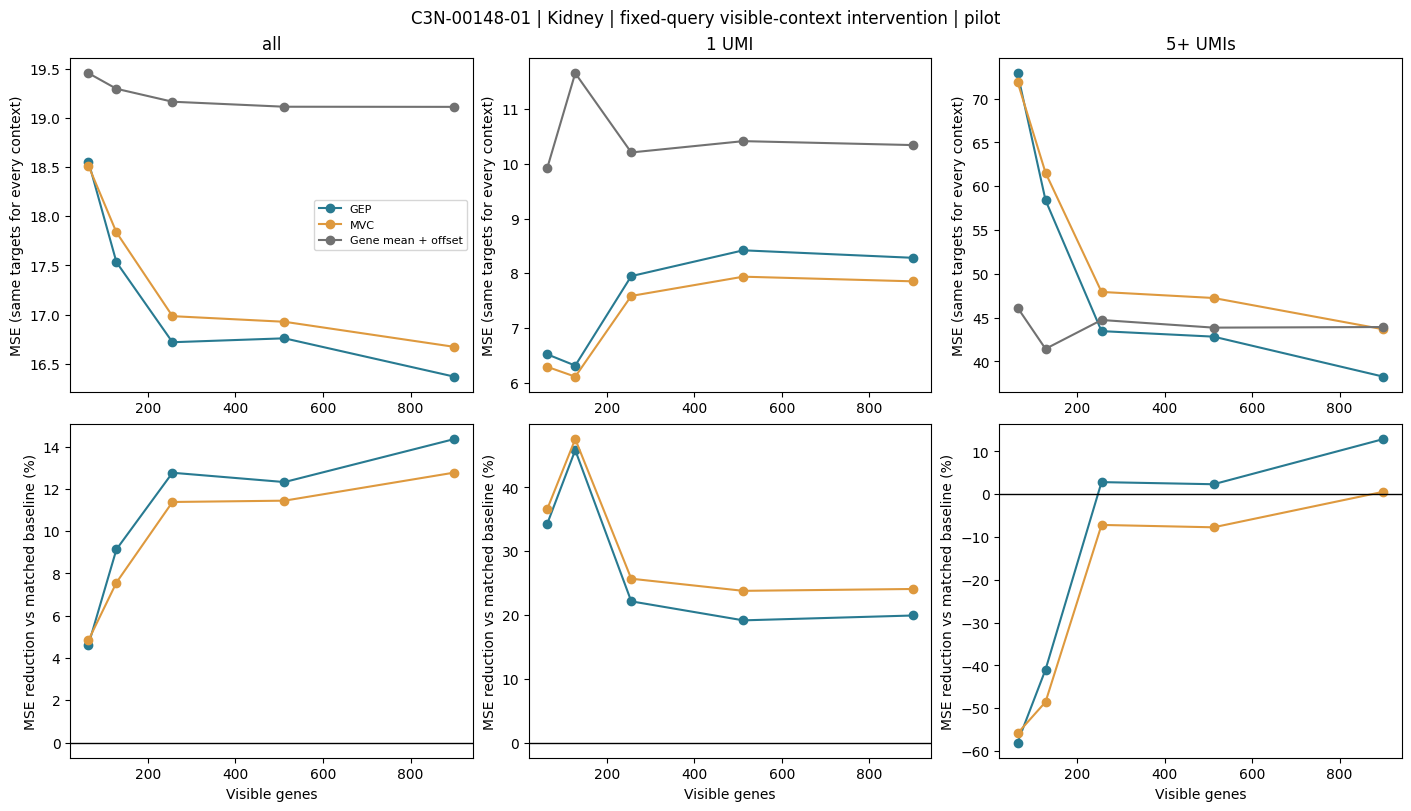

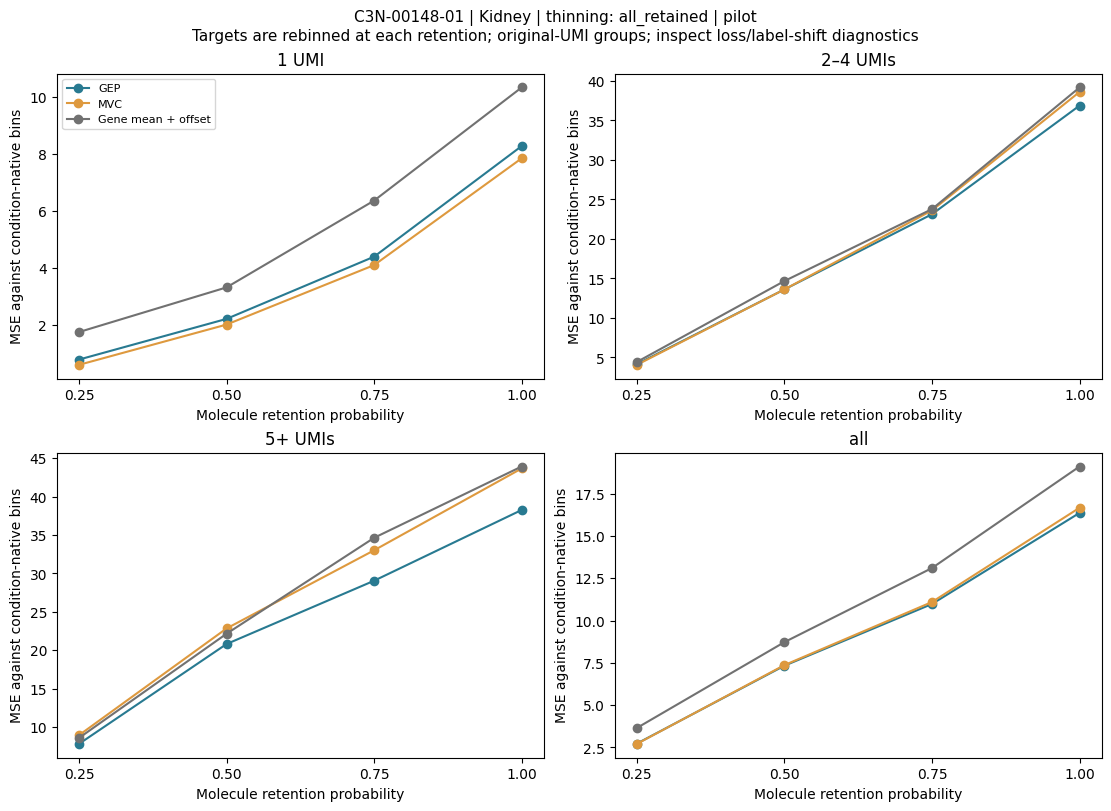

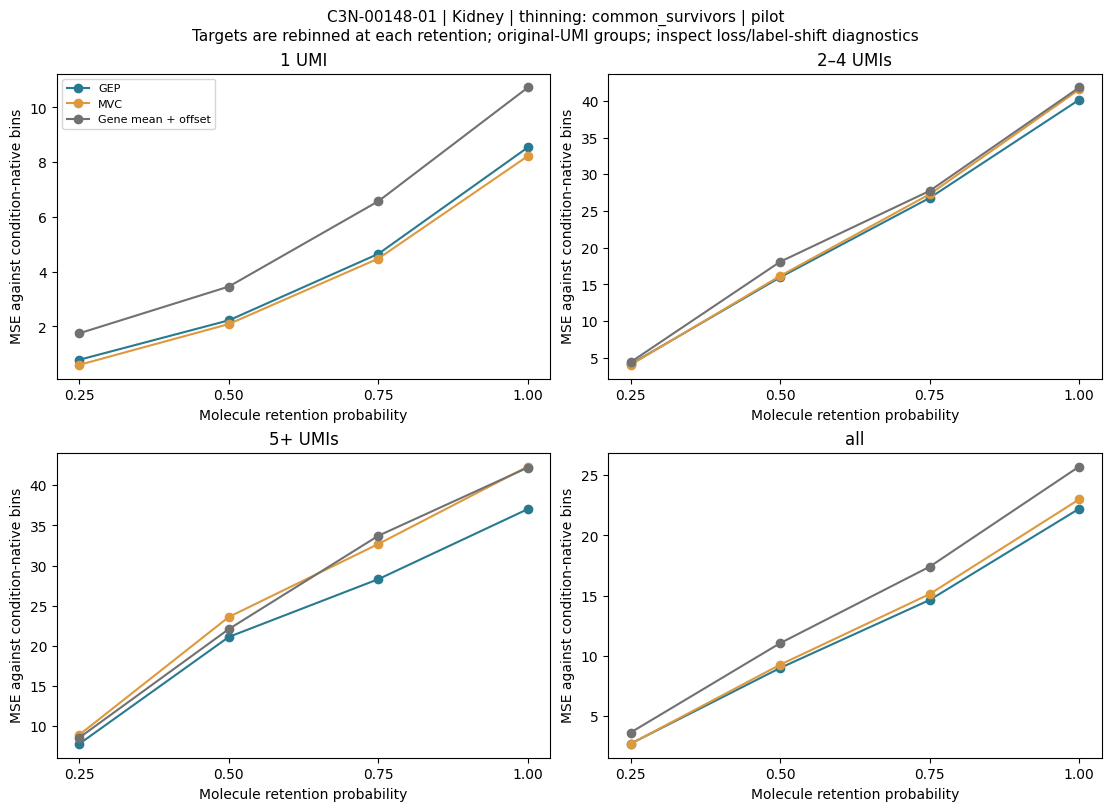

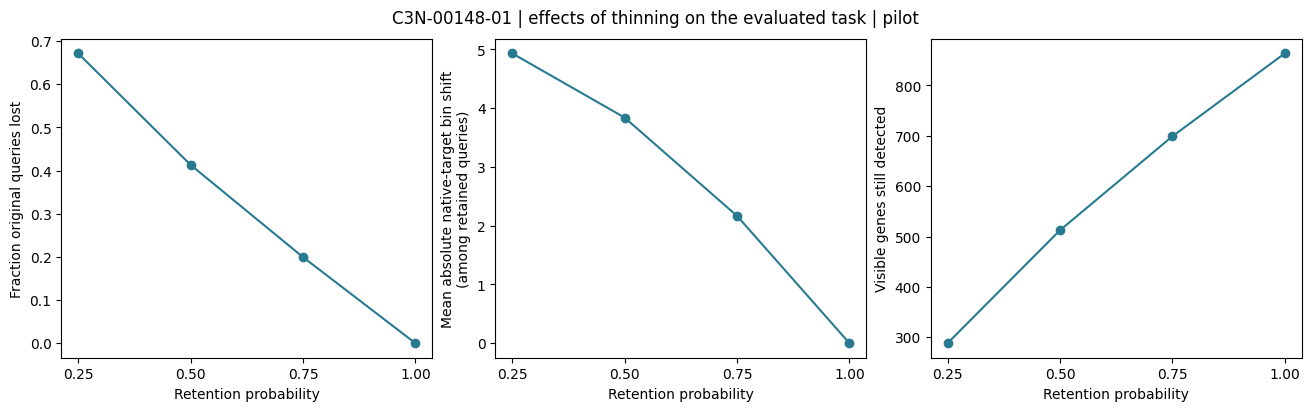

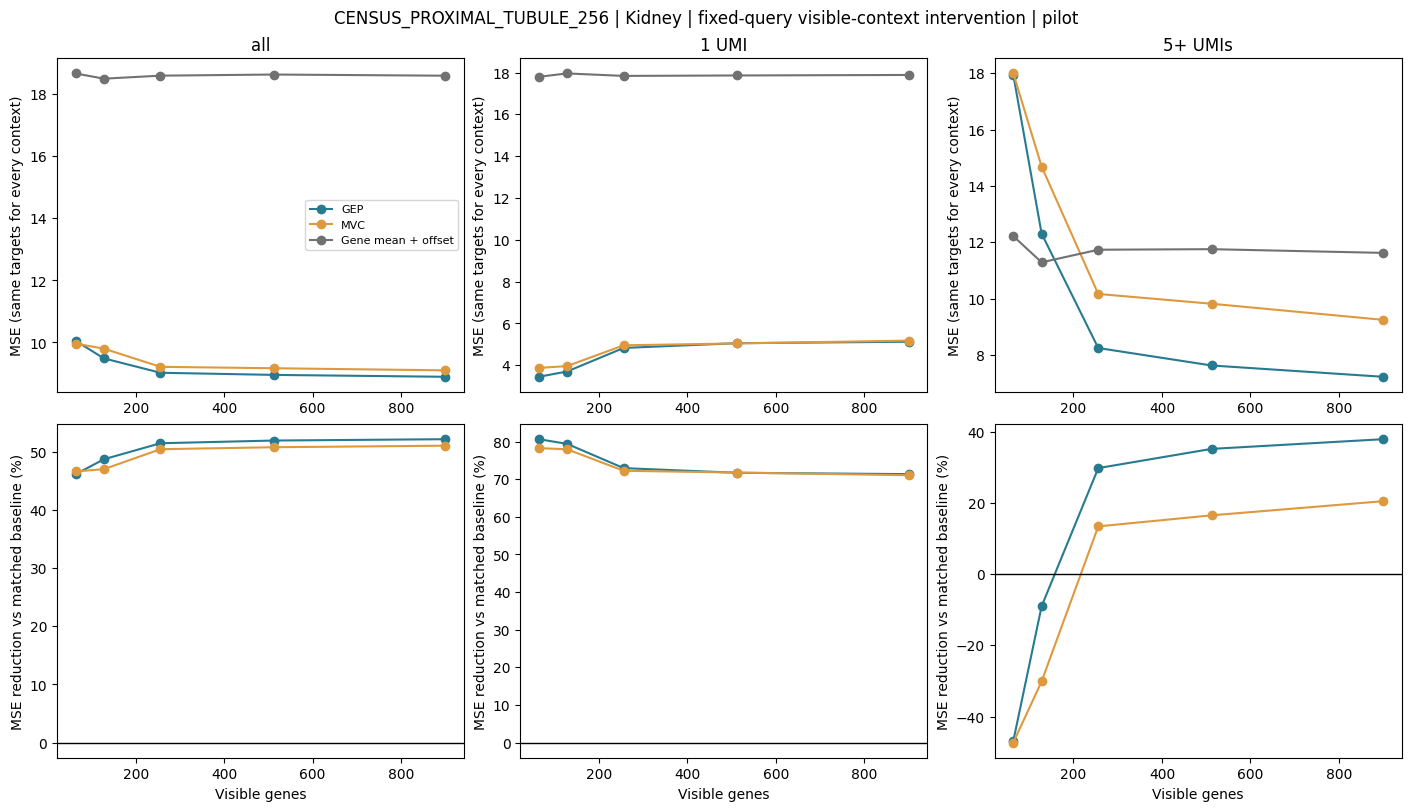

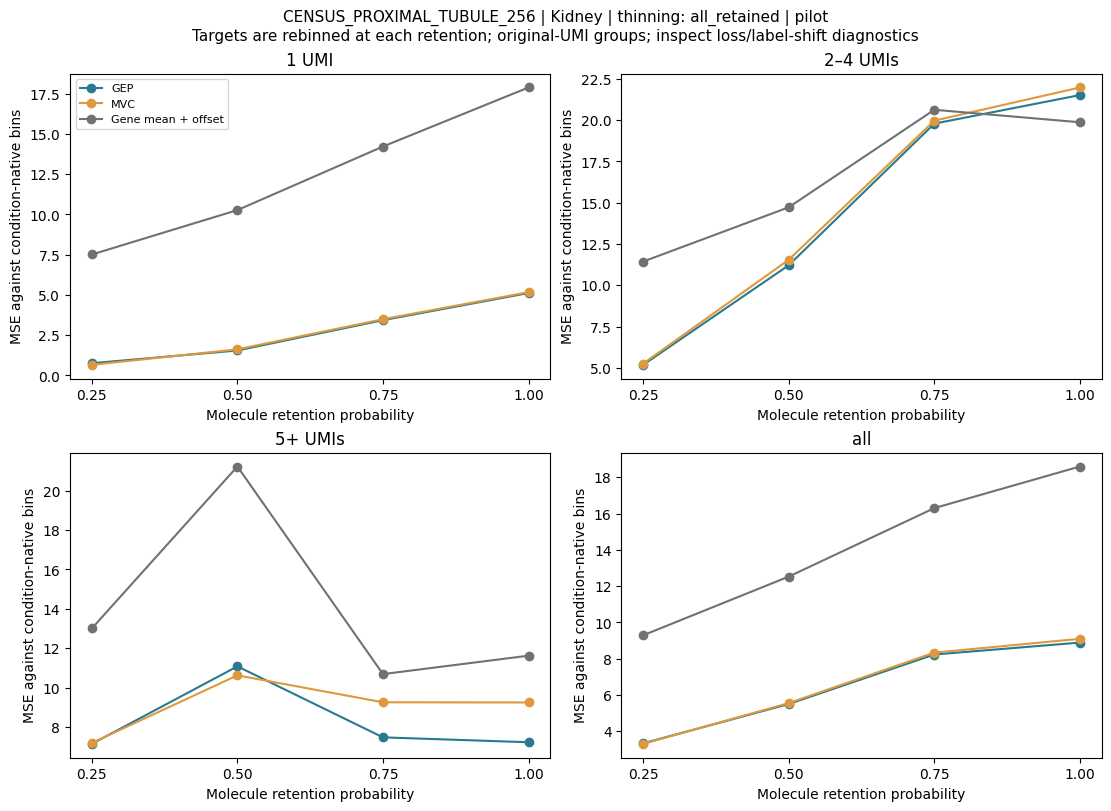

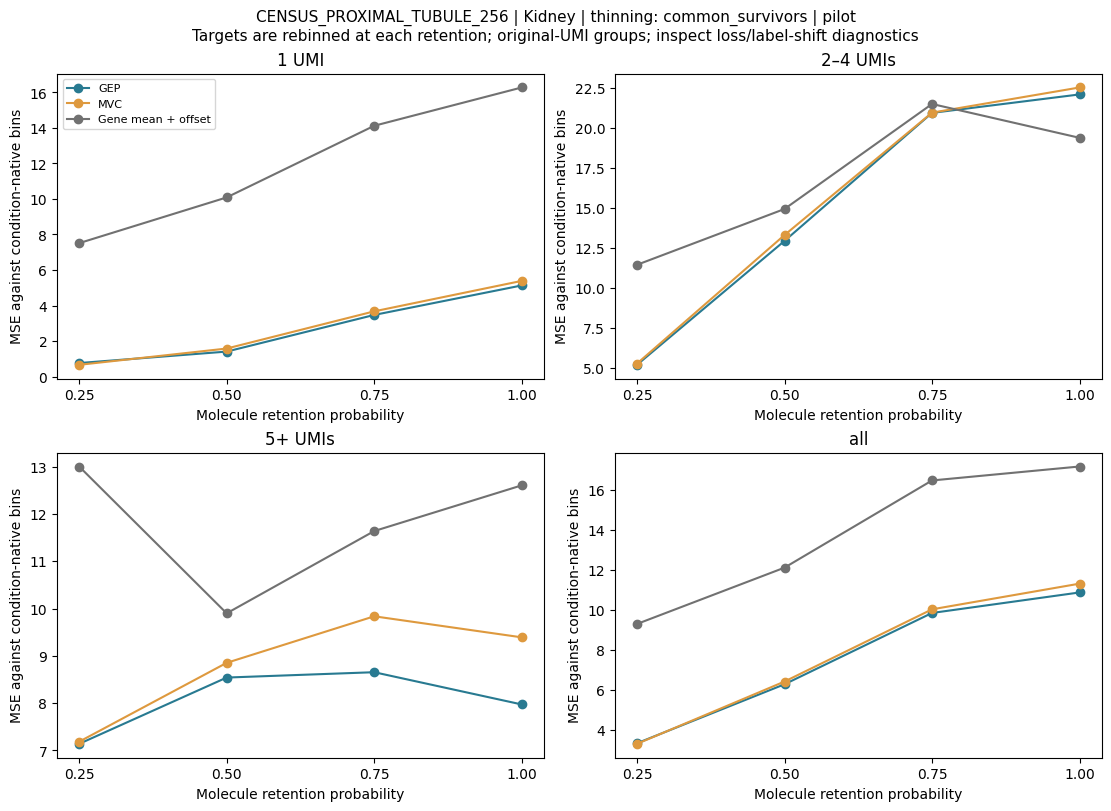

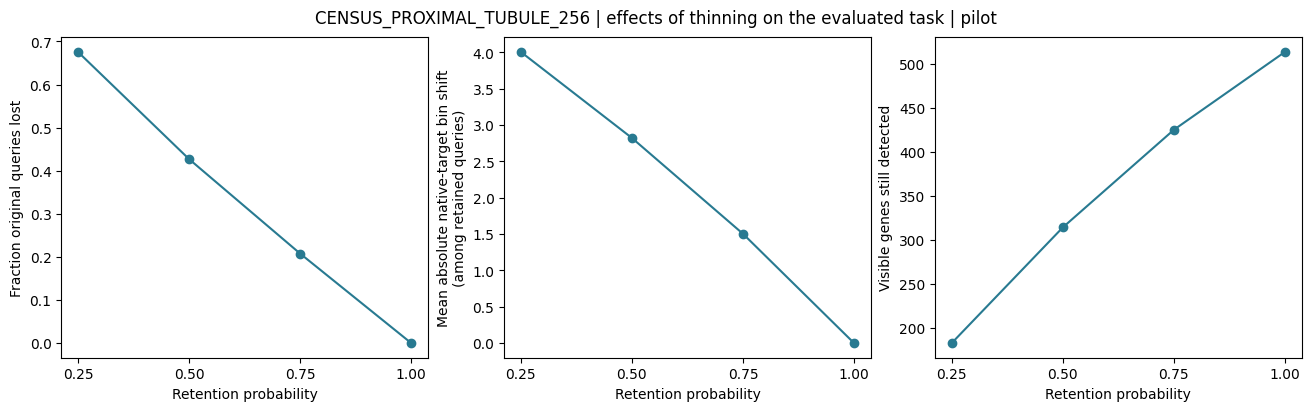

Figures: /home/akash1/scgpt-cna/controlled_expression/results/20261116T201418021732Z_pilot/figures


In [ ]:
# 9 — Plots. Each unit is separate; every point is a cell-balanced condition mean.
import matplotlib.pyplot as plt
FIGURES=RUN_DIR/"figures";FIGURES.mkdir(exist_ok=True)
colors={"GEP":"#287A91","MVC":"#DE993E",BASELINE:"#717171"}
labels={"GEP":"GEP","MVC":"MVC",BASELINE:"Gene mean + offset"}

def save_figure(fig,name):
    fig.savefig(FIGURES/f"{name}.png",dpi=200,bbox_inches="tight")
    fig.savefig(FIGURES/f"{name}.pdf",bbox_inches="tight")
    plt.show();plt.close(fig)

for sid in manifest.sample_id:
    title=manifest.set_index("sample_id").loc[sid,"primary_site"]
    fig,axes=plt.subplots(2,3,figsize=(14,8),constrained_layout=True)
    for col,group in enumerate(["all","1 UMI","5+ UMIs"]):
        part=summary.loc[summary.sample_id.eq(sid)&summary.experiment.eq("context")&summary.count_group.eq(group)]
        for method in [*HEADS,BASELINE]:
            p=part.loc[part.method.eq(method)].sort_values("visible_requested")
            axes[0,col].plot(p.visible_requested,p.mean_MSE,"o-",label=labels[method],color=colors[method])
            if method in HEADS:axes[1,col].plot(p.visible_requested,p.percent_MSE_reduction,"o-",color=colors[method])
        axes[0,col].set(title=group,ylabel="MSE (same targets for every context)")
        axes[1,col].axhline(0,color="black",lw=1)
        axes[1,col].set(xlabel="Visible genes",ylabel="MSE reduction vs matched baseline (%)")
    axes[0,0].legend(fontsize=8)
    fig.suptitle(f"{sid} | {title} | fixed-query visible-context intervention | {MODE}")
    save_figure(fig,f"context_{sid}")
    # Show the actual treatment delivered rather than pretending all cells have 900 available genes.
    coverage=context_inputs.loc[context_inputs.sample_id.eq(sid)].groupby(["cell_id","visible_requested"],as_index=False).agg(n_visible=("n_visible","mean"),saturated=("saturated","mean"))
    coverage=coverage.groupby("visible_requested",as_index=False).agg(actual_mean_visible=("n_visible","mean"),fraction_saturated=("saturated","mean"))
    coverage.to_csv(FIGURES/f"actual_context_{sid}.csv",index=False)
    for view in ["all_retained","common_survivors"]:
        fig,axes=plt.subplots(2,2,figsize=(11,8),constrained_layout=True)
        for ax,group in zip(axes.flat,COUNT_GROUPS):
            part=summary.loc[summary.sample_id.eq(sid)&summary.experiment.eq("thinning")&summary.view.eq(view)&summary.count_group.eq(group)]
            for method in [*HEADS,BASELINE]:
                p=part.loc[part.method.eq(method)].sort_values("retention")
                ax.plot(p.retention,p.mean_MSE,"o-",label=labels[method],color=colors[method])
            ax.set(title=group,xlabel="Molecule retention probability",ylabel="MSE against condition-native bins",xticks=RETENTIONS)
        axes[0,0].legend(fontsize=8)
        fig.suptitle(f"{sid} | {title} | thinning: {view} | {MODE}\nTargets are rebinned at each retention; original-UMI groups; inspect loss/label-shift diagnostics",fontsize=11)
        save_figure(fig,f"thinning_{view}_{sid}")
    part=thinning_inputs.loc[thinning_inputs.sample_id.eq(sid)].groupby(["cell_id","repeat_seed","retention"],as_index=False)[
        ["fraction_queries_lost","mean_abs_target_shift","n_visible","detected_fraction"]].mean()
    part=part.groupby("retention",as_index=False).mean(numeric_only=True).sort_values("retention")
    fig,axes=plt.subplots(1,3,figsize=(13,4),constrained_layout=True)
    for ax,col,label in zip(axes,["fraction_queries_lost","mean_abs_target_shift","n_visible"],["Fraction original queries lost","Mean absolute native-target bin shift\n(among retained queries)","Visible genes still detected"]):
        ax.plot(part.retention,part[col],"o-",color="#287A91")
        ax.set(xlabel="Retention probability",ylabel=label,xticks=RETENTIONS)
    fig.suptitle(f"{sid} | effects of thinning on the evaluated task | {MODE}")
    save_figure(fig,f"thinning_task_changes_{sid}")
print("Figures:",FIGURES)


### 4. Thinning experiment continued

In [1]:
# A — Select a COMPLETED controlled run. This does not create another parent run.
from pathlib import Path
from datetime import datetime, timezone
import hashlib, importlib.util, json, sys, gc
import numpy as np
import pandas as pd
from scipy import sparse
from IPython.display import display

ROOT = Path.home() / "scgpt-cna"
# Set an explicit path when more than one controlled run exists:
SOURCE_RUN = None  # Path("/home/akash1/scgpt-cna/controlled_expression/results/..._pilot")
MODE_TO_LOAD = "pilot"  # Used only if SOURCE_RUN and the existing RUN_DIR are unavailable.
if SOURCE_RUN is None:
    existing = globals().get("RUN_DIR")
    if existing is not None and (Path(existing) / "thinning_inputs.csv").is_file():
        SOURCE_RUN = Path(existing)
    else:
        pointer = ROOT / "controlled_expression/results" / f"latest_{MODE_TO_LOAD}_run.json"
        SOURCE_RUN = Path(json.loads(pointer.read_text())["run_dir"])
SOURCE_RUN = Path(SOURCE_RUN)
source_manifest = json.loads((SOURCE_RUN / "run_manifest.json").read_text())
units = pd.read_csv(SOURCE_RUN / "evaluation_units.tsv", sep="\t")
PS = list(map(float, source_manifest["retentions"]))
SEEDS = list(map(int, source_manifest["mask_seeds"]))
REPEATS = list(map(int, source_manifest["thin_seeds"]))
VISIBLE_CAP = int(source_manifest["thin_context"])
assert PS == sorted(set(PS), reverse=True) and PS[0] == 1 and min(PS) > 0
BASE = "gene_mean_plus_offset"
GROUPS = ["1 UMI", "2–4 UMIs", "5+ UMIs", "all"]
MAIN_METHODS = ["GEP", "MVC", BASE]
# Default: all cells and all seeds already cached in the selected pilot/full run.
# For full evidence, first complete the parent notebook in full mode, then select that run.
SHUFFLE_DRAWS = 3  # Expected shuffled loss is averaged across draws; predictions are NOT ensembled.
assert SHUFFLE_DRAWS >= 1
FOLLOWUP_DIR = SOURCE_RUN / ("thinning_followup_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ"))
FOLLOWUP_DIR.mkdir(exist_ok=False)
FIG_DIR = FOLLOWUP_DIR / "figures"
FIG_DIR.mkdir()

def file_hash(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8*1024**2), b""):
            h.update(block)
    return h.hexdigest()

def follow_seed(*parts):
    return int(hashlib.sha256("|".join(map(str, parts)).encode()).hexdigest()[:16], 16)

def count_group(umi):
    umi = np.asarray(umi)
    assert (umi > 0).all()
    return np.select([umi == 1, umi <= 4], GROUPS[:2], default=GROUPS[2])

def paired_complete(rows):
    # Equal cell/mask/repeat/group tasks at all retentions within each analysis.
    keys = ["sample_id", "view", "cell_id", "mask_seed", "repeat_seed", "count_group"]
    task_counts = rows.groupby(keys, as_index=False).retention.nunique().rename(columns={"retention":"n_conditions"})
    valid = task_counts.loc[task_counts.n_conditions.eq(len(PS)), keys]
    out = rows.merge(valid, on=keys, validate="many_to_one")
    coverage = task_counts.groupby(["sample_id", "view", "count_group"], as_index=False).agg(
        n_candidate_tasks=("n_conditions", "size"), n_complete_tasks=("n_conditions", lambda x: int(x.eq(len(PS)).sum())))
    return out, coverage

def balance(rows):
    # Query mean in each task -> mask mean -> repeat mean -> equal-weight cell mean.
    cond = ["sample_id", "view", "retention", "method", "count_group"]
    metrics = ["MSE", "MAE", "target_variance"]
    repeat = rows.groupby(cond+["cell_id", "repeat_seed"], as_index=False)[metrics].mean()
    cell = repeat.groupby(cond+["cell_id"], as_index=False)[metrics].mean()
    summary = cell.groupby(cond, as_index=False).agg(
        n_cells=("cell_id", "nunique"), mean_MSE=("MSE", "mean"), mean_MAE=("MAE", "mean"),
        mean_target_variance=("target_variance", "mean"),
        n_cells_positive_variance=("target_variance", lambda x: int(x.gt(1e-12).sum())))
    b = summary.loc[summary.method.eq(BASE), [c for c in cond if c!="method"]+["mean_MSE"]].rename(columns={"mean_MSE":"baseline_MSE"})
    summary = summary.merge(b, on=[c for c in cond if c!="method"], validate="many_to_one")
    summary["mean_MSE_gain"] = summary.baseline_MSE-summary.mean_MSE
    summary["percent_MSE_reduction"] = 100*summary.mean_MSE_gain/summary.baseline_MSE.replace(0,np.nan)
    # Ratio of cell-balanced means, NOT an average of unstable individual ratios.
    summary["MSE_over_target_variance"] = summary.mean_MSE/summary.mean_target_variance.where(summary.mean_target_variance.gt(1e-12))
    summary["variance_relative_skill"] = 1-summary.MSE_over_target_variance
    return cell, summary

followup_manifest = dict(source_run=str(SOURCE_RUN), source_manifest_sha256=file_hash(SOURCE_RUN/"run_manifest.json"),
    mode=source_manifest["mode"], retentions=PS, mask_seeds=SEEDS, thin_seeds=REPEATS,
    visible_cap=VISIBLE_CAP, shuffle_draws=SHUFFLE_DRAWS,
    target="Original observed upper-tie bins; all original queries fixed across retentions",
    input="Native upper-tie bins of the thinned full profile; same visible candidates, no refill",
    baseline="Original reference means fixed; visible offset re-estimated from available thinned input",
    limitations=["Observed original targets are noisy, not latent expression truth",
      "Native input rebinning mixes detection, count noise and representation shift",
      "Full-profile bin edges use held-out measurements, as in the parent benchmark",
      "Repeated masks and thinnings are not independent biological samples"])
(FOLLOWUP_DIR/"followup_manifest.json").write_text(json.dumps(followup_manifest,indent=2))
units.to_csv(FOLLOWUP_DIR/"evaluation_units.tsv",sep="\t",index=False)
print("Source:", SOURCE_RUN, "| mode:", source_manifest["mode"])
print("Follow-up:", FOLLOWUP_DIR)

Source: /home/akash1/scgpt-cna/controlled_expression/results/20261116T201418021732Z_pilot | mode: pilot
Follow-up: /home/akash1/scgpt-cna/controlled_expression/results/20261116T201418021732Z_pilot/thinning_followup_20261117T190314133367Z


In [2]:
# B — Finish native-target thinning: variability-normalized and baseline-relative errors.
# No model calls. Query files provide exact moments, avoiding approximating mean variance from mean SD.
native_rows = []
for sid in units.sample_id:
    for repeat in REPEATS:
        for seed in SEEDS:
            for p in PS:
                path = SOURCE_RUN/sid/f"thinning_r{repeat}_p{p:g}_mask{seed}.csv.gz"
                q = pd.read_csv(path)
                assert not q.duplicated(["cell_id","gene_token"]).any()
                if q.empty:
                    continue
                assert q.retention.eq(p).all()
                common = q.common_survivor
                if common.dtype != bool:
                    common = common.astype(str).str.lower().map({"true":True,"false":False})
                    assert common.notna().all()
                for view, selected in [("all_retained",q),("common_survivors",q.loc[common])]:
                    for cell_id, part in selected.groupby("cell_id", sort=False):
                        groups = count_group(part.original_umi.to_numpy())
                        for group in GROUPS:
                            s = part if group=="all" else part.loc[groups==group]
                            if s.empty:
                                continue
                            y = s.target_bin.to_numpy(float)
                            for method in MAIN_METHODS:
                                error = s[method].to_numpy(float)-y
                                native_rows.append(dict(sample_id=sid, cell_id=cell_id, mask_seed=seed,
                                    repeat_seed=repeat, retention=p, view=view, method=method, count_group=group,
                                    n_queries=len(y), MSE=np.square(error).mean(), MAE=abs(error).mean(),
                                    target_variance=y.var(ddof=0)))
native_tasks = pd.DataFrame(native_rows)
assert len(native_tasks), "No saved thinning predictions found. Complete the source thinning run first."
native_tasks, native_task_coverage = paired_complete(native_tasks)
assert len(native_tasks)
# Within common-survivor tasks, gene counts must be fixed across retentions.
common = native_tasks.query("view == 'common_survivors' and method == 'GEP'")
assert common.groupby(["sample_id","cell_id","mask_seed","repeat_seed","count_group"]).n_queries.nunique().le(1).all()
native_cells, native_summary = balance(native_tasks)
for name, frame in [("native_task_scores",native_tasks),("native_cell_scores",native_cells),
                    ("native_normalized_summary",native_summary),("native_task_coverage",native_task_coverage)]:
    frame.to_csv(FOLLOWUP_DIR/f"{name}.csv",index=False)
print("Primary view: same surviving genes across retention, but labels still change.")
display(native_summary.query("view == 'common_survivors' and count_group == 'all'").round(3))
print("Zero target variance makes variance normalization undefined (especially 1-UMI strata).")
display(native_task_coverage)

Primary view: same surviving genes across retention, but labels still change.


,sample_id,view,retention,method,count_group,n_cells,mean_MSE,mean_MAE,mean_target_variance,n_cells_positive_variance,baseline_MSE,mean_MSE_gain,percent_MSE_reduction,MSE_over_target_variance,variance_relative_skill
51,C3N-00148-01,common_survivors,0.25,GEP,all,8,2.730,1.209,3.515,8,3.653,0.923,25.261,0.777,0.223
55,C3N-00148-01,common_survivors,0.25,MVC,all,8,2.712,1.075,3.515,8,3.653,0.941,25.760,0.771,0.229
59,C3N-00148-01,common_survivors,0.25,gene_mean_plus_offset,all,8,3.653,1.382,3.515,8,3.653,0.000,0.000,1.039,-0.039
63,C3N-00148-01,common_survivors,0.50,GEP,all,8,9.007,2.224,11.488,8,11.065,2.058,18.599,0.784,0.216
67,C3N-00148-01,common_survivors,0.50,MVC,all,8,9.280,2.184,11.488,8,11.065,1.785,16.136,0.808,0.192
71,C3N-00148-01,common_survivors,0.50,gene_mean_plus_offset,all,8,11.065,2.487,11.488,8,11.065,0.000,0.000,0.963,0.037
75,C3N-00148-01,common_survivors,0.75,GEP,all,8,14.649,2.962,19.035,8,17.407,2.758,15.843,0.770,0.230
79,C3N-00148-01,common_survivors,0.75,MVC,all,8,15.137,2.971,19.035,8,17.407,2.270,13.039,0.795,0.205
83,C3N-00148-01,common_survivors,0.75,gene_mean_plus_offset,all,8,17.407,3.264,19.035,8,17.407,0.000,0.000,0.914,0.086
87,C3N-00148-01,common_survivors,1.00,GEP,all,8,22.218,3.773,28.319,8,25.717,3.498,13.604,0.785,0.215


Zero target variance makes variance normalization undefined (especially 1-UMI strata).


,sample_id,view,count_group,n_candidate_tasks,n_complete_tasks
0,C3N-00148-01,all_retained,1 UMI,8,8
1,C3N-00148-01,all_retained,2–4 UMIs,8,8
2,C3N-00148-01,all_retained,5+ UMIs,8,8
3,C3N-00148-01,all_retained,all,8,8
4,C3N-00148-01,common_survivors,1 UMI,8,8
5,C3N-00148-01,common_survivors,2–4 UMIs,8,8
6,C3N-00148-01,common_survivors,5+ UMIs,8,8
7,C3N-00148-01,common_survivors,all,8,8
8,CENSUS_PROXIMAL_TUBULE_256,all_retained,1 UMI,8,8
9,CENSUS_PROXIMAL_TUBULE_256,all_retained,2–4 UMIs,8,8


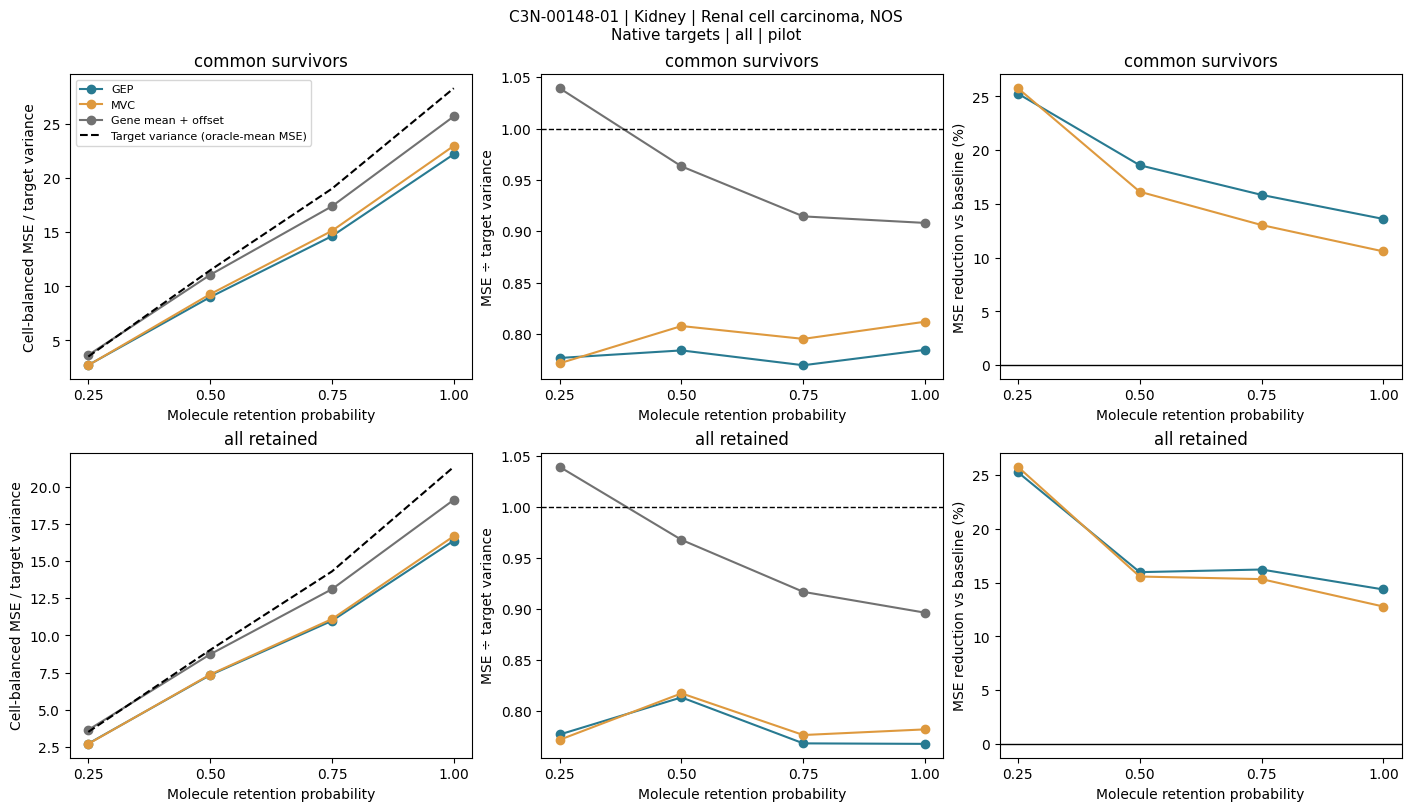

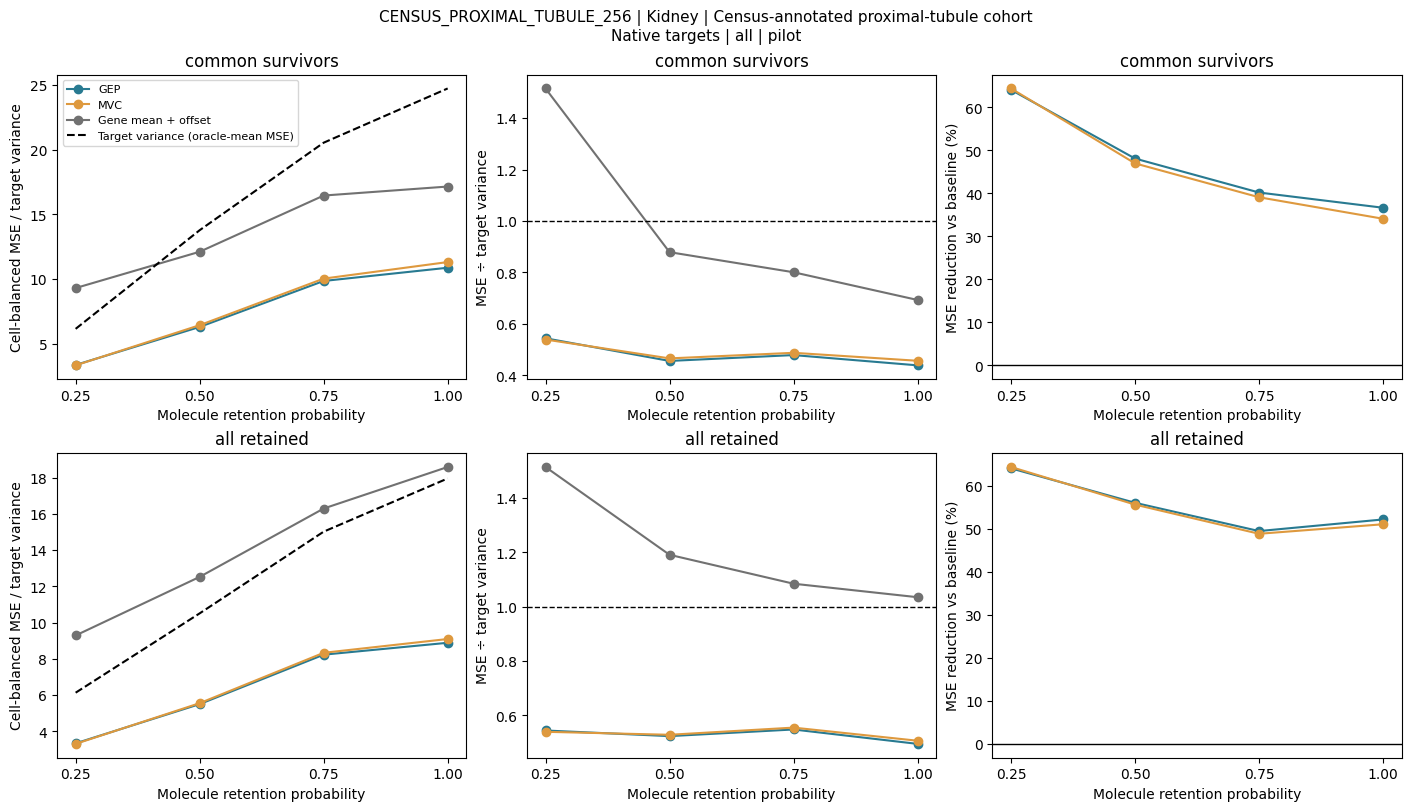

In [3]:
# C — Plot native-target results. Ratios use cell-balanced means.
import matplotlib.pyplot as plt
COLORS = {"GEP":"#287A91", "MVC":"#DE993E", BASE:"#717171",
          "GEP_shuffled":"#76AAB8", "MVC_shuffled":"#EBC68E", "gene_mean":"#9B6798"}
LABELS = {BASE:"Gene mean + offset", "GEP_shuffled":"GEP shuffled", "MVC_shuffled":"MVC shuffled"}

def store_fig(fig, name):
    fig.savefig(FIG_DIR/f"{name}.png",dpi=220,bbox_inches="tight")
    fig.savefig(FIG_DIR/f"{name}.pdf",bbox_inches="tight")
    plt.show(); plt.close(fig)

NATIVE_PLOT_GROUP = "all"  # Also try '5+ UMIs' or '2–4 UMIs'. No variance ratio for '1 UMI'.
for sid in units.sample_id:
    u = units.set_index("sample_id").loc[sid]
    fig, axes = plt.subplots(2,3,figsize=(14,8),constrained_layout=True)
    for row,view in enumerate(["common_survivors","all_retained"]):
        s = native_summary.loc[native_summary.sample_id.eq(sid)&native_summary.view.eq(view)&native_summary.count_group.eq(NATIVE_PLOT_GROUP)]
        for method in MAIN_METHODS:
            t = s.loc[s.method.eq(method)].sort_values("retention")
            for col,metric in enumerate(["mean_MSE","MSE_over_target_variance","percent_MSE_reduction"]):
                if col==2 and method==BASE:
                    continue
                axes[row,col].plot(t.retention,t[metric],"o-",color=COLORS[method],label=LABELS.get(method,method))
        t = s.loc[s.method.eq("GEP")].sort_values("retention")
        axes[row,0].plot(t.retention,t.mean_target_variance,"k--",label="Target variance (oracle-mean MSE)")
        axes[row,1].axhline(1,color="black",ls="--",lw=1)
        axes[row,2].axhline(0,color="black",lw=1)
        for ax,label in zip(axes[row],["Cell-balanced MSE / target variance","MSE ÷ target variance","MSE reduction vs baseline (%)"]):
            ax.set(xlabel="Molecule retention probability",ylabel=label,xticks=sorted(PS),title=view.replace("_"," "))
        if s.mean_target_variance.le(1e-12).all():
            axes[row,1].text(.5,.5,"Undefined: targets have zero variance",ha="center",transform=axes[row,1].transAxes)
    axes[0,0].legend(fontsize=8)
    fig.suptitle(f"{sid} | {u['primary_site']} | {u['diagnoses.0.primary_diagnosis']}\nNative targets | {NATIVE_PLOT_GROUP} | {source_manifest['mode']}",fontsize=11)
    store_fig(fig,f"native_variance_{sid}_{NATIVE_PLOT_GROUP.replace(' ','_').replace('+','plus')}")

In [4]:
# D — Fixed-target inference helpers. Original baseline and every query stay fixed.
# This cell loads software/config only; model weights load lazily in cell E.
import torch
MODEL_FOLLOW = ROOT/"models/whole-human"
HELPER_FOLLOW = ROOT/"notebooks/scgpt_session/scgpt_session.py"
PREPROCESS_FOLLOW = ROOT/"sanity_check/reference_4068d67/scgpt/preprocess.py"
for path,key in [(MODEL_FOLLOW/"best_model.pt","checkpoint_sha256"),
                 (MODEL_FOLLOW/"vocab.json","vocab_sha256"),
                 (HELPER_FOLLOW,"helper_sha256"),(PREPROCESS_FOLLOW,"historical_preprocess_sha256")]:
    assert file_hash(path)==source_manifest[key], f"Changed {key}; use exactly the source run's model and software."
follow_config = json.loads((MODEL_FOLLOW/"args.json").read_text())
assert follow_config==source_manifest["config"]
follow_vocab = json.loads((MODEL_FOLLOW/"vocab.json").read_text())
assert follow_config["n_bins"]==51 and follow_config["max_seq_len"]==1200

def import_follow(name,path):
    spec=importlib.util.spec_from_file_location(name,path)
    module=importlib.util.module_from_spec(spec)
    sys.modules[name]=module
    spec.loader.exec_module(module)
    return module

follow_preprocess=import_follow("followup_pinned_preprocess",PREPROCESS_FOLLOW)
assert follow_preprocess._digitize.__defaults__==("one",)
follow_cls=follow_vocab["<cls>"]
follow_pad_value=follow_config.get("pad_value",-2)
follow_model=None
torch.set_num_threads(4)

def ft_predict(visible_gene_ids,visible_bins,query_gene_ids):
    global follow_model
    if follow_model is None:
        session=import_follow("followup_verified_session",HELPER_FOLLOW)
        follow_model, loaded_vocab, loaded_config=session.load_model(MODEL_FOLLOW)
        assert loaded_config==follow_config and loaded_vocab.get_stoi()==follow_vocab
        follow_model=follow_model.cpu().eval()
    known_ids=torch.tensor(np.r_[follow_cls,visible_gene_ids],dtype=torch.long).unsqueeze(0)
    known_values=torch.tensor(np.r_[follow_pad_value,visible_bins],dtype=torch.float32).unsqueeze(0)
    query_ids=torch.tensor(query_gene_ids,dtype=torch.long).unsqueeze(0)
    assert known_ids.shape[1]+query_ids.shape[1]<=1200
    with torch.inference_mode():
        out=follow_model(known_ids,known_values,query_ids)
    return {h:out[h].cpu().numpy().reshape(-1) for h in ["GEP","MVC"]}

def ft_nested(matrix,sid,repeat):
    # Same algorithm and random stream as the source experiment, including reference rows.
    current=matrix.copy().astype(np.int64)
    np.testing.assert_array_equal(current.data,matrix.data)
    rng=np.random.default_rng(follow_seed("thinning",sid,repeat))
    out={1.:current.copy()}; previous=1.
    for p in PS[1:]:
        new=current.copy();new.data=rng.binomial(current.data,p/previous)
        new.eliminate_zeros();new.sort_indices()
        assert (current-new).min()>=0
        out[p]=new;current=new;previous=p
    return out

def ft_predictions(original,thinned,genes,visible_order,part,means,constant,shuffle_seed):
    # No query is removed when its thinned count becomes zero.
    query_ids=part.gene_token.to_numpy(dtype=int)
    candidate_ids=genes[original.indices[visible_order[:VISIBLE_CAP]]]
    native=np.asarray(follow_preprocess.binning(thinned.data.copy(),n_bins=51),dtype=float) if thinned.nnz else np.array([])
    positions={int(genes[col]):j for j,col in enumerate(thinned.indices)}
    vi=np.array([positions[int(g)] for g in candidate_ids if int(g) in positions],dtype=int)
    visible_ids=genes[thinned.indices[vi]]
    values=native[vi]
    assert not set(visible_ids).intersection(query_ids)
    assert 1+len(vi)+len(query_ids)<=1200
    column_by_gene={int(t):j for j,t in enumerate(genes)}
    qcols=np.array([column_by_gene[int(t)] for t in query_ids],dtype=int)
    query_retained=np.array([int(thinned.data[positions[int(t)]]) if int(t) in positions else 0 for t in query_ids])
    # Empty visible context is valid: CLS-only model; offset=0; visible mean falls back to reference constant.
    offset=float(np.mean(values-means[thinned.indices[vi]])) if len(vi) else 0.
    pred=ft_predict(visible_ids,values,query_ids)
    pred.update({"gene_mean":means[qcols],BASE:means[qcols]+offset,
                 "visible_mean":np.full(len(query_ids),values.mean() if len(vi) else constant),
                 "reference_constant":np.full(len(query_ids),constant)})
    # Keep gene identities/query/target fixed; shuffle visible values ONLY. Never shuffle CLS.
    rng=np.random.default_rng(shuffle_seed)
    for draw in range(SHUFFLE_DRAWS):
        shuffled=ft_predict(visible_ids,rng.permutation(values),query_ids)
        for head in ["GEP","MVC"]:
            pred[f"{head}_shuffled_d{draw}"]=shuffled[head]
    assert all(np.asarray(v).shape==(len(part),) and np.isfinite(v).all() for v in pred.values())
    return pred,query_retained,dict(n_visible=len(vi),n_original_visible=len(candidate_ids),
        fraction_queries_undetected=float(np.mean(query_retained==0)),visible_offset=offset,
        mean_visible_bin=float(values.mean()) if len(vi) else np.nan)

print("Fixed-target helpers ready. Lower-p targets and reference means will NOT be refitted.")

/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/scgpt/model/model.py:21: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")
/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/scgpt/model/multiomic_model.py:19: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")


Fixed-target helpers ready. Lower-p targets and reference means will NOT be refitted.


In [5]:
# E — Run fixed-target inference and save every original query at every retention.
# Runs only from the cached counts, never rereads all source samples.
fixed_inputs=[]
for sid in units.sample_id:
    src=SOURCE_RUN/sid; dst=FOLLOWUP_DIR/sid;dst.mkdir(exist_ok=True)
    for name in ["original_model_counts.npz","gene_tokens.npy","frozen_cell_roles.tsv","original_baseline.npz","visible_orders.npz"]:
        assert (src/name).is_file(), f"Missing prepared cache: {src/name}"
    matrix=sparse.load_npz(src/"original_model_counts.npz").tocsr()
    roles=pd.read_csv(src/"frozen_cell_roles.tsv",sep="\t")
    genes=np.load(src/"gene_tokens.npy")
    with np.load(src/"original_baseline.npz") as b:
        means=b["means"].copy(); support=b["support"].copy(); constant=float(b["constant"])
    assert genes.shape==(matrix.shape[1],) and len(set(genes))==len(genes)
    assert len(roles)==matrix.shape[0]
    assert roles.cache_index.to_numpy().tolist()==list(range(len(roles)))
    eval_roles=roles.loc[roles.role.eq("evaluation")]
    cache_hashes={name:file_hash(src/name) for name in ["original_model_counts.npz","gene_tokens.npy","frozen_cell_roles.tsv","original_baseline.npz","visible_orders.npz"]}
    (dst/"source_cache_hashes.json").write_text(json.dumps(cache_hashes,indent=2))
    with np.load(src/"visible_orders.npz") as orders:
        for repeat in REPEATS:
            profiles=ft_nested(matrix,sid,repeat)
            for seed in SEEDS:
                anchors=pd.read_csv(src/f"frozen_queries_mask{seed}.csv.gz")
                control=pd.read_csv(src/f"context_v{VISIBLE_CAP}_mask{seed}.csv.gz").set_index(["cell_id","gene_token"])
                outputs={p:[] for p in PS}
                for cell in eval_roles.itertuples(index=False):
                    original=matrix.getrow(cell.cache_index)
                    part=anchors.loc[anchors.cell_id.eq(cell.cell_id)].copy()
                    assert len(part)>0 and not part.gene_token.duplicated().any()
                    original_position={int(genes[c]):j for j,c in enumerate(original.indices)}
                    qi=np.array([original_position[int(t)] for t in part.gene_token],dtype=int)
                    original_bins=np.asarray(follow_preprocess.binning(original.data.copy(),n_bins=51))
                    np.testing.assert_array_equal(original_bins[qi],part.target_bin)
                    np.testing.assert_array_equal(original.data[qi],part.original_umi)
                    order=orders[f"c{cell.cache_index}_s{seed}"]
                    assert not np.intersect1d(order,qi).size
                    for p in PS:
                        row=profiles[p].getrow(cell.cache_index)
                        # Same draw index across p; permutations adapt to the surviving visible set.
                        pred,retained,info=ft_predictions(original,row,genes,order,part,means,constant,
                            follow_seed("fixed_target_shuffle",sid,cell.cell_id,seed,repeat))
                        identity=dict(sample_id=sid,case_id=str(cell.case_id),cell_id=str(cell.cell_id),
                            cell_index=int(cell.cache_index),mask_seed=seed,repeat_seed=repeat,retention=p)
                        frame=pd.DataFrame({**identity,"gene_token":part.gene_token.to_numpy(),
                            "original_umi":part.original_umi.to_numpy(),"retained_umi":retained,
                            "target_bin":part.target_bin.to_numpy(),**pred})
                        assert len(frame)==len(part)  # Even original queries with retained_umi==0 are scored.
                        if p==1.:
                            check=frame.set_index(["cell_id","gene_token"])
                            expected=control.loc[check.index]
                            for col in ["target_bin","GEP","MVC",BASE,"gene_mean","visible_mean","reference_constant"]:
                                np.testing.assert_allclose(check[col],expected[col],atol=2e-5,rtol=2e-6,err_msg=f"p=1 mismatch: {sid} {col}")
                        outputs[p].append(frame)
                        fixed_inputs.append({**identity,**info,"n_queries":len(part),"n_tokens":1+info["n_visible"]+len(part),
                            "original_target_variance":part.target_bin.var(ddof=0)})
                    print(sid,"repeat",repeat,"mask",seed,"cell",cell.cache_index,"saved in memory",flush=True)
                for p,frames in outputs.items():
                    out=pd.concat(frames,ignore_index=True)
                    assert not out.duplicated(["cell_id","gene_token"]).any()
                    out.to_csv(dst/f"fixed_r{repeat}_p{p:g}_mask{seed}.csv.gz",index=False)
                print(sid,"repeat",repeat,"mask",seed,"written; original query coverage preserved",flush=True)
            del profiles
    del matrix;gc.collect()
pd.DataFrame(fixed_inputs).to_csv(FOLLOWUP_DIR/"fixed_inputs.csv",index=False)
(FOLLOWUP_DIR/"inference_complete.json").write_text(json.dumps(dict(complete=True),indent=2))
print("Inference complete:",FOLLOWUP_DIR)

Strict load: 163 checkpoint tensors; no omitted tensors.
C3N-00148-01 repeat 101 mask 42 cell 128 saved in memory
C3N-00148-01 repeat 101 mask 42 cell 129 saved in memory
C3N-00148-01 repeat 101 mask 42 cell 130 saved in memory
C3N-00148-01 repeat 101 mask 42 cell 131 saved in memory
C3N-00148-01 repeat 101 mask 42 cell 132 saved in memory
C3N-00148-01 repeat 101 mask 42 cell 133 saved in memory
C3N-00148-01 repeat 101 mask 42 cell 134 saved in memory
C3N-00148-01 repeat 101 mask 42 cell 135 saved in memory
C3N-00148-01 repeat 101 mask 42 written; original query coverage preserved
CENSUS_PROXIMAL_TUBULE_256 repeat 101 mask 42 cell 128 saved in memory
CENSUS_PROXIMAL_TUBULE_256 repeat 101 mask 42 cell 129 saved in memory
CENSUS_PROXIMAL_TUBULE_256 repeat 101 mask 42 cell 130 saved in memory
CENSUS_PROXIMAL_TUBULE_256 repeat 101 mask 42 cell 131 saved in memory
CENSUS_PROXIMAL_TUBULE_256 repeat 101 mask 42 cell 132 saved in memory
CENSUS_PROXIMAL_TUBULE_256 repeat 101 mask 42 cell 133 sa

In [6]:
# F — Score fixed original targets. Repeats/masks are averaged within each biological cell.
assert (FOLLOWUP_DIR/"inference_complete.json").is_file(), "Finish cell E before scoring."
fixed_rows=[]
for sid in units.sample_id:
    for repeat in REPEATS:
        for seed in SEEDS:
            anchor_keys=None
            for p in PS:
                q=pd.read_csv(FOLLOWUP_DIR/sid/f"fixed_r{repeat}_p{p:g}_mask{seed}.csv.gz")
                keys=q.set_index(["cell_id","gene_token"])[["original_umi","target_bin"]].sort_index()
                if anchor_keys is None: anchor_keys=keys
                else: pd.testing.assert_frame_equal(keys,anchor_keys)
                for cell_id,part in q.groupby("cell_id",sort=False):
                    groups=count_group(part.original_umi.to_numpy())
                    for group in GROUPS:
                        s=part if group=="all" else part.loc[groups==group]
                        if s.empty:continue
                        y=s.target_bin.to_numpy(float)
                        predictions={m:s[[m]].to_numpy(float) for m in [*MAIN_METHODS,"gene_mean","visible_mean","reference_constant"]}
                        for head in ["GEP","MVC"]:
                            predictions[f"{head}_shuffled"]=s[[f"{head}_shuffled_d{draw}" for draw in range(SHUFFLE_DRAWS)]].to_numpy(float)
                        for method,values in predictions.items():
                            error=values-y[:,None]
                            fixed_rows.append(dict(sample_id=sid,cell_id=cell_id,mask_seed=seed,repeat_seed=repeat,
                                retention=p,view="fixed_original_targets",count_group=group,method=method,n_queries=len(y),
                                MSE=np.square(error).mean(),MAE=np.abs(error).mean(),target_variance=y.var(ddof=0)))
fixed_tasks=pd.DataFrame(fixed_rows)
fixed_tasks,fixed_task_coverage=paired_complete(fixed_tasks)
assert fixed_task_coverage.n_candidate_tasks.eq(fixed_task_coverage.n_complete_tasks).all()
fixed_cells,fixed_summary=balance(fixed_tasks)
# Fixed labels, fixed query population, and frozen gene means imply these invariants.
for _,part in fixed_cells.groupby(["sample_id","cell_id","method","count_group"]):
    assert np.ptp(part.target_variance.to_numpy()) < 1e-10
    if part.method.iloc[0] in {"gene_mean","reference_constant"}:
        assert np.ptp(part.MSE.to_numpy()) < 1e-10
# Compare correct associations with shuffled associations, paired within cell.
k=["sample_id","view","retention","cell_id","count_group"]
context_rows=[]
for head in ["GEP","MVC"]:
    a=fixed_cells.loc[fixed_cells.method.eq(head),k+["MSE"]].rename(columns={"MSE":"correct_MSE"})
    b=fixed_cells.loc[fixed_cells.method.eq(f"{head}_shuffled"),k+["MSE"]].rename(columns={"MSE":"shuffled_MSE"})
    a=a.merge(b,on=k,validate="one_to_one")
    a["head"]=head;a["context_gain"]=a.shuffled_MSE-a.correct_MSE
    context_rows.append(a)
fixed_context_cells=pd.concat(context_rows,ignore_index=True)
fixed_context=fixed_context_cells.groupby(["sample_id","retention","count_group","head"],as_index=False).agg(
    n_cells=("cell_id","nunique"),mean_context_gain=("context_gain","mean"),median_context_gain=("context_gain","median"),
    percent_cells_correct_wins=("context_gain",lambda x:100*x.gt(0).mean()),
    correct_MSE=("correct_MSE","mean"),shuffled_MSE=("shuffled_MSE","mean"))
# Errors above the ORIGINAL gene-mean baseline need not be positive.
# Same original query/target population: p=1 vs p<1 MSE differences are now directly comparable.
keys=["sample_id","view","method","count_group","cell_id"]
at1=fixed_cells.loc[fixed_cells.retention.eq(1),keys+["MSE"]].rename(columns={"MSE":"MSE_at_1"})
fixed_damage=fixed_cells.merge(at1,on=keys,validate="many_to_one")
fixed_damage["MSE_increase_from_full"]=fixed_damage.MSE-fixed_damage.MSE_at_1
fixed_damage_summary=fixed_damage.groupby(["sample_id","method","count_group","retention"],as_index=False).agg(
    n_cells=("cell_id","nunique"),mean_MSE_increase=("MSE_increase_from_full","mean"),
    median_cell_MSE_increase=("MSE_increase_from_full","median"))
for name,frame in [("fixed_task_scores",fixed_tasks),("fixed_cell_scores",fixed_cells),("fixed_summary",fixed_summary),
                   ("fixed_task_coverage",fixed_task_coverage),("fixed_context_cell_gains",fixed_context_cells),
                   ("fixed_context_summary",fixed_context),("fixed_damage_summary",fixed_damage_summary)]:
    frame.to_csv(FOLLOWUP_DIR/f"{name}.csv",index=False)
fixed_input_cells=pd.read_csv(FOLLOWUP_DIR/"fixed_inputs.csv").groupby(["sample_id","cell_id","retention"],as_index=False).agg(
    mean_visible=("n_visible","mean"),fraction_queries_undetected=("fraction_queries_undetected","mean"))
fixed_input_summary=fixed_input_cells.groupby(["sample_id","retention"],as_index=False).agg(
    n_cells=("cell_id","nunique"),mean_visible=("mean_visible","mean"),
    fraction_original_queries_now_undetected=("fraction_queries_undetected","mean"))
fixed_input_summary.to_csv(FOLLOWUP_DIR/"fixed_input_summary.csv",index=False)
print("All original queries scored at every retention; target identity/variance verified unchanged.")
display(fixed_input_summary.round(3))
display(fixed_summary.query("count_group == 'all' and method in @MAIN_METHODS").round(3))
print("Positive context gain means correct visible gene/value associations helped recover original targets:")
display(fixed_context.query("count_group == 'all'").round(3))

All original queries scored at every retention; target identity/variance verified unchanged.


,sample_id,retention,n_cells,mean_visible,fraction_original_queries_now_undetected
0,C3N-00148-01,0.25,8,288.125,0.672
1,C3N-00148-01,0.50,8,512.375,0.413
2,C3N-00148-01,0.75,8,699.000,0.200
3,C3N-00148-01,1.00,8,863.750,0.000
4,CENSUS_PROXIMAL_TUBULE_256,0.25,8,182.750,0.676
5,CENSUS_PROXIMAL_TUBULE_256,0.50,8,314.375,0.427
6,CENSUS_PROXIMAL_TUBULE_256,0.75,8,425.500,0.208
7,CENSUS_PROXIMAL_TUBULE_256,1.00,8,514.125,0.000


,sample_id,view,retention,method,count_group,n_cells,mean_MSE,mean_MAE,mean_target_variance,n_cells_positive_variance,baseline_MSE,mean_MSE_gain,percent_MSE_reduction,MSE_over_target_variance,variance_relative_skill
3,C3N-00148-01,fixed_original_targets,0.25,GEP,all,8,45.512,6.040,21.327,8,39.919,-5.592,-14.009,2.134,-1.134
11,C3N-00148-01,fixed_original_targets,0.25,MVC,all,8,43.527,5.921,21.327,8,39.919,-3.607,-9.037,2.041,-1.041
23,C3N-00148-01,fixed_original_targets,0.25,gene_mean_plus_offset,all,8,39.919,5.524,21.327,8,39.919,0.000,0.000,1.872,-0.872
35,C3N-00148-01,fixed_original_targets,0.50,GEP,all,8,26.831,4.926,21.327,8,26.728,-0.103,-0.386,1.258,-0.258
43,C3N-00148-01,fixed_original_targets,0.50,MVC,all,8,26.058,4.859,21.327,8,26.728,0.670,2.505,1.222,-0.222
55,C3N-00148-01,fixed_original_targets,0.50,gene_mean_plus_offset,all,8,26.728,4.604,21.327,8,26.728,0.000,0.000,1.253,-0.253
67,C3N-00148-01,fixed_original_targets,0.75,GEP,all,8,18.215,3.934,21.327,8,20.386,2.171,10.651,0.854,0.146
75,C3N-00148-01,fixed_original_targets,0.75,MVC,all,8,18.122,3.891,21.327,8,20.386,2.264,11.106,0.850,0.150
87,C3N-00148-01,fixed_original_targets,0.75,gene_mean_plus_offset,all,8,20.386,3.901,21.327,8,20.386,0.000,0.000,0.956,0.044
99,C3N-00148-01,fixed_original_targets,1.00,GEP,all,8,16.368,3.200,21.327,8,19.113,2.744,14.359,0.767,0.233


Positive context gain means correct visible gene/value associations helped recover original targets:


,sample_id,retention,count_group,head,n_cells,mean_context_gain,median_context_gain,percent_cells_correct_wins,correct_MSE,shuffled_MSE
6,C3N-00148-01,0.25,all,GEP,8,0.774,0.321,100.0,45.512,46.285
7,C3N-00148-01,0.25,all,MVC,8,0.639,0.371,75.0,43.527,44.166
14,C3N-00148-01,0.50,all,GEP,8,1.726,1.230,100.0,26.831,28.557
15,C3N-00148-01,0.50,all,MVC,8,1.303,0.835,100.0,26.058,27.362
22,C3N-00148-01,0.75,all,GEP,8,1.852,1.350,100.0,18.215,20.067
23,C3N-00148-01,0.75,all,MVC,8,1.637,1.161,100.0,18.122,19.760
30,C3N-00148-01,1.00,all,GEP,8,1.259,0.837,87.5,16.368,17.628
31,C3N-00148-01,1.00,all,MVC,8,1.227,0.830,87.5,16.672,17.899
38,CENSUS_PROXIMAL_TUBULE_256,0.25,all,GEP,8,1.764,2.058,75.0,29.240,31.004
39,CENSUS_PROXIMAL_TUBULE_256,0.25,all,MVC,8,2.022,2.232,75.0,27.256,29.279


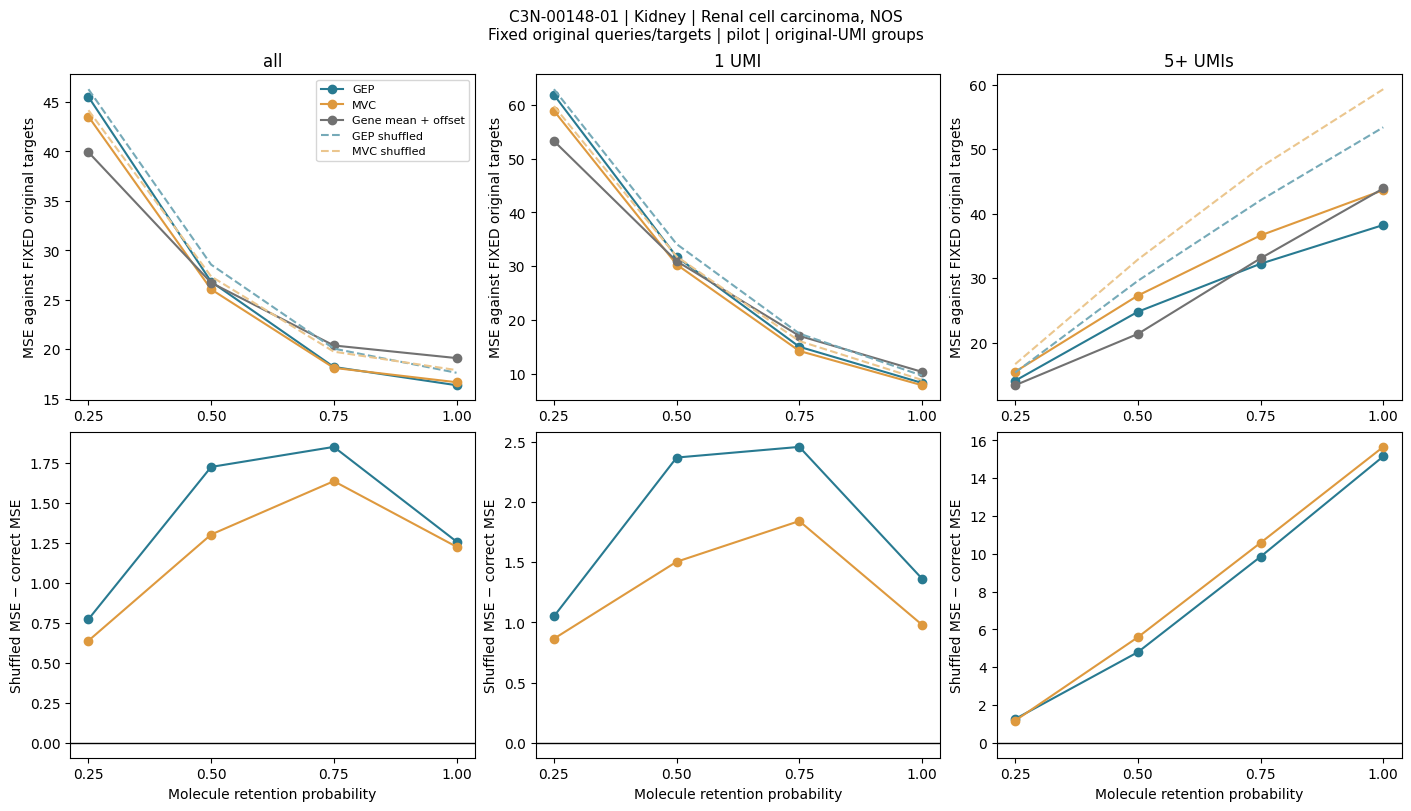

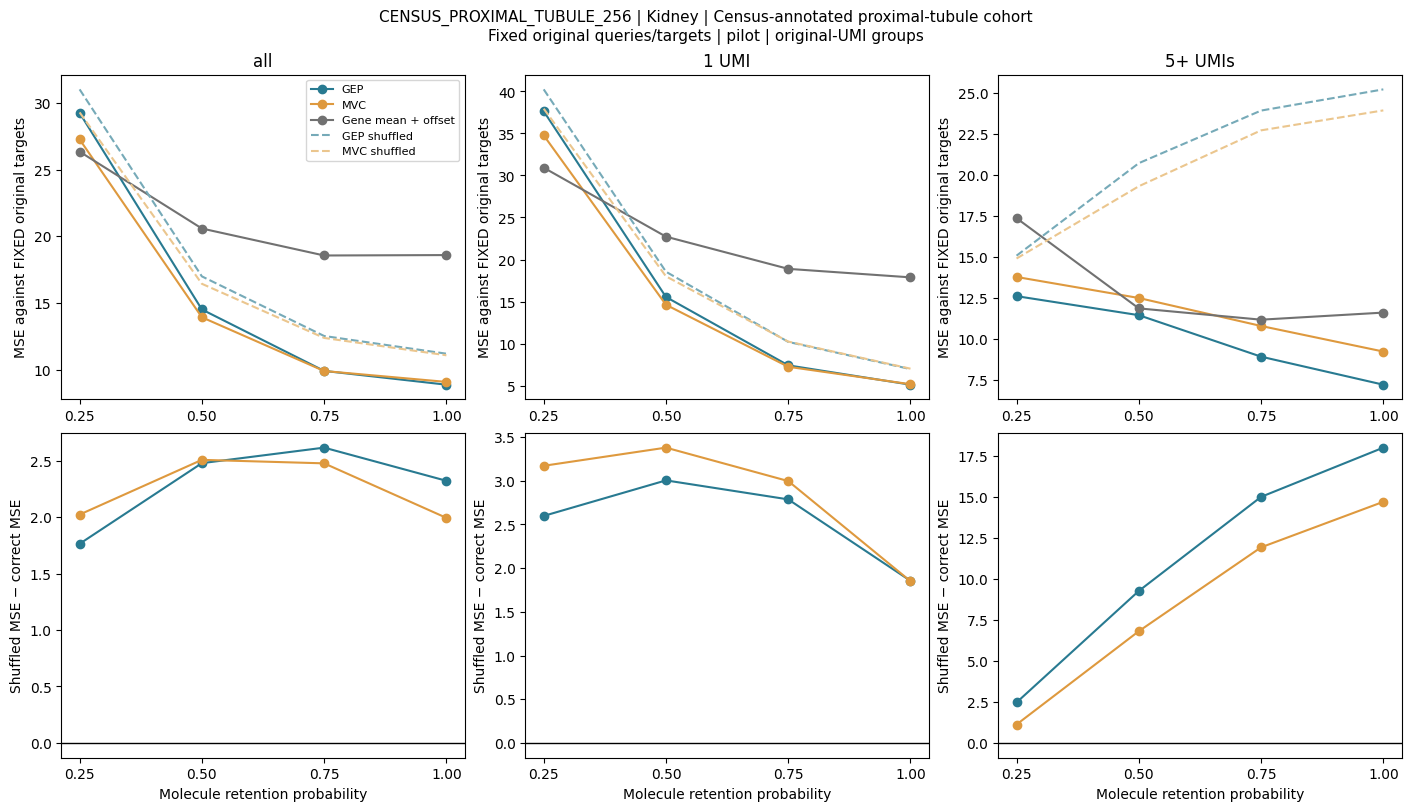

Results and PNG/PDF figures: /home/akash1/scgpt-cna/controlled_expression/results/20261116T201418021732Z_pilot/thinning_followup_20261117T190314133367Z


In [7]:
# G — Fixed-target figures. Run C's imports/plot helpers first if reopening the kernel.
for sid in units.sample_id:
    u=units.set_index("sample_id").loc[sid]
    fig,axes=plt.subplots(2,3,figsize=(14,8),constrained_layout=True)
    for col,group in enumerate(["all","1 UMI","5+ UMIs"]):
        part=fixed_summary.loc[fixed_summary.sample_id.eq(sid)&fixed_summary.count_group.eq(group)]
        for method in MAIN_METHODS:
            t=part.loc[part.method.eq(method)].sort_values("retention")
            axes[0,col].plot(t.retention,t.mean_MSE,"o-",label=LABELS.get(method,method),color=COLORS[method])
        for head in ["GEP","MVC"]:
            t=part.loc[part.method.eq(f"{head}_shuffled")].sort_values("retention")
            axes[0,col].plot(t.retention,t.mean_MSE,"--",label=f"{head} shuffled",color=COLORS[f"{head}_shuffled"])
            t=fixed_context.loc[fixed_context.sample_id.eq(sid)&fixed_context.count_group.eq(group)&fixed_context['head'].eq(head)].sort_values("retention")
            axes[1,col].plot(t.retention,t.mean_context_gain,"o-",color=COLORS[head],label=head)
        axes[0,col].set(title=group,ylabel="MSE against FIXED original targets")
        axes[1,col].axhline(0,color="black",lw=1)
        axes[1,col].set(ylabel="Shuffled MSE − correct MSE",xlabel="Molecule retention probability")
        for ax in axes[:,col]:ax.set_xticks(sorted(PS))
    axes[0,0].legend(fontsize=8)
    fig.suptitle(f"{sid} | {u['primary_site']} | {u['diagnoses.0.primary_diagnosis']}\nFixed original queries/targets | {source_manifest['mode']} | original-UMI groups",fontsize=11)
    store_fig(fig,f"fixed_original_targets_{sid}")
print("Results and PNG/PDF figures:",FOLLOWUP_DIR)

C3N-00148-01 repeat 101 retention 1.0 mask 42 translated; model not rerun
C3N-00148-01 repeat 101 retention 0.75 mask 42 translated; model not rerun
C3N-00148-01 repeat 101 retention 0.5 mask 42 translated; model not rerun
C3N-00148-01 repeat 101 retention 0.25 mask 42 translated; model not rerun
CENSUS_PROXIMAL_TUBULE_256 repeat 101 retention 1.0 mask 42 translated; model not rerun
CENSUS_PROXIMAL_TUBULE_256 repeat 101 retention 0.75 mask 42 translated; model not rerun
CENSUS_PROXIMAL_TUBULE_256 repeat 101 retention 0.5 mask 42 translated; model not rerun
CENSUS_PROXIMAL_TUBULE_256 repeat 101 retention 0.25 mask 42 translated; model not rerun


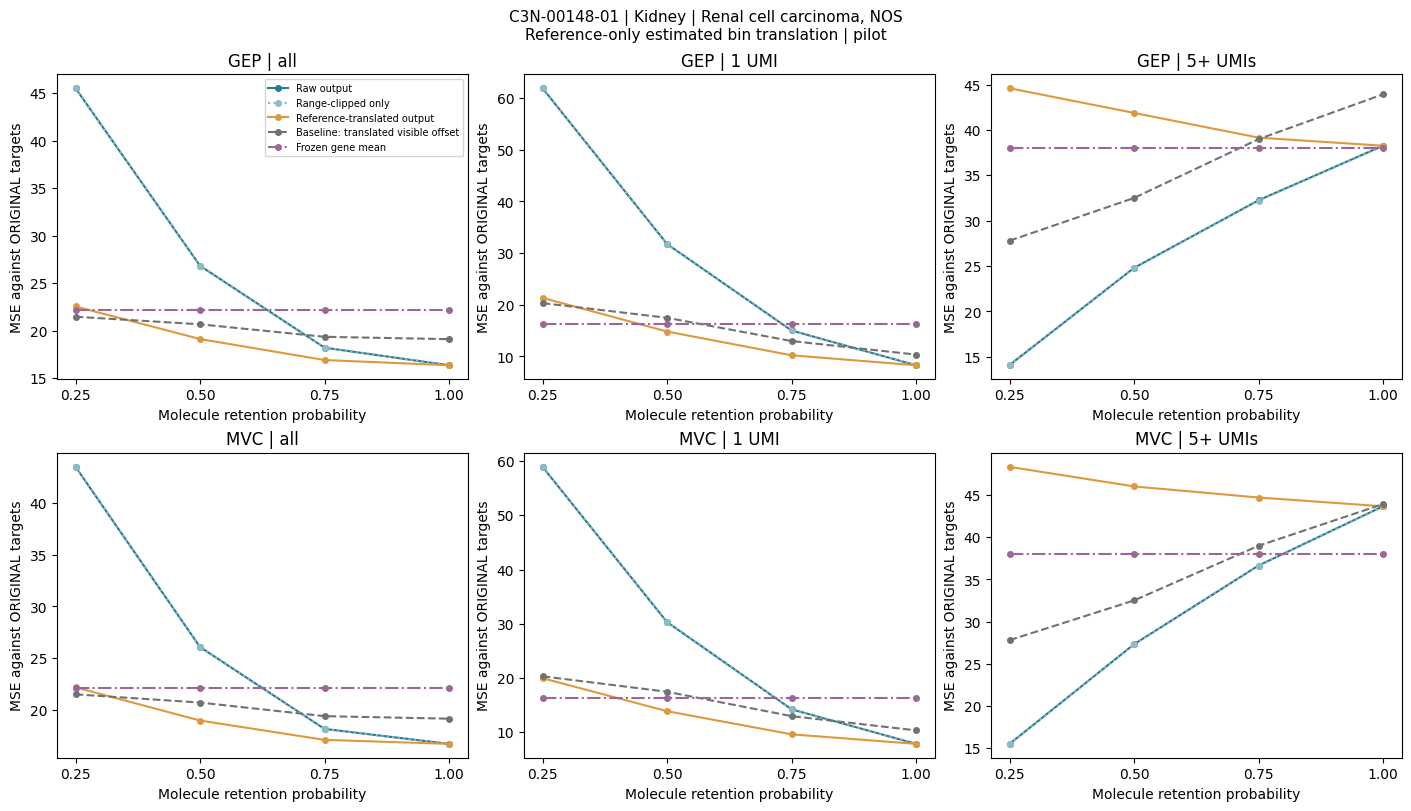

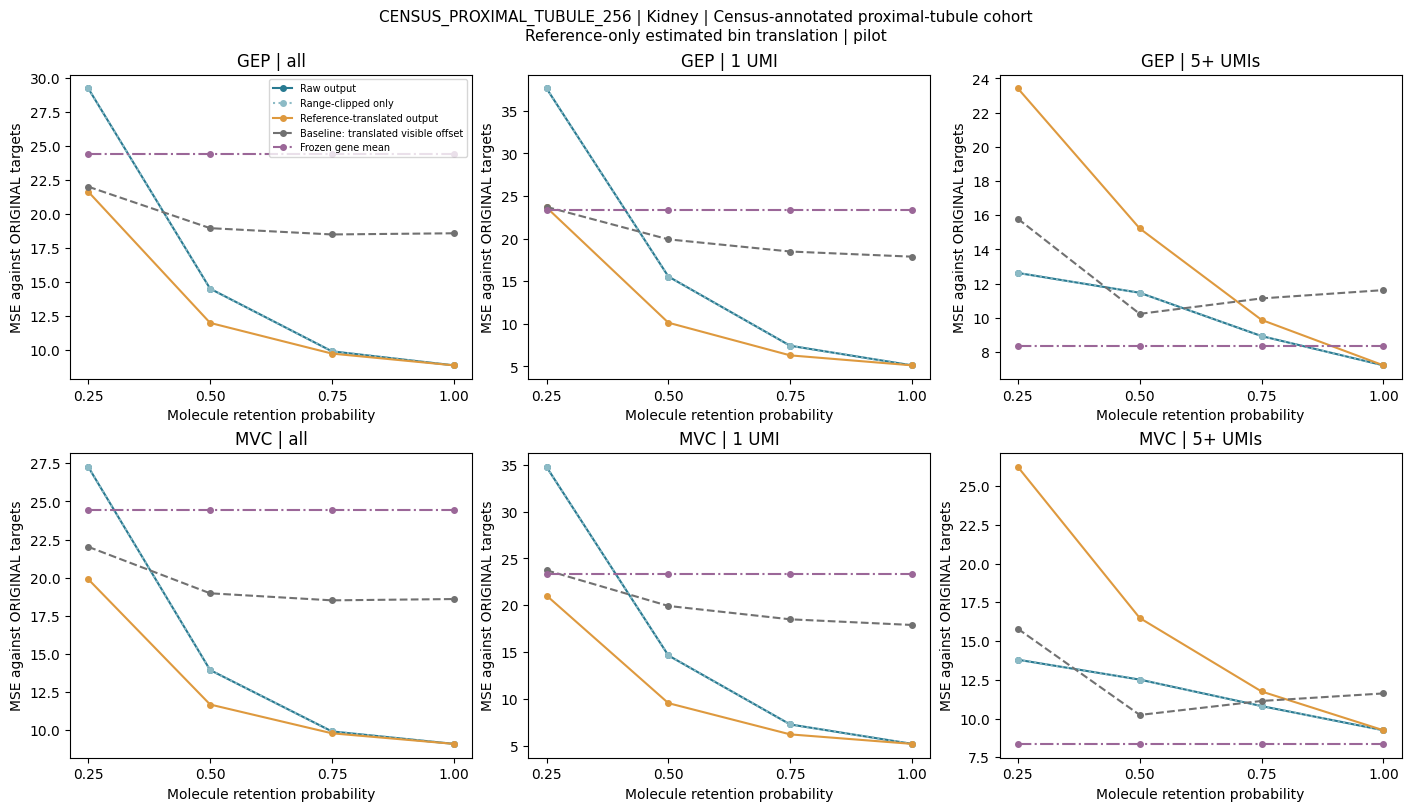

Positive gains mean translation lowered error; compare with the clipping control.


,sample_id,retention,count_group,method,n_cells,mean_MSE,mean_MAE
18,C3N-00148-01,0.25,5+ UMIs,Baseline_raw,8,13.399,3.007
19,C3N-00148-01,0.25,5+ UMIs,Baseline_translated_visible,8,27.794,4.471
20,C3N-00148-01,0.25,5+ UMIs,GEP_range_clipped,8,14.073,3.254
21,C3N-00148-01,0.25,5+ UMIs,GEP_raw,8,14.100,3.300
22,C3N-00148-01,0.25,5+ UMIs,GEP_translated,8,44.593,5.982
...,...,...,...,...,...,...,...
283,CENSUS_PROXIMAL_TUBULE_256,1.00,all,GEP_translated,8,8.891,2.099
284,CENSUS_PROXIMAL_TUBULE_256,1.00,all,Gene_mean_frozen,8,24.408,4.028
285,CENSUS_PROXIMAL_TUBULE_256,1.00,all,MVC_range_clipped,8,9.098,2.103
286,CENSUS_PROXIMAL_TUBULE_256,1.00,all,MVC_raw,8,9.099,2.103


,sample_id,retention,count_group,head,n_cells,mean_gain_vs_raw,mean_gain_beyond_clipping,pct_cells_translation_wins
4,C3N-00148-01,0.25,5+ UMIs,GEP,8,-30.493,-30.521,0.0
5,C3N-00148-01,0.25,5+ UMIs,MVC,8,-32.849,-32.849,0.0
6,C3N-00148-01,0.25,all,GEP,8,22.960,22.960,100.0
7,C3N-00148-01,0.25,all,MVC,8,21.376,21.376,100.0
12,C3N-00148-01,0.50,5+ UMIs,GEP,8,-17.076,-17.103,12.5
13,C3N-00148-01,0.50,5+ UMIs,MVC,8,-18.717,-18.717,0.0
14,C3N-00148-01,0.50,all,GEP,8,7.708,7.707,100.0
15,C3N-00148-01,0.50,all,MVC,8,7.126,7.126,100.0
20,C3N-00148-01,0.75,5+ UMIs,GEP,8,-6.903,-6.943,12.5
21,C3N-00148-01,0.75,5+ UMIs,MVC,8,-8.069,-8.075,0.0


Saved all tables, maps, translated queries and PNG/PDF figures: /home/akash1/scgpt-cna/controlled_expression/results/20261116T201418021732Z_pilot/thinning_followup_20261117T190314133367Z/reference_bin_translation_20261117T190425544534Z


In [8]:
# I — Estimate native-bin -> original-bin translation using REFERENCE cells only.
# Paste after G in scgpt_thinning_followup.ipynb. No scGPT inference is rerun.
# If reopening, run H first to set FOLLOWUP_DIR, then this cell alone.
from pathlib import Path
from datetime import datetime, timezone
import hashlib, importlib.util, json, sys
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.isotonic import IsotonicRegression
import matplotlib.pyplot as plt
from IPython.display import display

assert 'FOLLOWUP_DIR' in globals(), 'Run G in the live notebook, or H to select the saved follow-up.'
tr_root = Path(FOLLOWUP_DIR)
assert (tr_root/'inference_complete.json').is_file(), 'Complete fixed-target inference first.'
tr_f = json.loads((tr_root/'followup_manifest.json').read_text())
tr_source = Path(tr_f['source_run'])
tr_ps = list(map(float, tr_f['retentions']))
tr_repeats = list(map(int, tr_f['thin_seeds']))
tr_masks = list(map(int, tr_f['mask_seeds']))
tr_cap = int(tr_f['visible_cap'])
tr_units = pd.read_csv(tr_root/'evaluation_units.tsv', sep='\t')
tr_base = 'gene_mean_plus_offset'
tr_groups = ['all', '1 UMI', '2–4 UMIs', '5+ UMIs']
tr_out = tr_root/('reference_bin_translation_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
tr_out.mkdir(exist_ok=False)

def tr_hash(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(8*1024**2), b''): h.update(block)
    return h.hexdigest()

assert tr_hash(tr_source/'run_manifest.json') == tr_f['source_manifest_sha256']
tr_parent = json.loads((tr_source/'run_manifest.json').read_text())
tr_prepath = Path.home()/'scgpt-cna/sanity_check/reference_4068d67/scgpt/preprocess.py'
assert tr_hash(tr_prepath) == tr_parent['historical_preprocess_sha256']
tr_spec = importlib.util.spec_from_file_location('translation_pinned_preprocess', tr_prepath)
tr_pre = importlib.util.module_from_spec(tr_spec)
sys.modules[tr_spec.name] = tr_pre
tr_spec.loader.exec_module(tr_pre)
assert tr_pre._digitize.__defaults__ == ('one',)

def tr_bins(row):
    return np.asarray(tr_pre.binning(row.data.copy(), n_bins=51), dtype=float) if row.nnz else np.array([])

def tr_seed(*parts):
    return int(hashlib.sha256('|'.join(map(str, parts)).encode()).hexdigest()[:16], 16)

def tr_thin(matrix, sid, repeat):
    # Reproduce the previous nested sampling, INCLUDING reference rows in the RNG stream.
    current = matrix.astype(np.int64).copy()
    np.testing.assert_array_equal(current.data, matrix.data)
    rng = np.random.default_rng(tr_seed('thinning', sid, repeat))
    profiles = {1.: current.copy()}; previous = 1.
    for p in tr_ps[1:]:
        nxt = current.copy()
        nxt.data = rng.binomial(current.data, p/previous)
        nxt.eliminate_zeros(); nxt.sort_indices()
        profiles[p] = nxt; current = nxt; previous = p
    return profiles

def tr_fit(original, retained, reference_indices, p):
    # Pair each detected reference gene's native thinned bin with its ORIGINAL bin.
    # Equal total weight per reference cell with at least one surviving gene.
    weight = np.zeros(51); total = np.zeros(51)
    n_cells = n_pairs = 0
    for i in reference_indices:
        orig = original.getrow(int(i)); thin = retained.getrow(int(i))
        if not thin.nnz: continue
        native = tr_bins(thin).astype(int)
        positions = np.searchsorted(orig.indices, thin.indices)
        np.testing.assert_array_equal(orig.indices[positions], thin.indices)
        target = tr_bins(orig)[positions]
        w = np.full(thin.nnz, 1./thin.nnz)
        weight += np.bincount(native, weights=w, minlength=51)
        total += np.bincount(native, weights=w*target, minlength=51)
        n_cells += 1; n_pairs += thin.nnz
        if p == 1.: np.testing.assert_array_equal(native, target)
    assert n_cells >= 2 and n_pairs > 0, 'Insufficient surviving reference measurements.'
    x = np.flatnonzero(weight)
    y = total[x]/weight[x]
    if p == 1.:
        # Preserve the unthinned predictions exactly, including continuous out-of-range outputs.
        return None, dict(n_reference_cells=n_cells, n_reference_pairs=n_pairs,
                          native_support_min=float(x.min()), native_support_max=float(x.max()))
    iso = IsotonicRegression(increasing=True, y_min=1., y_max=50., out_of_bounds='clip')
    iso.fit(x, y, sample_weight=weight[x])
    return iso, dict(n_reference_cells=n_cells, n_reference_pairs=n_pairs,
                     native_support_min=float(x.min()), native_support_max=float(x.max()))

def tr_apply(values, calibration):
    values = np.asarray(values, dtype=float)
    assert np.isfinite(values).all()
    return values.copy() if calibration is None else calibration.predict(np.clip(values, 1., 50.))

tr_scores = []; tr_maps = []; tr_audits = []
for tr_sid in tr_units.sample_id:
    src = tr_source/tr_sid
    # Source cache must be the one used by the saved fixed-target experiment.
    expected = json.loads((tr_root/tr_sid/'source_cache_hashes.json').read_text())
    for name, digest in expected.items(): assert tr_hash(src/name) == digest, f'Changed cache: {name}'
    matrix = sparse.load_npz(src/'original_model_counts.npz').tocsr()
    matrix.sort_indices()
    genes = np.load(src/'gene_tokens.npy')
    roles = pd.read_csv(src/'frozen_cell_roles.tsv', sep='\t')
    references = roles.loc[roles.role.eq('reference'), 'cache_index'].to_numpy(int)
    evaluations = roles.loc[roles.role.eq('evaluation'), 'cache_index'].to_numpy(int)
    assert len(references) > 0 and set(references).isdisjoint(evaluations)
    by_cell = roles.set_index('cell_id').cache_index.to_dict()
    with np.load(src/'original_baseline.npz') as b: means = b['means'].copy()
    unit_out = tr_out/tr_sid; unit_out.mkdir()
    with np.load(src/'visible_orders.npz') as orders:
        for repeat in tr_repeats:
            profiles = tr_thin(matrix, tr_sid, repeat)
            for p in tr_ps:
                retained = profiles[p]
                calibration, audit = tr_fit(matrix, retained, references, p)
                tr_maps.append(pd.DataFrame(dict(sample_id=tr_sid, repeat_seed=repeat, retention=p,
                    native_bin=np.arange(1,51), translated_original_bin=tr_apply(np.arange(1,51),calibration))))
                for seed in tr_masks:
                    q = pd.read_csv(tr_root/tr_sid/f'fixed_r{repeat}_p{p:g}_mask{seed}.csv.gz')
                    assert not q.duplicated(['cell_id','gene_token']).any()
                    assert set(q.cell_id).issubset(set(roles.loc[roles.role.eq('evaluation'),'cell_id']))
                    for head in ['GEP','MVC']:
                        q[f'{head}_raw'] = q[head]
                        q[f'{head}_range_clipped'] = np.clip(q[head],1.,50.)
                        q[f'{head}_translated'] = tr_apply(q[head].to_numpy(),calibration)
                        tr_audits.append(dict(sample_id=tr_sid,repeat_seed=repeat,mask_seed=seed,retention=p,head=head,**audit,
                            fraction_predictions_outside_reference_support=float(((q[head]<audit['native_support_min'])|(q[head]>audit['native_support_max'])).mean())))
                    q['Baseline_raw'] = q[tr_base]
                    q['Gene_mean_frozen'] = q['gene_mean']
                    q['Baseline_translated_visible'] = np.nan
                    for cell_id, part in q.groupby('cell_id',sort=False):
                        i = int(by_cell[cell_id]); orig = matrix.getrow(i); row = retained.getrow(i)
                        assert i in evaluations
                        candidate_cols = orig.indices[orders[f'c{i}_s{seed}'][:tr_cap]]
                        visible_pos = np.flatnonzero(np.isin(row.indices,candidate_cols))
                        values = tr_apply(tr_bins(row)[visible_pos],calibration)
                        offset = float(np.mean(values-means[row.indices[visible_pos]])) if len(visible_pos) else 0.
                        # Gene means already use ORIGINAL bins: do not translate them again.
                        q.loc[part.index,'Baseline_translated_visible'] = part.gene_mean.to_numpy()+offset
                    if p == 1.:
                        np.testing.assert_allclose(q.Baseline_translated_visible,q.Baseline_raw,atol=1e-8)
                        for head in ['GEP','MVC']:np.testing.assert_array_equal(q[f'{head}_raw'],q[f'{head}_translated'])
                    methods = ['GEP_raw','GEP_range_clipped','GEP_translated','MVC_raw','MVC_range_clipped','MVC_translated',
                               'Baseline_raw','Baseline_translated_visible','Gene_mean_frozen']
                    assert np.isfinite(q[methods].to_numpy()).all()
                    # Keep a separate export. Previous predictions and targets are never overwritten.
                    q.to_csv(unit_out/f'translated_r{repeat}_p{p:g}_mask{seed}.csv.gz',index=False)
                    for cell_id, part in q.groupby('cell_id',sort=False):
                        g = np.select([part.original_umi.eq(1),part.original_umi.le(4)],['1 UMI','2–4 UMIs'],default='5+ UMIs')
                        for group in tr_groups:
                            s = part if group=='all' else part.loc[g==group]
                            if s.empty:continue
                            y = s.target_bin.to_numpy(float)
                            for method in methods:
                                e = s[method].to_numpy()-y
                                tr_scores.append(dict(sample_id=tr_sid,cell_id=cell_id,repeat_seed=repeat,mask_seed=seed,
                                    retention=p,count_group=group,method=method,n_queries=len(s),MSE=np.square(e).mean(),MAE=abs(e).mean()))
                    print(tr_sid,'repeat',repeat,'retention',p,'mask',seed,'translated; model not rerun',flush=True)
            del profiles

tr_task_scores = pd.DataFrame(tr_scores)
tr_keys = ['sample_id','retention','count_group','method']
tr_repeat_scores = tr_task_scores.groupby(tr_keys+['cell_id','repeat_seed'],as_index=False)[['MSE','MAE']].mean()
tr_cell_scores = tr_repeat_scores.groupby(tr_keys+['cell_id'],as_index=False)[['MSE','MAE']].mean()
tr_summary = tr_cell_scores.groupby(tr_keys,as_index=False).agg(n_cells=('cell_id','nunique'),mean_MSE=('MSE','mean'),mean_MAE=('MAE','mean'))
# Raw/translated comparisons are paired WITHIN each cell, not different groups of queries.
tr_gain_rows=[]
for head in ['GEP','MVC']:
    k=['sample_id','retention','count_group','cell_id']
    raw=tr_cell_scores.loc[tr_cell_scores.method.eq(f'{head}_raw'),k+['MSE']].rename(columns={'MSE':'raw_MSE'})
    clipped=tr_cell_scores.loc[tr_cell_scores.method.eq(f'{head}_range_clipped'),k+['MSE']].rename(columns={'MSE':'clipped_MSE'})
    translated=tr_cell_scores.loc[tr_cell_scores.method.eq(f'{head}_translated'),k+['MSE']].rename(columns={'MSE':'translated_MSE'})
    z=raw.merge(clipped,on=k,validate='one_to_one').merge(translated,on=k,validate='one_to_one')
    z['head']=head;z['gain_vs_raw']=z.raw_MSE-z.translated_MSE;z['gain_vs_clipping']=z.clipped_MSE-z.translated_MSE
    tr_gain_rows.append(z)
tr_cell_gains=pd.concat(tr_gain_rows,ignore_index=True)
tr_gains=tr_cell_gains.groupby(['sample_id','retention','count_group','head'],as_index=False).agg(
    n_cells=('cell_id','nunique'),mean_gain_vs_raw=('gain_vs_raw','mean'),mean_gain_beyond_clipping=('gain_vs_clipping','mean'),
    pct_cells_translation_wins=('gain_vs_raw',lambda x:100*x.gt(0).mean()))
for name,frame in [('translation_task_scores',tr_task_scores),('translation_cell_scores',tr_cell_scores),('translation_summary',tr_summary),
                   ('translation_cell_gains',tr_cell_gains),('translation_gains',tr_gains),
                   ('reference_bin_maps',pd.concat(tr_maps,ignore_index=True)),('reference_mapping_audit',pd.DataFrame(tr_audits))]:
    frame.to_csv(tr_out/f'{name}.csv',index=False)
(tr_out/'translation_manifest.json').write_text(json.dumps(dict(source_followup=str(tr_root),
    training='Paired native/original bins of surviving genes in reference cells ONLY; equal reference-cell weights',
    translation='Monotonic isotonic calibration per specimen, thinning repeat and retention; p=1 identity',
    baseline='Original gene means + offset computed from translated visible bins',
    limitations=['Estimated conditional bin calibration, not an exact inverse or biological denoising',
      'Mapping trained on detected reference genes; original evaluation queries include undetected genes',
      'Cell-specific ties and count uncertainty prevent a universal invertible bin mapping',
      'Translation of a regression mean is a heuristic; it is not the mean of translated uncertain expression',
      'Original full-profile binning uses hidden expression, as in the parent benchmark']),indent=2))
for sid in tr_units.sample_id:
    u=tr_units.set_index('sample_id').loc[sid]
    fig,axes=plt.subplots(2,3,figsize=(14,8),constrained_layout=True)
    for r,head in enumerate(['GEP','MVC']):
        for c,group in enumerate(['all','1 UMI','5+ UMIs']):
            s=tr_summary.loc[tr_summary.sample_id.eq(sid)&tr_summary.count_group.eq(group)]
            for method,label,color,style in [(f'{head}_raw','Raw output','#287A91','-'),
                 (f'{head}_range_clipped','Range-clipped only','#8DBBC6',':'),
                 (f'{head}_translated','Reference-translated output','#DE993E','-'),
                 ('Baseline_translated_visible','Baseline: translated visible offset','#717171','--'),
                 ('Gene_mean_frozen','Frozen gene mean','#9B6798','-.')]:
                t=s.loc[s.method.eq(method)].sort_values('retention')
                axes[r,c].plot(t.retention,t.mean_MSE,'o',ls=style,color=color,label=label,ms=4)
            axes[r,c].set(title=f'{head} | {group}',xlabel='Molecule retention probability',ylabel='MSE against ORIGINAL targets',xticks=sorted(tr_ps))
    axes[0,0].legend(fontsize=7)
    fig.suptitle(f"{sid} | {u['primary_site']} | {u['diagnoses.0.primary_diagnosis']}\nReference-only estimated bin translation | {tr_f['mode']}",fontsize=11)
    fig.savefig(tr_out/f'translation_{sid}.png',dpi=220,bbox_inches='tight')
    fig.savefig(tr_out/f'translation_{sid}.pdf',bbox_inches='tight')
    plt.show();plt.close(fig)
print('Positive gains mean translation lowered error; compare with the clipping control.')
display(tr_summary.loc[tr_summary.count_group.isin(['all','5+ UMIs'])].round(3))
display(tr_gains.loc[tr_gains.count_group.isin(['all','5+ UMIs'])].round(3))
print('Saved all tables, maps, translated queries and PNG/PDF figures:',tr_out)
